## Pattern 1 — Sliding Window (Fixed Size)

**Importance:** ★★★★★

### Story
You’re watching a train pass a window. Each carriage rolls into view as the last one disappears. You never need to go back and recount — you just add what’s entering and subtract what’s leaving. That running adjustment is the whole trick. The window is always exactly `k` elements wide, and at every position you already know your total — you’re just swapping one element for another. No loops within loops, no starting over. One pass through the array, one running sum, and the answer assembles itself.

### When to Use
*   Fixed-size subarray questions
*   Maximum/average over every window of size `k`
*   Streaming or online data over a fixed window

### Core Idea
Keep a running total of exactly `k` elements. On each step, add the new element coming in from the right and subtract the one falling off the left.

### Pitfalls
*   Forgetting to subtract the element that just left the window
*   Getting the window boundaries wrong --- especially off-by-one on the starting index

### Mini Example
**Example:** `arr = [2,1,5,2,3,2]`, `k = 2`. The windows give sums `3, 6, 7, 5, 5`. Best is `7`.

## ![][image1]

[image1]: <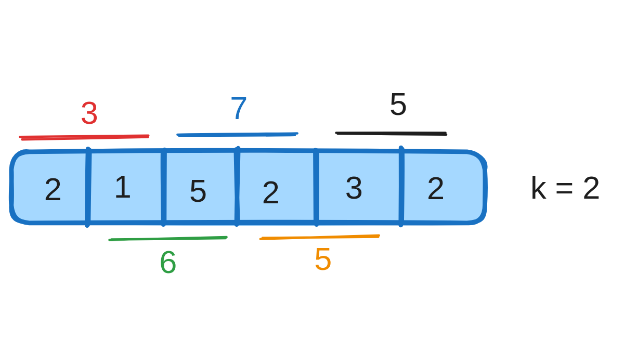>

In [ ]:
def max_sum_fixed_window(arr: list[int], k: int) -> int:
    """
    Calculates the maximum sum of a contiguous subarray of fixed size k
    using the Sliding Window pattern.
    Time Complexity: O(N)
    Space Complexity: O(1)
    """
    n = len(arr)
    
    # Edge Case Check: If K is larger than the array, it's impossible.
    if k > n:
        return 0 

    # 1. Initialization: Calculate the sum of the very first window (i=0 to k-1)
    current_window_sum = 0
    for i in range(k):
        current_window_sum += arr[i]
    
    # Initialize max_sum with the sum of the first window
    max_sum = current_window_sum

    # 2. Sliding: Start the window from the element that *enters* the window
    # We start the loop at index 'k' because the first k elements were used for initialization.
    for i in range(k, n):
        # i is the index of the element ENTERING the window (the new right edge)
        element_entering = arr[i]
        
        # The element LEAVING the window is always K steps behind the current element.
        # The window size is K, so the index to drop is (i - k).
        element_leaving = arr[i - k]
        
        # The CORE SLIDING STEP (O(1) operation):
        current_window_sum = current_window_sum - element_leaving + element_entering
        
        # 3. Update the maximum sum seen so far
        max_sum = max(max_sum, current_window_sum)
        
    return max_sum

# Test Case
arr = [3, 5, 8, 1, 10, 2]
k = 3
result = max_sum_fixed_window(arr, k)

print(f"The array is: {arr}")
print(f"The window size (K) is: {k}")
print(f"The maximum sum found is: {result}")


: 

In [ ]:
def fixed_size(arr, max_size):
    if len(arr) < max_size:
        return 0

    current_state = 0  # Can be a sum, hash map, set, etc.
    max_weight = float('-inf')
    tail = 0

    for head in range(len(arr)):
        # 1. Add the right element to the window state
        current_state += arr[head]

        # 2. Check if we have hit the required window size
        if (head - tail + 1) == max_size:
            # 3. Update your overall answer tracking
            max_weight = max(max_weight, current_state)

            # 4. Remove the leftmost element from the state before sliding
            current_state -= arr[tail]
            tail += 1  # Slide the window forward

    return max_weight
fixed_size([2,1,5,2,3,2], 2)


In [ ]:
def max_sum(arr, max_eat):
  initial_best_eat = sum(arr[:max_eat])
  best_eat = initial_best_eat
  # max_sum = window_sum
  for head in range(max_eat, len(arr)):
    curr_best_eat = best_eat - arr[head-max_eat] + arr[head]
    best_eat = max(curr_best_eat, best_eat)
  return best_eat

max_sum([2,1,5,2,3,2], 2)

## Pattern 2 — Sliding Window (Expand & Shrink)

**Importance:** ★★★★★

### Story
Imagine stretching a rubber band across a string of characters. You keep stretching it rightward — greedily pulling in more — until something breaks your rule. The moment it breaks, you squeeze the left side inward, releasing characters one by one until the window is valid again. Then you stretch right again. You never move right backward and you never move left backward. The window breathes — expanding when it can, contracting when it must. Every time you have a valid window, you check if it’s the best you’ve seen. The answer is hiding in one of those valid snapshots.

### When to Use
*   Longest substring with no repeated characters
*   Smallest window that contains every required character
*   Any substring or subarray whose valid size changes based on a rule

### Core Idea
Two pointers define the window. Move right forward on every step. When the window breaks your condition, push left forward until it’s valid again. Track the best size seen.

### Pitfalls
*   Stopping the left pointer too early --- the window needs to shrink until it’s fully valid again
*   Updating the best answer only at the end, instead of after every valid expansion

### Mini Example
**Example:** `s = 'abcabcbb'` → longest substring with all unique characters is `'abc'`, length 3. The window expands as far as it can, and only pulls back when the constraint breaks.

![][image1]

[image1]: <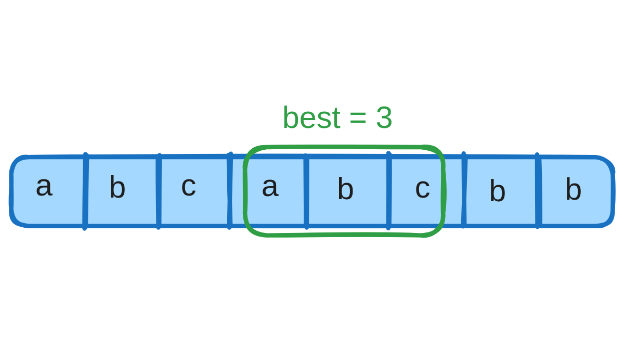>

In [ ]:
def longest_unique(s):
  tail = 0
  env = set()
  best_eat = 0

  for head, eatable in enumerate(s):
    while eatable in env:
      env.remove(s[tail])
      # did below mistake
      # seen.remove(char)
      tail += 1
    env.add(eatable)
    best_eat = max(best_eat, head - tail + 1)

  return best_eat

longest_unique(s="abcabcbb")

## Pattern 3 — Sliding Window + Frequency Constraint

**Importance:** ★★★★★

### Story
You’re hiring a team of up to k contractors to fill gaps in your crew. Your crew has a star player — the most common character — and everyone else needs to be replaced to match them. As long as the number of replacements needed stays within budget (k), you keep the window open and keep growing it. The moment you’d need more than k replacements to make the window uniform, you slide the left side forward to release one worker. The key is tracking the most frequent character in the window — that’s your anchor. The rest of the window is just slots you’re allowed to change. Every valid window size is a candidate for the best answer.

### When to Use
*   Longest substring problems that involve replacements or character limits
*   Checking if a permutation or anagram exists in a string
*   Any problem where the window validity depends on character counts
*   Subarray or substring problems with a frequency-based condition

### Core Idea
Keep a frequency map of the characters in the window. Every time the window violates the constraint, move the left pointer forward and update the map until things are valid again.

### Pitfalls
*   Shrinking the window without updating the frequency map
*   Getting the constraint check wrong --- test it on a small example by hand first
*   Mixing this up with the fixed-size window --- the key difference is that size here is not predetermined

### Mini Example
**Example:** `s = 'aababb'` → longest repeating character replacement is `'aaaa'`, length 4
where `k = 1`.

![][image1]

[image1]: <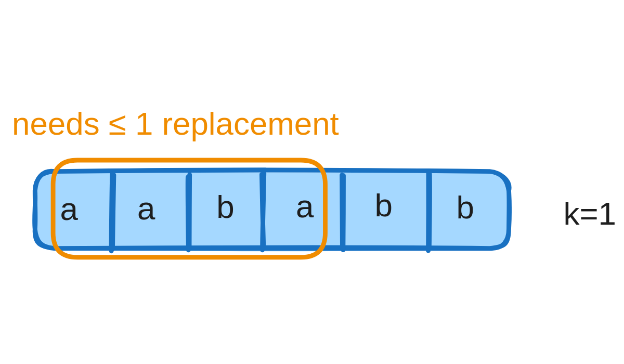>

In [ ]:
def longest_repeating_char(env:str, k:int) -> int:
  freq = {}
  tail = 0
  best = 0
  max_freq = 0

  for head, eatable in enumerate(env):
    freq[eatable] = freq.get(eatable, 0) + 1
    max_freq = max(max_freq, freq[eatable])

    while (head - tail + 1) - max_freq > k:
      freq[env[tail]] -= 1
      head += 1
    best = max(best, head - tail + 1)

  return best

longest_repeating_char(s="aababb", k=1)


## Pattern 4 — Two Pointers (Opposite Ends)

**Importance:** ★★★★★

### Story
Two people are walking toward each other on a number line — one starting at the smallest value, one at the largest. At every step they check: does their combined value hit the target? If the total is too big, the person on the right steps inward — they can only get smaller. If the total is too small, the person on the left steps inward — they can only get bigger. Because the array is sorted, every single move rules out an entire row of dead-end pairings. They keep walking toward each other, eliminating impossibilities with every step, until they either find the answer or meet in the middle and confirm it isn’t there.

### When to Use
*   Sorted arrays where you’re looking for a pair matching a condition
*   Pair-sum problems --- find two numbers that hit a target
*   Any problem where you can eliminate candidates from both ends simultaneously

### Core Idea
Left pointer starts at index 0, right pointer at the last index. Sum them. Too small? Advance left. Too big? Pull right back. Keep going until they meet.

### Pitfalls
*   Using this on an unsorted array --- it only works because sorting guarantees directionality

### Mini Example
**Example:** `arr = [1,2,3,4,6]`, `target = 6` → indices `[1,3]` (2 + 4 = 6).

![][image1]

[image1]: <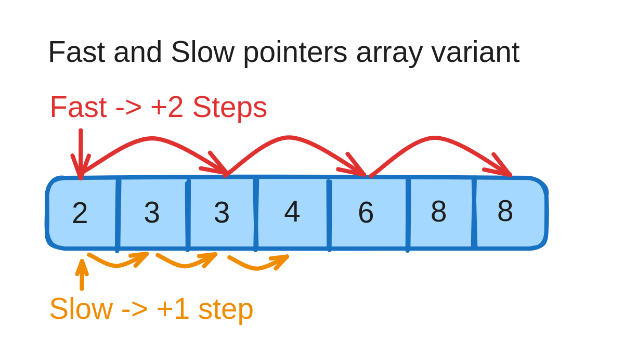>

In [ ]:
def two_sum_sorted(arr:list, target:int)->list:
  tail = 0
  head = len(arr) - 1
  while tail < head:
    curr_sum = arr[head] + arr[tail]
    if curr_sum == target:
      return [tail, head]
    elif curr_sum < target:
      tail += 1
    else:
      head -=1
  return None

two_sum_sorted(arr=[1,2,3,4,6], target=6)

In [ ]:
def pair_sum(arr:list, target:int)->list:
  for i in range(len(arr)):
    curr = arr[i]
    arrSlice = arr[i+1:]
    diff_for_target = target - curr
    if diff_for_target in arrSlice:
      return [i, arrSlice.index(diff_for_target) + i + 1]
  return None


pair_sum(arr=[1,2,3,4,6], target=6)

## Pattern 5 — Two Pointers (Fast–Slow)

**Importance:** ★★★★★

### Story
Two runners set off from the same starting line. One jogs — one step at a time. The other sprints — two steps to every one. On a straight track, the sprinter hits the finish line first and that’s that. But on a circular track with no exit, the sprinter keeps looping. And because they’re moving at different speeds on the same loop, they will eventually land on the same spot at the same time. When they meet, you’ve confirmed the loop exists. To find the middle of a straight list, you use the same trick: when the sprinter hits the end, the jogger is standing exactly at the halfway point.

### When to Use
*   Detecting cycles in linked lists
*   Finding the middle of a linked list
*   Cycle-related problems in sequences

### Core Idea
Move slow one step, fast two steps. If they ever land on the same node, you found a cycle. To find the middle, just stop when fast hits null --- slow will be at the midpoint.

### Pitfalls
*   Advancing fast without checking `fast && fast.next` first — this crashes on non-cyclic lists
*   Getting stuck in an infinite loop by not advancing both pointers on every iteration

### Mini Example
**Example:** `1 → 2 → 3 → 4 → 2` (cycle) → returns true; a non-cyclic list returns false.

![][image1]

[image1]: <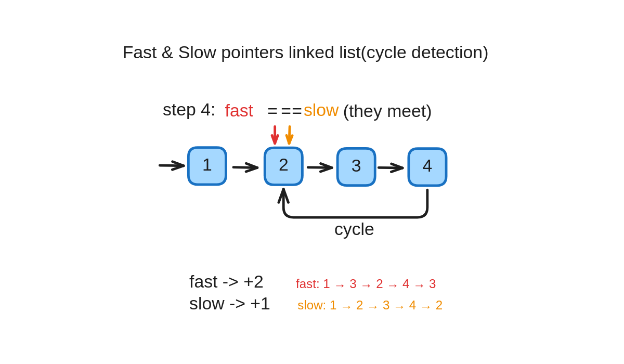>

In [ ]:
class Node:
  def __init__(self, value):
    self.value = value
    self.next = None
# -------------------------
# Example 1: Cyclic List

# 1 -> 2 -> 3 -> 4

#      ^         |

#      |_________|

n1 = Node(1)
n2 = Node(2)
n3 = Node(3)
n4 = Node(4)
n1.next = n2
n2.next = n3
n3.next = n4
n4.next = n2     # Creates a cycle

In [ ]:
def has_cycle(head:Node)->bool:
  slow = fast = head
  while fast and fast.next:
    slow = slow.next
    fast = fast.next.next
    if slow == fast:
      return True
  return False
has_cycle(n1)

## Pattern 6 — Prefix Sum

**Importance:** ★★★★

### Note:
In practice, we often use an extra prefix element `P[0] = 0`.
This allows easy range sum queries:
*   `P[i] = sum of A[0..i-1]`
*   `rangeSum(l, r) = P[r+1] - P[l]`

The diagram above shows the running sum intuition.

### Story
You’re hiking a trail and someone planted mile markers every few steps — not just showing your current position, but your total distance from the trailhead. Want to know the distance between marker 3 and marker 7? Subtract. No walking required, no recounting. That’s prefix sum. You pay one pass up front to plant all the markers. After that, every range query — no matter how many you have — costs exactly one subtraction. The power is in the precomputation. The trick that catches people is the off-by-one: `prefix[i]` stores the sum of everything before index `i`, so a leading zero makes every query clean and consistent.

### When to Use
*   Fast range sum queries without recomputing
*   Counting subarrays that hit a specific sum, often paired with a hash map
*   Turning `O(n²)` nested sum loops into a single `O(n)` pass

### Core Idea
Build an array where `prefix[i]` stores the sum of `arr[0]` through `arr[i-1]`. The sum of any subarray `[L, R]` becomes `prefix[R+1]` minus `prefix[L]` — a single subtraction.

### Pitfalls
*   Off-by-one errors --- it’s easy to mix up whether `prefix[i]` includes `arr[i]` or not. Use a leading 0 and be consistent.

### Mini Example
**Example:** `arr = [2,3,7,5]`, `prefix = [0,2,5,12,17]`. Sum of `[1,2]` = 10 via `prefix[3] - prefix[1]`.

![alt text](image.png)

In [ ]:
def prefix_sum(arr:list, sum_for:list):
  # compute prefix array
  # get range from sum_for
  # sum = head + 1 - tail
  prefix = [0]
  for i in range(len(arr)):
    prefix.append(prefix[i] + arr[i])
  print(prefix)
  x, y = sum_for
  return prefix[y + 1] - prefix[x]

prefix_sum(arr=[2,3,7,5], sum_for=[1,2])


## Pattern 7 — Kadane's Algorithm

**Importance:** ★★★★

### Story
You continuously decide whether to extend a subarray or start fresh. This converts nested subarray checks into a single pass.

### When to Use
*   Maximum subarray sum
*   Problems involving the best contiguous range
*   Circular array variations

### Core Idea
`current_max = max(current_element, current_max + current_element)`

### Pitfalls
*   Forgetting negative-only arrays
*   Resetting at the wrong time

### Mini Example
**Example:** `nums = [-2,1,-3,4,-1,2,1,-5,4]` → maximum subarray sum is `6` (`[4,-1,2,1]`)

![][image1]

[image1]: <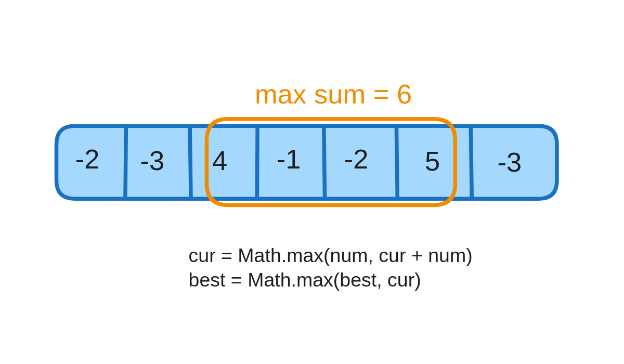>

In [ ]:
def max_subarray_sum(nums: list) -> int:
    if not nums:
        return 0

    max_so_far = nums[0]
    current_max = nums[0]

    for i in range(1, len(nums)):
        current_max = max(nums[i], current_max + nums[i])
        max_so_far = max(max_so_far, current_max)

    return max_so_far

# Example Usage:
nums_example = [-2, 1, -3, 4, -1, 2, 1, -5, 4]
print(f"The maximum subarray sum for {nums_example} is: {max_subarray_sum(nums_example)}")

## Pattern 8 — Hash Map

**Importance:** ★★★★

### Story
Think of a hash map as a counting dictionary. You toss items into a bag and maintain counts of each type.

### When to Use
*   Anagram checks
*   Frequency-based conditions
*   Finding majority elements, duplicates, etc.

### Core Idea
Use an object or a Map to count occurrences, then query those counts to apply conditions.

### Pitfalls
*   Not initializing missing keys correctly
*   Forgetting to decrement when using counts bidirectionally

### Mini Example
**Example:** `'xyyz'` and `'yxzy'` → same frequency of each character → anagrams.

![][image1]

[image1]: <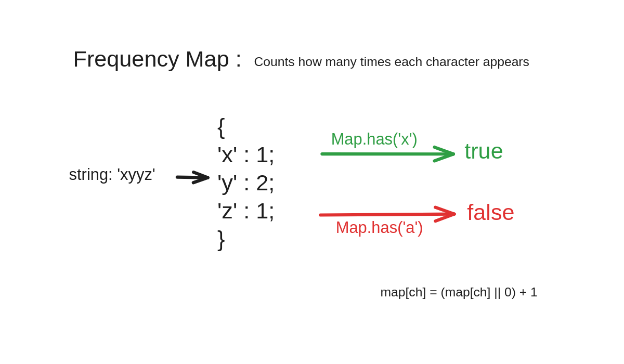>

In [ ]:
from collections import Counter
# from collection import defaultdict
def is_anagram(str1, str2):
  freq = Counter(str1)
  for char in str2:
    if freq[char] == 0:
      return False
    freq[char] -= 1
  return True

is_anagram(str1="xyyz", str2="yxzy")

## Pattern 9 — Basic Stack

**Importance:** ★★★★

### Story
A stack is like a stack of plates—last in, first out. Great for tracking nested structure.

### When to Use
*   Parentheses validation
*   Undo operations
*   Evaluating expressions (like RPN)

### Core Idea
Push when you see an opener; pop and check when you see a closer.

### Pitfalls
*   Returning true too early before verifying the stack is empty
*   Forgetting edge cases like empty strings

### Mini Example
**Example:** `s = '(())[]'` → valid; `s = '([)]'` → invalid.

![][image1]

[image1]: <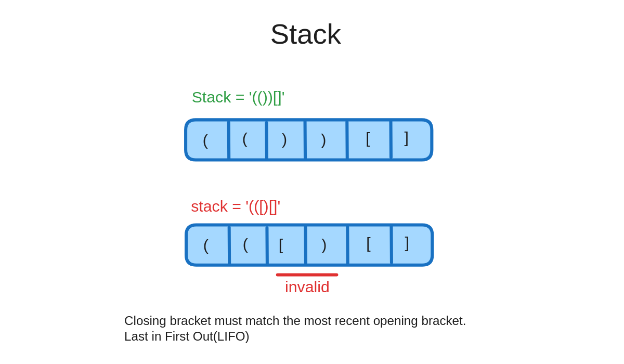>

In [ ]:
def isValid(s:str)->bool:
  pairs = {
      ')':'(',
      ']':'[',
      '}':'{'
  }
  stack = []
  for char in s:
    if char in pairs: # Check if the character is a closing bracket
      if not stack or stack.pop() != pairs[char]: # If stack is empty or top doesn't match
        return False
    else:
      stack.append(char) # It's an opening bracket, push it to stack
  return len(stack) == 0


isValid(s = '(())[]')


## Pattern 10 — Monotonic Stack

**Importance:** ★★★★★

### Story
A monotonic stack keeps its elements in increasing or decreasing order. This is perfect for problems like 'next greater element'. Imagine 6 kids standing in a line, and each kid has a height. Every kid asks the same question: "Looking at the kids behind me, who is the first kid taller than me?"

### When to Use
*   Next greater element
*   Daily temperatures
*   Largest rectangle in a histogram

### Core Idea
While the current element violates the stack's monotonic property, pop from the stack and resolve that index.

### Pitfalls
*   Keeping tracking of heights instead of indexes since there can be duplicate heights in the array that doesn't work
*   Forgetting to process the remaining stack after the main loop
*   Mixing up increasing vs decreasing configurations

### Mini Example
**Example:** `nums = [2, 7, 3, 5, 1, 6]` → next greater `=[7, -1, 5, 6, 6, -1]`.

![][image1]

[image1]: <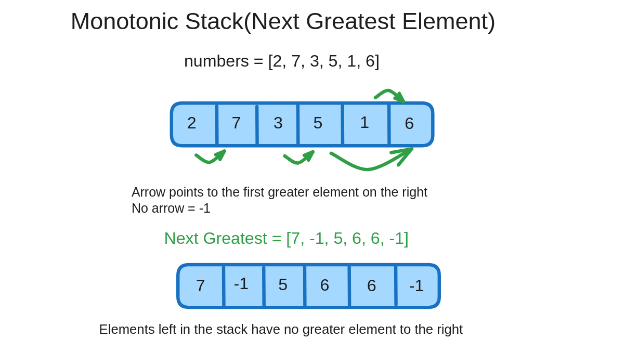>

In [ ]:
def next_greater(heights):
    n = len(heights)
    answer = [-1] * n      # everyone starts as "nobody taller found yet"
    waiting_list = []      # this is our notepad — holds INDICES of kids still waiting

    for i in range(n):
        # i = the current kid we're looking at (walking down the line)

        # Keep checking: is current kid TALLER than the last kid on our waiting list?
        while waiting_list and heights[i] > heights[waiting_list[-1]]:
            # Yes! That waiting kid finally found their answer.
            waiting_kid_index = waiting_list.pop()   # cross them off the list
            answer[waiting_kid_index] = heights[i]   # record who's taller than them

        # Either the list is empty, or the last kid on it is taller than us.
        # Either way, WE now join the waiting list.
        waiting_list.append(i)

    return answer


heights = [2, 7, 3, 5, 1, 6]
print(next_greater(heights))

## Pattern 11 — Reverse Linked List

### Story
Picture a treasure hunt: cards on a table, each with a clue and an arrow pointing to the next card. Card A → Card B → Card C → Card D → end.

To reverse it, you walk down the cards one at a time and flip each arrow to point backward instead of forward. The catch: once you flip an arrow, you lose track of what came next — so before flipping, you peek ahead and remember the next card first.

So for each card:

*   Remember the next card (sticky note).
*   Flip this card's arrow to point at the previous card.
*   Move to the next card (from the sticky note).
*   Repeat until no cards are left.

### When to Use
*   Reversing an entire list
*   As a subroutine in more complex problems (like reversing in k-groups)

### Core Idea
Iterate with three pointers: prev, curr, next. Flip curr.next to prev, then move all three forward.

### Pitfalls
*   Losing the next pointer before reassigning
*   Not returning the new head (prev at the end)

### Mini Example
**Example:** `Card A → Card B → Card C → Card D → end.` becomes `Card D → Card C → Card B → Card A → end.`

![][image1]

[image1]: <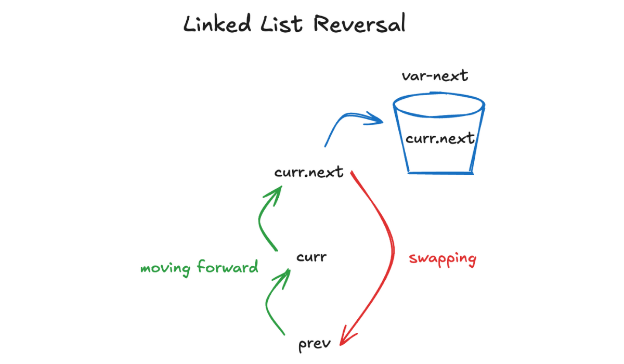>

In [ ]:
def list_reversal(head):
  next = None
  curr = head
  prev = None

  while(curr):
    next = curr.next

    """
    curr.next = prev
    prev = curr
    curr = next
    """
    next, curr.next, prev, curr =curr.next, prev, curr, next
  return prev

def print_list(head):
    curr = head
    while curr:
        print(curr.data, end=" -> ")
        curr = curr.next
    print("None")

class Node:
  def __init__(self, data):
    self.data = data
    self.next = None

head = Node("A")
head.next = Node("B")
head.next.next = Node("C")
head.next.next.next = Node("D")

print("Original List",end=" ")
print_list(head)
head = list_reversal(head)
print("Reversed List",end=" ")
print_list(head)


## Pattern 12 — Merge Two Sorted Lists

### Story
Think of two sorted lanes of traffic merging into a single sorted lane. You always pick the smaller front car.

### When to Use
*   Merging two sorted lists
*   Base for 'merge k sorted lists' and merge sort on linked lists

### Core Idea
Use a dummy head and a tail pointer. Repeatedly choose the smaller node from the two lists and advance that list.

### Pitfalls
*   Forgetting to attach the remaining nodes after one list finishes

### Mini Example
**Example:** `[1,3,5]` merged with `[2,4,6]` → `[1,2,3,4,5,6]`.

![][image1]

[image1]: <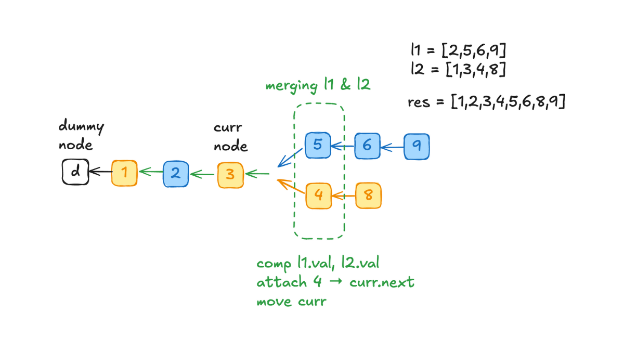>

In [ ]:
class Node:
  def __init__(self, data):
    self.data = data
    self.next = None

def print_nodes(head):
  while(head):
    print(head.data, end="-->")
    head = head.next
  print("None")

l1 = Node(2)
l1.next = Node(5)
l1.next.next = Node(6)
l1.next.next.next = Node(9)

print("l1 :", print_nodes(l1))

l2 = Node(1)
l2.next = Node(3)
l2.next.next = Node(4)
l2.next.next.next = Node(8)
print('Final nodes')
print_nodes(l2)

def merge_sorted_lists(l1, l2):
  dummy = Node(-1)
  tail = dummy

  while(l1 and l2):
    if(l1.data < l2.data):
      tail.next = l1
      l1 = l1.next
    else:
      tail.next = l2
      l2 = l2.next
    tail = tail.next
  tail.next = l1 or l2
  return dummy.next

print('Final nodes')
print_nodes(merge_sorted_lists(l1, l2))

## Pattern 13 — Fast–Slow Linked List

**Importance:** ★★★★★

### Story
Picture a turtle and a rabbit running around a circular track. The turtle moves one step per turn, the rabbit moves two. If the track forms a loop, the rabbit will eventually catch the turtle. This simple intuition helps detect cycles, find the middle of a list, or determine intersection points.

### When to Use
*   Detecting linked list cycles
*   Finding the middle node
*   Cycle entry detection (Floyd’s algorithm)

### Core Idea
Use two pointers: `slow = slow.next` and `fast = fast.next.next`. If they ever meet, a cycle exists.

### Pitfalls
*   Not checking `fast && fast.next` before advancing
*   Confusing the meeting point with the cycle start (requires a second phase)

### Mini Example
**Example:** In `1→2→3→4→2` (cycle), slow and fast eventually meet.

![][image1]

[image1]: <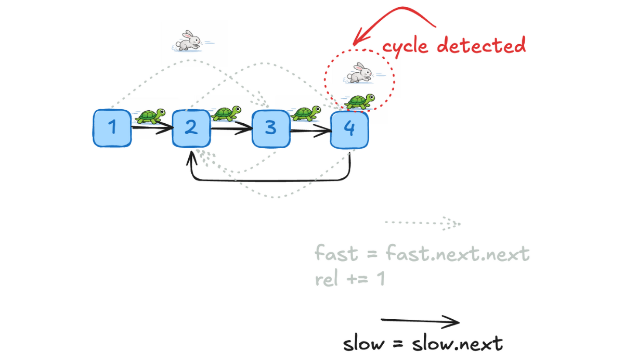>

In [ ]:
def hasCycle(head):
  slow = fast = head
  while(fast and fast.next):
    slow = slow.next
    fast = fast.next.next
    if slow == fast:
      return True
  return False

class Node:
  def __init__(self, val):
    self.val = val
    self.next = None

a = Node(1)
b = Node(2)
c = Node(3)
d = Node(4)
e = Node(5)

a.next = b
b.next = c
c.next = d
d.next = e
e.next = b

print(hasCycle(a))



## Pattern 14 — Tree DFS — Post-Order Combine

**Importance:** ★★★★★

### Story
Think of climbing a tree and gathering results from each child before deciding the parent. This bottom‑up strategy is perfect when a parent’s value depends on its children’s values, such as computing height, valid BST checks, path sums, or diameter.

### When to Use
*   Tree height/depth calculations
*   Balanced tree checks
*   Aggregating results from subtree computations

### Core Idea
Process left subtree → right subtree → compute and return value for the current node.

### Pitfalls
*   Forgetting the null base case
*   Returning wrong values when combining child results

### Mini Example
**Example:** A balanced tree with nodes `[3,9,20,15,7]` has depth 3.

![][image1]

[image1]: <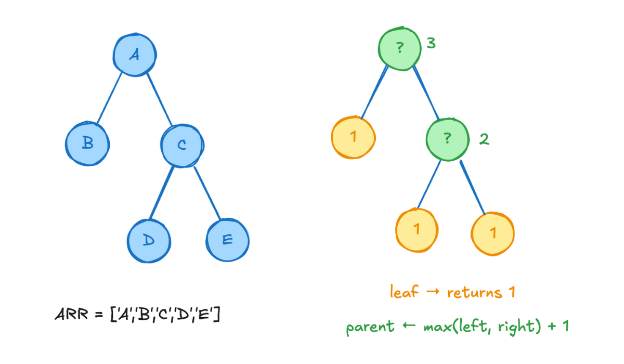>

In [ ]:
def maxDepth(root):
  if not root: return 0
  return 1 + max(maxDepth(root.left), maxDepth(root.right))

class Tree:
  def __init__(self, value):
    self.value = value
    self.right = None
    self.left = None

A = Tree("A")
B = Tree("B")
C = Tree("C")
D = Tree("D")
E = Tree("E")

A.right = C
A.left = B
C.left = D
C.right = E

print(maxDepth(A))


In [ ]:
def dfs_iterative(tree):
    if tree is None:
        return []
    result = []
    stack = [tree]

    while stack:
        node = stack.pop()          # pop from the END now
        result.append(node.data)
        if node.left is not None:
            stack.append(node.left)
        if node.right is not None:
            stack.append(node.right)

    return result

class Tree:
  def __init__(self, data):
    self.data = data
    self.right = None
    self.left = None

A = Tree("A")
B = Tree("B")
C = Tree("C")
D = Tree("D")
E = Tree("E")

A.right = C
A.left = B
C.left = D
C.right = E
dfs_iterative(A)

## Pattern 15 — Binary Tree Path Pattern

**Importance:** ★★★★★

### Story
Imagine walking down a tree carrying a bag of coins (target).

At every node:
*   You pay the node’s value
*   If you reach a leaf, check: Is my bag exactly empty?

Pattern is particularly useful for problems that require tracking values from root to leaf. Each recursive call carries path state downward.

### When to Use
*   Root-to-leaf problems
*   Path sum calculations
*   Tree path construction

### Core Idea
*   Pass path or sum into recursion.
*   Check the condition at leaf nodes.

### Pitfalls
*   Confusing this with generic DFS
*   Forgetting to backtrack the path state

### Mini Example
Path Sum, All Paths, Max Path Sum

![][image1]

[image1]: <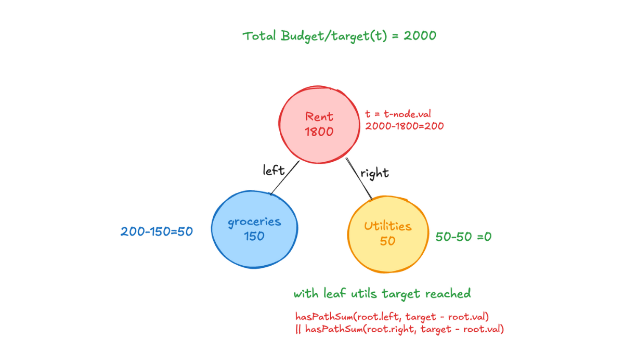>

In [ ]:
def hasPathSum(root, target):
  if not root: return False
  if not root.left and not root.right: return target == root.val
  return hasPathSum(root.left, target - root.val) or hasPathSum(root.right, target - root.val)

class Tree:
  def __init__(self, val):
    self.val = val
    self.left = None
    self.right = None

root = Tree(1800)
root.right = Tree(50)
root.left = Tree(150)

hasPathSum(root, 1851) # False
#hasPathSum(root, 1850) # True
#hasPathSum(root, 1950) # True



## Pattern 16 — Tree BFS — Level Order Traversal

**Importance:** ★★★★★

### Story
Imagine exploring a building floor by floor. BFS visits all nodes at one level before moving to the next. This gives a natural layered view of a tree, making BFS perfect when levels matter.

### When to Use
*   Level order traversal
*   Right/left side view of a tree
*   Zigzag level order

### Core Idea
*   Use a queue, process nodes level by level, and record each layer as a list.

### Pitfalls
*   Forgetting to reset 'level' list each iteration
*   Not handling empty root edge case

### Mini Example
Example: Tree `[3,9,20,null,null,15,7]` → `[[3],[9,20],[15,7]]`.

![][image1]

[image1]: <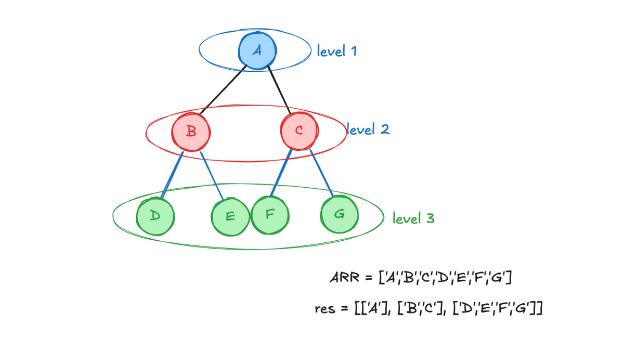>

In [ ]:
def levelOrder(tree):
  if tree is None:
    return
  queue = []
  result = []
  queue.append(tree)
  while len(queue) > 0:
    node = queue.pop(0)
    result.append(node.data)
    if node.left is not None:
      queue.append(node.left)
    if node.right is not None:
      queue.append(node.right)
  return result


class Tree:
  def __init__(self, data):
    self.data = data
    self.left = None
    self.right = None

A = Tree("A")
B = Tree("B")
C = Tree("C")
D = Tree("D")
E = Tree("E")
F = Tree("F")
G = Tree("G")

A.left = B
A.right = C
B.left = D
B.right = E
C.left = F
C.right = G

levelOrder(A)


In [ ]:
def levelOrderLevels(tree):
    if tree is None:
        return []
    result = []
    queue = [tree]

    while queue:
        level_size = len(queue)     # how many nodes are in THIS level
        current_level = []          # collect this level's data here

        for _ in range(level_size):
            node = queue.pop(0)
            current_level.append(node.data)
            if node.left is not None:
                queue.append(node.left)
            if node.right is not None:
                queue.append(node.right)

        result.append(current_level)

    return result

print(levelOrderLevels(A))

### Note

There is no way of doing it recursively directly without levels.

So the real rule underneath your generalization is: BFS wants FIFO (first-in-first-out) → queue. DFS wants LIFO (last-in-first-out) → stack, and recursion gives you a stack automatically.

In [ ]:
def levelOrderRecLevels(tree, level=0, result=None):
    if result is None:
        result = []
    if tree is None:
        return result
    if len(result) == level:
        result.append([tree.data])
    else:
        result[level].append(tree.data)
    levelOrderRecLevels(tree.left, level + 1, result)
    levelOrderRecLevels(tree.right, level + 1, result)
    return result

print(levelOrderRecLevels(A))

## Pattern 17 — Graph BFS — Shortest Path (Unweighted)

**Importance:** ★★★★★

### Story
Imagine S is a person who hears a secret. S immediately tells everyone standing right next to them — A, B, and C — that takes "1 step." Then A, B, and C each tell everyone they know that hasn't heard yet — that's "2 steps." This keeps spreading outward in waves, one step at a time, until everyone's heard it.

### When to Use
*   Shortest path in unweighted graphs
*   Word ladder problems
*   Minimum jumps or transformations

### Core Idea
Use BFS from the source; maintain a visited set and record distances.

### Pitfalls
*   Not marking visited early (causes repeated processing)
*   Using BFS on weighted graphs (use Dijkstra instead)

### Mini Example
**Example:** BFS ensures the first time you reach a node, it is via the shortest route.

![][image1]

[image1]: <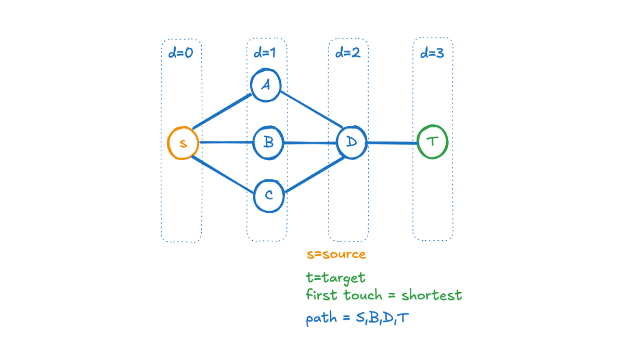>

In [ ]:
graph = {
    'S':  ['A', 'B', 'C'],
    'A': ['S', 'D'],
    'B': ['S', 'D'],
    'C': ['S', 'D'],
    'D': ['A', 'B', 'C', 'T'],
    'T': ['D']
}

def shortestPath(graph, start, target):
    # "seen" = everyone who has already heard the rumor.
    # We add 'start' immediately, since the source already knows their own secret.
    seen = set([start])

    # "queue" holds people waiting to spread the rumor to their neighbors.
    # Each entry is [person, path_taken_to_reach_them]
    # We store the FULL PATH now, not just the distance, so we can
    # reconstruct exactly how the rumor traveled.
    queue = [[start, [start]]]

    while len(queue):
        # Pop the next person in line (FIFO -> queue -> BFS)
        vertex, path = queue.pop(0)

        # If this person is who we're looking for, we're done.
        # Because BFS spreads in waves, the FIRST time we reach the
        # target is guaranteed to be via the SHORTEST path.
        if vertex == target:
            return path

        # Tell everyone this person knows about the rumor
        for neighbor in graph[vertex]:
            if neighbor not in seen:
                # neighbor's path = everything in current path + neighbor themself
                queue.append([neighbor, path + [neighbor]])
                seen.add(neighbor)  # mark as heard so we never re-visit

    # If we empty the queue without finding target, no path exists
    return None


result = shortestPath(graph, 'S', 'T')
print(result)

## Pattern 18 — Multi-Source BFS

**Importance:** ★★★★★

### Story
Imagine a building catches fire, but not from one spot — several separate fires break out at the same time, in different rooms. You want to know: how many minutes until the fire reaches every room in the building?

If you only started the timer from one fire, you'd get the wrong answer for rooms that are actually closer to a different fire. The real spread time for any room is "however long it takes the nearest fire to reach it."

The trick: instead of starting BFS from one point, you start it from ALL the fires at once, in the same starting wave.

Picture it like this — at time 0, every burning room is already "on the queue," all together, all treated as distance 0. Then the fire spreads outward from all of them simultaneously, one step at a time. Whichever fire reaches a room first "wins" that room's distance — which is exactly what you want, since fire doesn't care which source it came from, only which one got there fastest.

Mapping this to code: it's almost identical to regular BFS — the only difference is how you initialize the queue. Instead of queue = [[start, 0]] with one starting point, you seed the queue with all starting points at once, all at distance 0:

### When to Use
*   Grid problems
*   Minimum time or distance from multiple sources
*   Spread simulations

### Core Idea
Push all sources into the queue initially.

### Pitfalls
*   Forgetting to mark visited early
*   Running BFS separately instead of combined

### Mini Example
Rotting Oranges, Walls and Gates

![][image1]

[image1]: <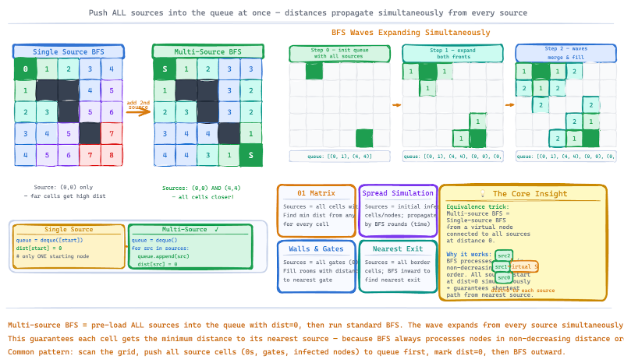>

In [ ]:
from collections import deque

def multiSourceBFS(graph, sources):
    queue = deque()
    seen = set()

    # seed the queue with ALL fires at once, all starting at distance 0
    for s in sources:
        queue.append((s, 0))
        seen.add(s)

    distances = {}

    while queue:
        node, dist = queue.popleft()
        distances[node] = dist
        for neighbor in graph[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                queue.append((neighbor, dist + 1))

    return distances

# Sample graph: rooms in a building, connected to adjacent rooms
rooms = {
    'A': ['B'],
    'B': ['A', 'C', 'E'],
    'C': ['B', 'D'],
    'D': ['C', 'F'],
    'E': ['B', 'F'],
    'F': ['D', 'E', 'G'],
    'G': ['F']
}

# Fires start in room A and room G at the same time
fires = ['A', 'G']

print(multiSourceBFS(rooms, fires))

## Pattern 19 — Graph DFS

**Importance:** ★★★★★

### Story
DFS dives deep before backtracking. It's like exploring every hallway in a maze until you hit a dead end, then retracing steps.

### When to Use
*   Detecting connected components
*   Cycle detection
*   Exploring graph structures

### Core Idea
Mark a node as visited, recursively explore neighbors.

### Pitfalls
*   Forgetting to maintain a visited set, causing infinite loops
*   Stack overflow in very deep graphs without iteration

### Mini Example
**Example:** Counting connected components by running DFS from every unseen node.

![][image1]

[image1]: <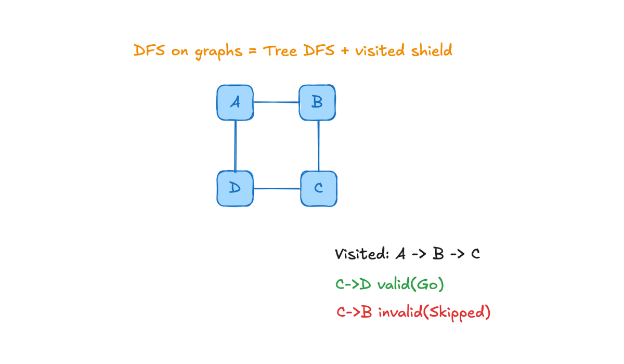>

In [ ]:
graph = {
    'S': ['A', 'B', 'C'],
    'A': ['S', 'D'],
    'B': ['S', 'D'],
    'C': ['S', 'D'],
    'D': ['A', 'B', 'C', 'T'],
    'T': ['D']
}

def dfs_recursive(graph, node, seen=None):
    if seen is None:
        seen = set()

    seen.add(node)          # mark this room as visited
    print(node)              # "visit" it (in this case, just print)

    for neighbor in graph[node]:
        if neighbor not in seen:
            dfs_recursive(graph, neighbor, seen)   # dive deeper down this tunnel

    return seen


dfs_recursive(graph, 'S')

In [ ]:
graph = {
    'S': ['A', 'B', 'C'],
    'A': ['S', 'D'],
    'B': ['S', 'D'],
    'C': ['S', 'D'],
    'D': ['A', 'B', 'C', 'T'],
    'T': ['D']
}

def dfs_iterative(graph, start):
    seen = set([start])
    stack = [start]
    order = []

    while stack:
        node = stack.pop()      # pop from the END = stack behavior = DFS
        order.append(node)
        for neighbor in graph[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                stack.append(neighbor)

    return order


print(dfs_iterative(graph, 'S'))

The bigger takeaway: DFS doesn't guarantee one universal order — it only guarantees "go deep before wide." The exact order depends on implementation details like which neighbor you check first, so don't be surprised if two "correct" DFS implementations give different-looking (but equally valid) outputs.

## Pattern 20 — Grid BFS/DFS — The Islands Pattern

**Importance:** ★★★★★

### Story
Picture a satellite photo turned into a grid of pixels. Each pixel is either water (0) or land (1). Land pixels that touch each other (up/down/left/right) belong to the same island. You want to count how many separate islands exist.

The approach: walk through every cell in the grid. Whenever you find an unvisited land cell, that's a new island — increment your count by 1, then DFS outward from there, "flooding" and marking every connected land cell as visited so you never count it again. Like dropping dye at one spot on an island and watching it spread to every connected patch of land, but not across water.

### When to Use
*   Number of islands
*   Flood fill
*   Connected region detection

### Core Idea
Perform DFS/BFS from each unvisited 'land' cell, marking the entire connected region.

### Pitfalls
*   Not marking visited before recursion → repeated work
*   Not checking boundaries

### Mini Example
**Example:** In a 4×5 grid, DFS floods each island once, counting distinct regions.

![][image1]

[image1]: <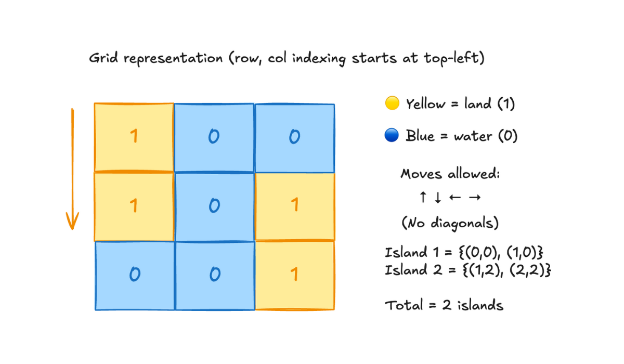>

In [ ]:
def numIslands(grid):
    if not grid:
        return 0

    rows = len(grid)
    cols = len(grid[0])
    seen = set()

    def dfs(r, c):
        # stop if out of bounds, already seen, or water
        if (r < 0 or r >= rows or c < 0 or c >= cols
                or (r, c) in seen or grid[r][c] == 0):
            return
        seen.add((r, c))            # mark this land cell as visited
        dfs(r + 1, c)                # flood down
        dfs(r - 1, c)                # flood up
        dfs(r, c + 1)                # flood right
        dfs(r, c - 1)                # flood left

    islands = 0
    for r in range(rows):
        for c in range(cols):
            if grid[r][c] == 1 and (r, c) not in seen:
                islands += 1          # found a brand new island
                dfs(r, c)              # flood-fill the whole island so we don't recount it

    return islands


grid = [
    [1, 1, 0, 0, 0],
    [1, 1, 0, 0, 1],
    [0, 0, 0, 0, 1],
    [0, 0, 1, 0, 0]
]

print(numIslands(grid))

## Pattern 21 — Topological Sort

**Importance:** ★★★★★

### Story
Think about getting a college degree. Some courses require others first — you can't take "Advanced Calculus" before "Calculus 1." If you drew every course as a node, and drew an arrow from each course to the course that depends on it, you'd get a DAG (Directed Acyclic Graph — "directed" means arrows only go one way, "acyclic" means no loops, since a course can't secretly require itself through a chain).

Topological sort answers: "what's a valid order to take all these courses in, so I never take something before its prerequisite?"

The approach (Kahn's algorithm — BFS-based): figure out how many prerequisites each course has (its "in-degree"). Start with any course that has zero prerequisites — you can take that one right away. Take it, then for every course that depended on it, reduce their prerequisite count by one, since you just satisfied one of their requirements. Any course that hits zero remaining prerequisites is now ready to take too. Repeat until everything's scheduled.

This is the same wave-spreading BFS idea as the rumor and the fire — instead of "who's heard the rumor," it's "whose prerequisites are all satisfied."

### When to Use
*   Course scheduling problems
*   Dependency resolution
*   Ordering tasks with prerequisites

### Core Idea
Compute in-degree of each node, push nodes with zero in-degree into a queue, and process until empty.

### Pitfalls
*   Forgetting to detect cycles (when result size < nodes count)
*   Not computing in-degree correctly

### Mini Example
**Example:** Course prerequisites represented as a DAG can be ordered via topological sort.

![][image1]

[image1]: <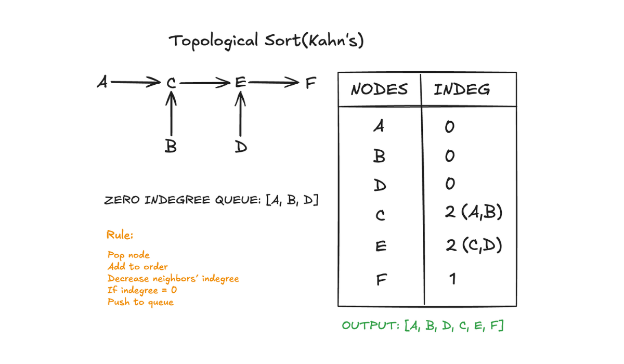>

In [ ]:
from collections import deque

def courseOrder(numCourses, prerequisites):
    # prerequisites: list of [course, prereq] pairs, meaning "prereq must come before course"
    graph = {i: [] for i in range(numCourses)}
    in_degree = {i: 0 for i in range(numCourses)}  # how many prereqs each course still needs

    for course, prereq in prerequisites:
        graph[prereq].append(course)   # prereq points TO the course that depends on it
        in_degree[course] += 1          # that course now has one more prereq to satisfy

    # start with every course that has ZERO prerequisites — ready to take now
    queue = deque([c for c in in_degree if in_degree[c] == 0])
    order = []

    while queue:
        course = queue.popleft()
        order.append(course)
        for next_course in graph[course]:
            in_degree[next_course] -= 1        # one prereq just got satisfied
            if in_degree[next_course] == 0:    # if ALL its prereqs are done, it's ready
                queue.append(next_course)

    # if we scheduled every course, return the order; otherwise there's a cycle (impossible schedule)
    return order if len(order) == numCourses else []


# Example: 4 courses, numbered 0-3
# [1, 0] means "course 1 requires course 0 first"
prerequisites = [[1, 0], [2, 0], [3, 1], [3, 2]]

print(courseOrder(4, prerequisites))

## Pattern 22 — Union–Find (Disjoint Set)

### Importance: ★★★★★

### Story
Imagine you're at a big party, and people keep introducing pairs of friends to each other. Over time, groups of mutual friends form — everyone in a group is connected, directly or through a chain of introductions. Each group has one person you consider the "group representative" — doesn't matter who, just someone you can point to and say "ask them, they represent this whole friend group."

Now here's the cycle-detection idea: if someone tries to introduce two people who are already in the same friend group, that introduction is redundant — they were already connected some other way, so this new connection creates a loop back to the same group.

That's exactly what Union-Find detects in a graph. Each connected component (group of nodes all linked together) has a representative ("parent"). For every edge in the graph, you ask: "are these two nodes already in the same group?" If yes, adding this edge would create a cycle. If no, you merge their groups together (union them) and move on

### When to Use
*   Cycle detection in undirected graphs
*   Grouping related components
*   Counting connected components

### Core Idea
Maintain `parent[]` and `rank[]`. Use path compression + union by rank for efficiency.

### Pitfalls
*   Not applying path compression → slow performance
*   Merging by value instead of representative parent

![][image1]

[image1]: <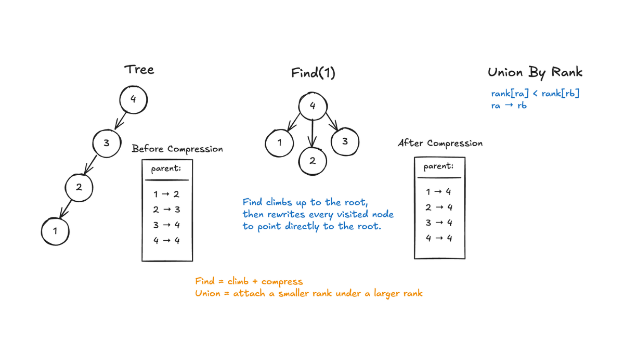>

In [ ]:
def find(parent, node):
    # walk up the chain until you reach the group's representative
    while parent[node] != node:
        node = parent[node]
    return node


def union(parent, node1, node2):
    # merge node2's whole group under node1's representative
    root1 = find(parent, node1)
    root2 = find(parent, node2)
    parent[root2] = root1


def hasCycle(n, edges):
    # start: everyone is their own representative (nobody's grouped with anyone yet)
    parent = {i: i for i in range(n)}

    for node1, node2 in edges:
        root1 = find(parent, node1)
        root2 = find(parent, node2)

        if root1 == root2:
            # they're already in the same group — this edge creates a cycle
            return True

        union(parent, node1, node2)

    return False


# Example: 4 nodes (0,1,2,3), edges forming a triangle plus one extra node
edges = [[0, 1], [1, 2], [2, 0], [2, 3]]

print(hasCycle(4, edges))

## Pattern 23 — Binary Search (Classic)

### Importance: ★★★★★

### Story
Binary search is like looking for a word in a dictionary: open to the middle and decide which half to search next.

### When to Use
*   Searching sorted arrays
*   Finding boundaries (first/last occurrence)
*   Any monotonic condition

### Core Idea
While (`lo <= hi`): check `mid`, decide which half to keep.

### Pitfalls
*   Infinite loops caused by wrong `mid` update
*   Incorrect boundary handling

### Mini Example
**Example:** `nums=[1,3,5,7,9]`, `target=7` → returns index 3.

![][image1]

[image1]: <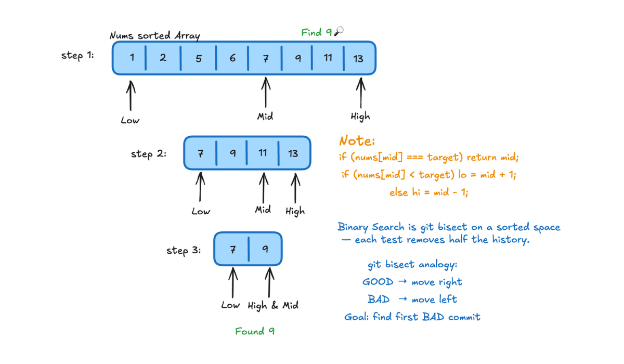>

In [ ]:
def binarySearch(nums, target)->int:
  head = 0
  tail = len(nums)
  while(head < tail):
    mid = (head + tail)//2
    curr = nums[mid]
    if curr == target:
      return mid
    elif curr > target:
      tail = mid
    else:
      head = mid - 1

  return -1

binarySearch(nums=[1,3,5,7,9], target=7)

## Pattern 24 — Binary Search on Answer

### Importance: ★★★★★

### Story
Koko has piles of bananas and a lazy zoo keeper only gives her h hours before checking on her. She eats at a fixed speed of k bananas per hour — but for any pile smaller than k, she still uses up a full hour on it (can't combine leftover time across piles). She wants to eat all the bananas within h hours, but she's not in a rush — she wants the slowest speed that still lets her finish in time, so she's not stuffing herself faster than necessary.

The question: what's the minimum eating speed k that lets Koko finish all piles within h hours?

Why is this "binary search on the answer" and not binary search on an array?

Here's the key insight: imagine you tried every possible speed, 1 banana/hr, 2/hr, 3/hr, and so on, and for each one you asked "does Koko finish in time at this speed?" You'd get a pattern like: No, No, No, ..., No, Yes, Yes, Yes, ... — once a speed works, every faster speed also works (eating faster never makes her slower to finish). That's a sorted yes/no pattern, exactly like a sorted array — so instead of searching through a list of numbers, you're binary searching through a range of possible speeds, looking for that flip point from "No" to "Yes."

Think of it like guessing a number between 1 and 1,000,000 with someone telling you "too low" or "too high" — same idea, except here "too low" means "Koko didn't finish in time."

### When to Use
*   Minimize the maximum value (e.g., allocate workloads)
*   Koko eating bananas
*   Finding minimum capacity or maximum feasible threshold

### Core Idea
Binary search the answer range; use a helper `check(mid)` to decide which half to search next.

### Pitfalls
*   Choosing the wrong answer range
*   Incorrect feasibility check

### Mini Example
**Example:** Koko chooses smallest `k` such that she finishes bananas within `h` hours.

![][image1]

[image1]: <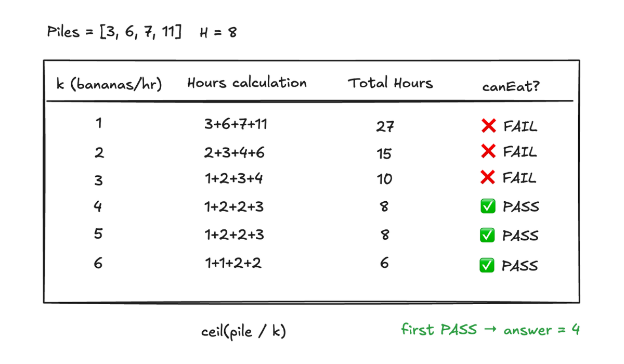>

In [ ]:
import math

def minEatingSpeed(piles, h):
    def hoursNeeded(speed):
        # for each pile, how many hours does it take at this speed?
        # math.ceil because even a small leftover still costs a full hour
        return sum(math.ceil(pile / speed) for pile in piles)

    low = piles[0]                  # slowest possible speed
    high = max(piles)        # fastest speed ever needed (finish biggest pile in 1 hour)

    while low < high:
        mid = (low + high) // 2   # candidate speed to test
        if hoursNeeded(mid) <= h:
            # this speed works! but maybe a slower speed also works — try smaller
            high = mid
        else:
            # too slow, Koko won't finish in time — need to go faster
            low = mid + 1

    return low


piles = [3, 6, 7, 11]
h = 8
print(minEatingSpeed(piles, h))

## Pattern 25 — Top-K Elements (Heap)

**Importance:** ★★★★★

### Story
finding the Top K most frequently searched products on an e-commerce site (like Amazon showing "trending searches"). This is exactly the kind of feature you'd build in a Spring Boot analytics service.

You have a stream of search query logs, and you want to show the "Top 5 Trending Searches" — a classic Top K problem.

### When to Use
*   K largest elements
*   Real-time ranking
*   Maintaining best K candidates

### Core Idea
Use a min-heap of size K. Insert every number; if size exceeds K, remove the smallest.

### Pitfalls
*   Using a max-heap complicates logic
*   Forgetting to pop when heap grows too large

### Mini Example
**Example:** `nums=[3,1,5,12,2,11], k=3` → top 3 = `[5,11,12]`.

![][image1]

[image1]: <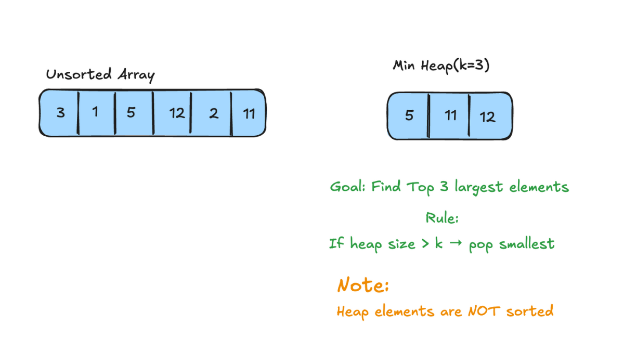>

In [ ]:
import heapq

def top_k_elements(nums, k):
    # Use a min-heap of size k
    min_heap = []

    for num in nums:
        heapq.heappush(min_heap, num)
        if len(min_heap) > k:
            heapq.heappop(min_heap)  # remove smallest, keep k largest

    # min_heap now contains the k largest elements (unsorted internally)
    return sorted(min_heap)


if __name__ == "__main__":
    nums = [3, 1, 5, 12, 2, 11]
    k = 3

    result = top_k_elements(nums, k)
    print(f"nums = {nums}, k = {k}")
    print(f"Top {k} elements = {result}")

## Pattern 26 — Ordered Set / Two Heaps (Median Pattern)

**Importance:** ★★★★★

### Story
Imagine you're running a live exam portal. As students submit their scores one by one, your dashboard needs to show the current median score in real time — no waiting for all students to finish.

Scores come in like this: 5, 15, 1, 3, 8, 7, 9, 10 — one at a time, in that order.

You can't just sort the whole list every time a new score comes in — with thousands of students submitting every second, resorting everything each time would be way too slow.

### The "aha" trick

Picture two buckets:

*   Left bucket = holds the smaller half of scores.
*   Right bucket = holds the larger half of scores.

Whenever a new score comes in, you drop it into the right bucket (small or large), then just make sure:

*   Everything in the left bucket is smaller than everything in the right bucket.
*   The buckets stay roughly equal in size (off by at most 1).

If you keep those two rules true, the median is always just the top of one bucket, or the average of both tops. You never have to sort anything.

Think of it like a seesaw — you're just making sure it stays balanced after every score comes in.

### When to Use
*   Streaming data
*   Median or percentile queries

### Core Idea
Max-heap (left) + Min-heap (right)

### Pitfalls
*   Improper heap balancing
*   Forgetting size difference rule

### Mini Example
Find Median from Data Stream

![][image1]

[image1]: <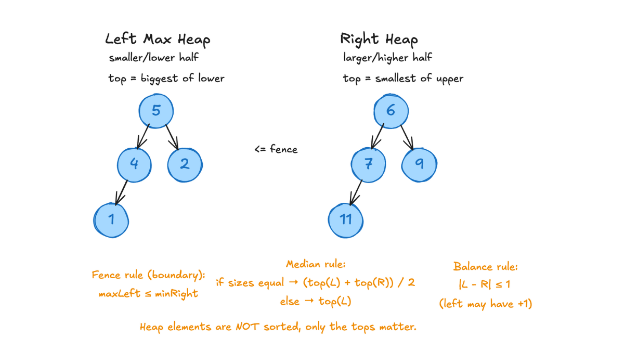>

In [ ]:
import heapq

class MedianFinder:
    def __init__(self):
        self.max_heap = []  # lower half (inverted, so it behaves as max-heap)
        self.min_heap = []  # upper half (regular min-heap)

    def add_num(self, num):
        # Step 1: Always push to max_heap first (lower half)
        heapq.heappush(self.max_heap, -num)  # negate for max-heap behavior

        # Step 2: Balance — ensure every max_heap element <= every min_heap element
        # (move the largest of the lower half into the upper half)
        heapq.heappush(self.min_heap, -heapq.heappop(self.max_heap))

        # Step 3: Rebalance sizes — max_heap should have equal or one more than min_heap
        if len(self.min_heap) > len(self.max_heap):
            heapq.heappush(self.max_heap, -heapq.heappop(self.min_heap))

    def find_median(self):
        if len(self.max_heap) > len(self.min_heap):
            return -self.max_heap[0]  # odd total: lower half has the extra element
        return (-self.max_heap[0] + self.min_heap[0]) / 2  # even total: average both tops


if __name__ == "__main__":
    mf = MedianFinder()
    stream = [5, 15, 1, 3, 8, 7, 9, 10]

    for num in stream:
        mf.add_num(num)
        print(f"Added {num:>3} → Median so far: {mf.find_median()}")

## Pattern 27 — Kth Largest Element

**Importance:** ★★★★★

### Story
This is a focused version of Top-K. Instead of keeping all K items, you only need the Kth largest one.

### When to Use
*   Kth largest in array
*   Streaming ranking queries

### Core Idea
Again use a min-heap of size K. The root always becomes the Kth largest.

### Pitfalls
*   Not popping when heap exceeds size K

### Mini Example
**Example:** `nums=[3,2,1,5,6,4], k=2` → 5.

![][image1]

[image1]: <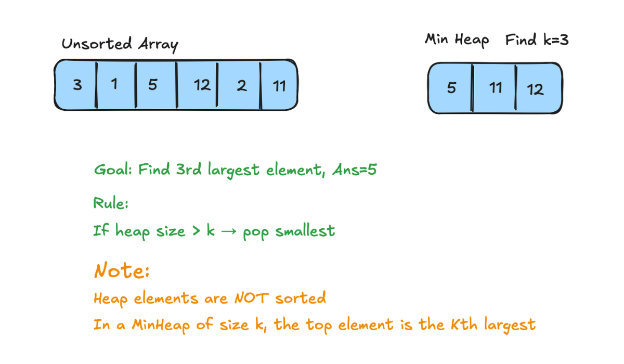>

In [ ]:
import heapq
def kthLargest(nums:list, k:int)->list:
  min_heap = []
  for num in nums:
    heapq.heappush(min_heap, num)
    if len(min_heap)>k:
      heapq.heappop(min_heap)
  return min_heap[0]

kthLargest([3,1,5,12,2,11], k=3)



## Pattern 28 — Top-K Frequent Elements

**Importance:** ★★★★★

### Story
First count the frequency of each element. Then maintain a heap of the K most frequent.

### When to Use
*   Most frequent words
*   Trending items
*   Log analysis

### Core Idea
Build a freq map → push into min-heap sorted by frequency → if size > K, pop.

### Pitfalls
*   Incorrect frequency counting
*   Using wrong heap (max-heap)

### Template Code (JavaScript)

In [ ]:
import heapq
from collections import Counter

def get_top_k_frequent_manual(logs, k):
    frequency_map = Counter(logs)

    min_heap = []
    for word, freq in frequency_map.items():
        heapq.heappush(min_heap, (freq, word))
        if len(min_heap) > k:
            heapq.heappop(min_heap)  # remove least frequent

    # Heap has k elements, sorted ascending by freq — reverse for descending
    result = [word for freq, word in sorted(min_heap, reverse=True)]
    return result


if __name__ == "__main__":
    search_logs = [
        "iphone", "laptop", "iphone", "headphones", "laptop",
        "iphone", "shoes", "laptop", "headphones", "iphone",
        "tablet", "shoes", "laptop", "headphones", "headphones"
    ]
    print(get_top_k_frequent_manual(search_logs, 3))

## Pattern 29 — Merge K Sorted Lists

**Importance:** ★★★★★

### Story
You're building a music app that shows one unified "Recently Played" feed, merged from 3 devices — phone, laptop, and tablet. Each device already has its own songs sorted by timestamp. You need to merge all 3 into a single sorted feed, without just dumping everything together and re-sorting from scratch.

```
Phone:   [1, 4, 7]
Laptop:  [2, 5, 8]
Tablet:  [3, 6, 9]

Merged:  [1, 2, 3, 4, 5, 6, 7, 8, 9]
```
**The "aha" trick**

Instead of combining all songs into one giant list and sorting it (slow, wasteful — you'd be re-sorting stuff that's already sorted), you keep a small heap with just the "front" song from each device.

Every time you pick the smallest song off the heap, you immediately peek at that same device and pull its next song into the heap. You're never looking at more than 3 songs at once (one per device) — just constantly swapping out "whoever's turn it is" for "whoever's next."

Think of it like 3 people in 3 different lines, each holding a numbered ticket in order. You always call out the smallest ticket number across all 3 lines, and whoever handed you that ticket immediately shows you their next one.

### When to Use
*   Merging sorted data streams
*   Log merging
*   External sort

### Core Idea
Push each list’s head into a min-heap → pop smallest → push its next.

### Mini Example
**Example:** merging 3 sorted linked lists using a heap.

![][image1]

[image1]: <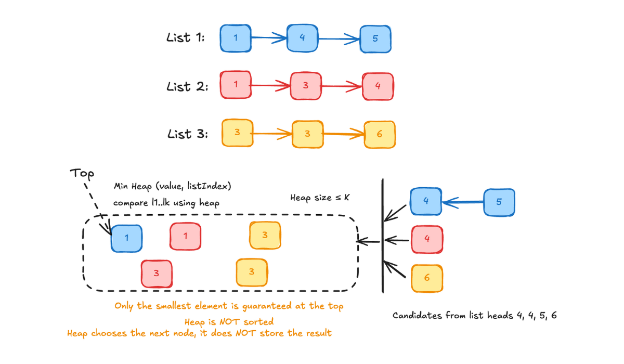>

In [ ]:
import heapq

def merge_k_sorted_lists(lists):
    min_heap = []
    result = []

    # Step 1: push the first song from each device, tagging WHICH device it came from
    for device_index, song_list in enumerate(lists):
        if song_list:  # skip empty devices
            first_song = song_list[0]
            heapq.heappush(min_heap, (first_song, device_index, 0))
            # (song_value, which_device, position_in_that_device's_list)

    # Step 2: keep pulling the smallest song, then refill from the same device
    while min_heap:
        song, device_index, position = heapq.heappop(min_heap)
        result.append(song)

        # if that device has more songs, push its next one
        next_position = position + 1
        if next_position < len(lists[device_index]):
            next_song = lists[device_index][next_position]
            heapq.heappush(min_heap, (next_song, device_index, next_position))

    return result


# --- Simulate 3 devices with sorted "recently played" timestamps ---
phone = [1, 4, 7]
laptop = [2, 5, 8]
tablet = [3, 6, 9]

merged_feed = merge_k_sorted_lists([phone, laptop, tablet])
print("Merged feed:", merged_feed)

## Pattern 30 — Dijkstra’s Algorithm (Weighted Shortest Path)

**Importance:** ★★★★

### Story
You're a delivery driver starting at intersection A in a small town. The roads between intersections take different times to drive (the numbers on each edge). You want to know the fastest time from A to every other intersection in town.

You don't explore roads randomly — you always drive toward whichever unvisited intersection is currently closest to you (by total time so far), lock that time in as final, then check if going through it opens up a shorter path to its neighbors. That's the whole algorithm.

### When to Use
*   Shortest path in weighted graphs
*   Network routing
*   Latency optimization

### Core Idea
*   Use a min-heap of (node, distance). Relax edges and update distances.

### Pitfalls
*   Not skipping outdated distances
*   Using BFS incorrectly on weighted graphs

![][image1]

[image1]: <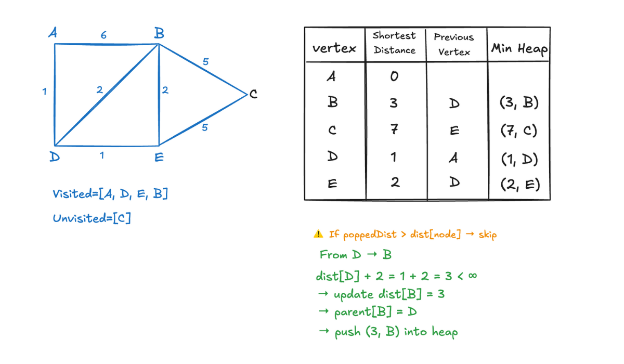>

In [ ]:
import heapq

# Road network: intersection -> {neighbor: drive_time}
roads = {
    'A': {'B': 6, 'D': 1},
    'B': {'A': 6, 'D': 2, 'E': 2, 'C': 5},
    'C': {'B': 5, 'E': 5},
    'D': {'A': 1, 'B': 2, 'E': 1},
    'E': {'D': 1, 'B': 2, 'C': 5}
}

def dijkstra(graph, start):
    # Step 1: every intersection starts "unreachable" except the driver's start point
    dist = {node: float('inf') for node in graph}
    dist[start] = 0
    parent = {node: None for node in graph}
    visited = set()

    # Min-heap: (time_so_far, intersection)
    min_heap = [(0, start)]

    while min_heap:
        current_dist, current_node = heapq.heappop(min_heap)

        # Skip stale entries — we already found a faster way here before
        if current_dist > dist[current_node]:
            continue

        # Lock in this intersection's shortest time — it's now "visited"
        visited.add(current_node)

        # Check every road out of this intersection
        for neighbor, drive_time in graph[current_node].items():
            if neighbor in visited:
                continue

            new_dist = current_dist + drive_time

            # Found a faster way to reach neighbor? Update it.
            if new_dist < dist[neighbor]:
                dist[neighbor] = new_dist
                parent[neighbor] = current_node
                heapq.heappush(min_heap, (new_dist, neighbor))

    return dist, parent


def print_route(parent, start, destination):
    """Reconstructs the actual path the driver takes, not just the total time."""
    path = []
    node = destination
    while node is not None:
        path.append(node)
        node = parent[node]
    path.reverse()
    return " → ".join(path)


# --- Run it ---
distances, parents = dijkstra(roads, 'A')

print("Fastest time from A to every intersection:\n")
for intersection in sorted(distances):
    time = distances[intersection]
    route = print_route(parents, 'A', intersection)
    print(f"  A → {intersection}: {time} min   (route: {route})")

## Pattern 31 — 1D Dynamic Programming

**Importance:** ★★★★★

### Story
1D DP solves problems by building solutions for small indexes and reusing them for larger ones. Each state depends on a small number of previous states.

### When to Use
*   Fibonacci
*   Climbing stairs
*   House robber

### Core Idea
State transition: `dp[i] = best value using dp[i-1], dp[i-2], etc.`

### Pitfalls
*   Incorrect base cases
*   Confusing dp indexing

### Mini Example
**Example:** `n=4` → 5 ways to climb.

![][image1]

[image1]: <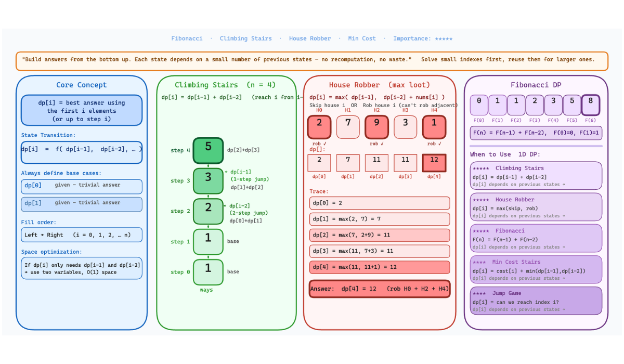>

In [ ]:
def climb_n_stairs(n):
  if n < 0: return 0 # Handle negative input if necessary
  if n <= 2: return n

  # Initialize dp array with size n+1
  # dp[i] will store the number of ways to climb i stairs
  dp = [0] * (n + 1)
  dp[1] = 1 # One way to climb 1 stair
  dp[2] = 2 # Two ways to climb 2 stairs (1+1 or 2)

  for i in range(3, n+1):
    dp[i] = dp[i-1] + dp[i-2]
  return dp[n]

climb_n_stairs(4)

## Pattern 32 — 2D Dynamic Programming

**Importance:** ★★★★★

### Story
You're walking from the top-left corner of a city grid to the bottom-right corner. You can only move right or down — never left or up. Every block you step into costs a toll (that's grid[r][c]). You want the cheapest total route.

Here's the key trick that makes this solvable without checking every possible path: to arrive at any intersection, you must have come from either directly above it or directly to its left — there's no other way, since you only move right/down. So the cheapest way to reach any intersection is: (cheapest way to reach the intersection above) OR (cheapest way to reach the intersection to the left), whichever is smaller, plus this intersection's own toll.

### When to Use
*   Min path sum
*   Edit distance
*   Sequence alignment

### Core Idea
Fill `dp[r][c]` after initializing first row and column.

### Pitfalls
*   Incorrect initialization of base row/column

### Mini Example
**Example:** `grid=[[1,3,1],[1,5,1],[4,2,1]]` → min sum = 7.

![][image1]

[image1]: <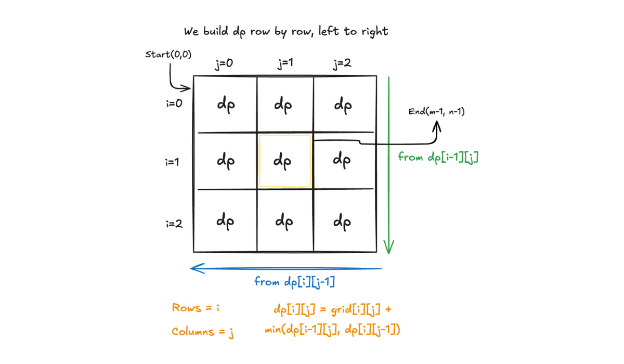>

In [ ]:
def minPathSum(grid):
  R = len(grid)
  C = len(grid[0])
  dp = [[0] * C for _ in range(R)]
  dp[0][0] = grid[0][0]

  for r in range(1, R): dp[r][0] = dp[r-1][0] + grid[r][0]
  for c in range(1, C): dp[0][c] = dp[0][c-1] + grid[0][c]

  for r in range(1, R):
    for c in range(1, C):
      # Corrected from math.min to Python's built-in min()
      dp[r][c] = min(dp[r-1][c], dp[r][c-1]) + grid[r][c]

  return dp[R-1][C-1]

grid=[[1,3,1],[1,5,1],[4,2,1]]
minPathSum(grid)


## Pattern 33 — Tree Traversals (Pre-Order, In-Order, Post-Order)

**Importance:** ★★★★★

### Story
Imagine giving a tour of a house where every room has at most two doors leading deeper inside. The order in which you **announce** each room changes what the tour is good for:

- **Pre-order** — announce the room as soon as you walk in. Perfect for *copying* the house (you record a room before its children), so it's how trees get serialized.
- **In-order** — explore everything through the left door, announce the room, then go through the right door. In a **Binary Search Tree** this announces values in **sorted order**.
- **Post-order** — announce the room only after both doors are fully explored. Perfect for *cleanup* or for combining children's answers (Pattern 14).

Same walk, three different moments to "visit". Picking the right moment is the whole pattern.

### When to Use
*   **In-order on a BST**: Validate BST, Kth Smallest in BST, BST Iterator, Recover BST, Two Sum in BST
*   **Pre-order**: Serialize / Deserialize a tree, clone a tree, Flatten Binary Tree to Linked List
*   **Pre-order + In-order**: Construct Binary Tree from Preorder and Inorder Traversal
*   **Post-order**: delete a tree, height / diameter / subtree sums (see Pattern 14)
*   **Iterative versions**: very deep (skewed) trees where recursion would hit Python's recursion limit, or when the interviewer asks "can you do it without recursion?"

### Core Idea
```
        4
       / \
      2   6
     / \ / \
    1  3 5  7

Pre-order   (Node, Left, Right): 4 2 1 3 6 5 7
In-order    (Left, Node, Right): 1 2 3 4 5 6 7   ← sorted for a BST
Post-order  (Left, Right, Node): 1 3 2 5 7 6 4
```

Recursive template — only the position of `visit(node)` changes:
```
def traverse(node):
    if not node: return
    # visit(node)   ← pre-order
    traverse(node.left)
    # visit(node)   ← in-order
    traverse(node.right)
    # visit(node)   ← post-order
```

Iterative in-order (the one interviewers ask for most):
```
stack, node = [], root
while stack or node:
    while node:              # slide all the way left
        stack.append(node)
        node = node.left
    node = stack.pop()       # leftmost unvisited node
    visit(node)
    node = node.right        # then explore its right subtree
```

Iterative pre-order: pop, visit, push **right first** then left (so left is processed first).
Iterative post-order trick: do a "Node, Right, Left" pre-order and reverse the result.

### Pitfalls
*   **Validating a BST by comparing a node only with its direct children** — `[5, 4, 6, null, null, 3, 7]` passes that check but 3 sits in 5's right subtree. Use in-order (strictly increasing) or pass down `(low, high)` bounds.
*   **Pushing left before right** in iterative pre-order — the stack reverses order, so push right first.
*   **Recursion depth** — a skewed tree with 10⁴ nodes overflows Python's default limit of 1000; use the iterative version.
*   **Not stopping early** — for Kth Smallest, stop as soon as you've visited k nodes instead of building the full list.

### Mini Example
**Example:** BST above, `k = 3` → Kth smallest = **3** (in-order: 1, 2, **3**, …).

In [ ]:
class TreeNode:
    def __init__(self, val, left=None, right=None):
        self.val = val
        self.left = left
        self.right = right


def build_tree(values):
    """Build a tree from a level-order list (None = missing child), LeetCode style."""
    if not values or values[0] is None:
        return None
    root = TreeNode(values[0])
    queue = [root]
    i = 1
    for node in queue:
        if i < len(values) and values[i] is not None:
            node.left = TreeNode(values[i])
            queue.append(node.left)
        i += 1
        if i < len(values) and values[i] is not None:
            node.right = TreeNode(values[i])
            queue.append(node.right)
        i += 1
        if i >= len(values):
            break
    return root


# ---------- Recursive ----------
def preorder(node, out=None):
    if out is None: out = []
    if node:
        out.append(node.val)
        preorder(node.left, out)
        preorder(node.right, out)
    return out

def inorder(node, out=None):
    if out is None: out = []
    if node:
        inorder(node.left, out)
        out.append(node.val)
        inorder(node.right, out)
    return out

def postorder(node, out=None):
    if out is None: out = []
    if node:
        postorder(node.left, out)
        postorder(node.right, out)
        out.append(node.val)
    return out


# ---------- Iterative ----------
def preorder_iterative(root):
    if not root: return []
    out, stack = [], [root]
    while stack:
        node = stack.pop()
        out.append(node.val)
        if node.right: stack.append(node.right)   # right first...
        if node.left: stack.append(node.left)     # ...so left is popped first
    return out

def inorder_iterative(root):
    out, stack, node = [], [], root
    while stack or node:
        while node:
            stack.append(node)
            node = node.left
        node = stack.pop()
        out.append(node.val)
        node = node.right
    return out

def postorder_iterative(root):
    # Node-Right-Left pre-order, reversed, gives Left-Right-Node
    if not root: return []
    out, stack = [], [root]
    while stack:
        node = stack.pop()
        out.append(node.val)
        if node.left: stack.append(node.left)
        if node.right: stack.append(node.right)
    return out[::-1]


# ---------- Interview applications ----------
def kth_smallest(root, k):
    stack, node = [], root
    while stack or node:
        while node:
            stack.append(node)
            node = node.left
        node = stack.pop()
        k -= 1
        if k == 0:
            return node.val          # stop early, no full list
        node = node.right

def is_valid_bst(root):
    prev = float('-inf')
    stack, node = [], root
    while stack or node:
        while node:
            stack.append(node)
            node = node.left
        node = stack.pop()
        if node.val <= prev:          # in-order must be strictly increasing
            return False
        prev = node.val
        node = node.right
    return True


bst = build_tree([4, 2, 6, 1, 3, 5, 7])
print("Pre-order :", preorder(bst), preorder_iterative(bst))
print("In-order  :", inorder(bst), inorder_iterative(bst))
print("Post-order:", postorder(bst), postorder_iterative(bst))

assert preorder(bst) == preorder_iterative(bst) == [4, 2, 1, 3, 6, 5, 7]
assert inorder(bst) == inorder_iterative(bst) == [1, 2, 3, 4, 5, 6, 7]
assert postorder(bst) == postorder_iterative(bst) == [1, 3, 2, 5, 7, 6, 4]

print("3rd smallest:", kth_smallest(bst, 3))                                   # 3
print("Valid BST?", is_valid_bst(bst))                                         # True
print("Valid BST? [5,4,6,None,None,3,7]", is_valid_bst(build_tree([5, 4, 6, None, None, 3, 7])))  # False
assert kth_smallest(bst, 3) == 3
assert is_valid_bst(bst) is True
assert is_valid_bst(build_tree([5, 4, 6, None, None, 3, 7])) is False

## Pattern 34 — Knapsack DP (0/1)

**Importance:** ★★★★★

### Story
You're a thief with one bag that holds up to a fixed weight. You're standing in a room full of items — each has a weight and a value. For each item, you can only grab it once (no duplicates), and once you decide, you move to the next item. Your goal: leave with the most value possible without the bag ripping.

### Why backward matters
If you scan capacities forward, you might accidentally "reuse" the same item twice in your bag — like grabbing the same painting twice because your bag still shows room from before you took it. Going backward locks in that each item is only counted once.

### Pattern sentence to remember
"For each item, decide take-or-leave, walking capacity from high to low so you never double-dip on the same item."

### When to Use
*   0/1 Knapsack
*   Resource allocation

### Core Idea
Traverse capacities backward: `dp[c] = max(dp[c], value + dp[c-weight])`.

### Pitfalls
*   Traversing forward breaks correctness


![][image1]

[image1]: <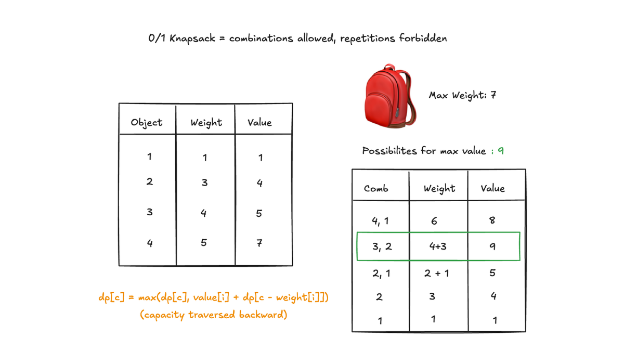>

In [ ]:
def knapsack(weights, values, cap):
    dp = [0] * (cap + 1)
    for i in range(len(weights)):
        for c in range(cap, weights[i] - 1, -1):
            dp[c] = max(dp[c], values[i] + dp[c - weights[i]])
    return dp[cap]

weights = [1,3,4,5]
values  = [1,4,5,7]
cap = 7

print(knapsack(weights, values, cap))  # 7

## Pattern 35 — Backtracking

**Importance:** ★★★★★

### Story
Backtracking explores possibilities like navigating a decision tree. You choose, explore deeper, then undo and try alternatives.

### When to Use
*   Combinations
*   Permutations
*   Subsets
*   Constraint solving

### Core Idea
Backtracking template: choose → recurse → unchoose.

### Pitfalls
*   Not undoing choice leads to incorrect paths

### Mini Example
**Example:** subsets of `[1,2,3]`.

![][image1]

[image1]: <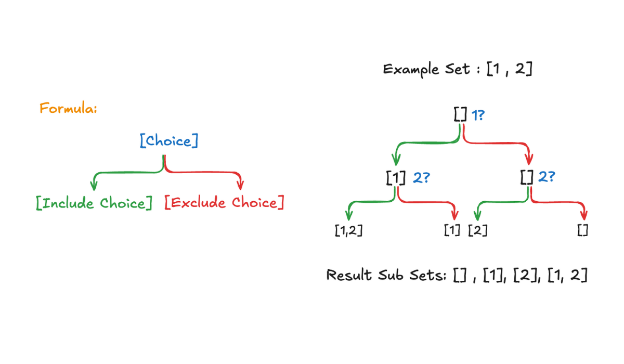>

                 (start)
                /        \
           Door 1        Door 2
             |               |
          [1]              [2]
             |               |
          Door 2          (no doors left)
             |
          [1,2]




START (path = [])
│
├── Right Door 1 (append 1) → path = [1]
│   │
│   └── Right Door 2 (append 2) → path = [1,2]   ← dead end here
│       └── pop 2 → path = [1]
│   │
│   (no more doors in this room)
│   └── pop 1 → path = []
│
├── back at START (path = [])
│
└── Right Door 2 (append 2) → path = [2]   ← dead end here
    └── pop 2 → path = []

(no more doors at START)
DONE

In [ ]:
def subsets(nums):
    result = []

    def backtrack(path, start):
        result.append(path[:])  # save current subset immediately
        for i in range(start, len(nums)):
            path.append(nums[i])
            backtrack(path, i + 1)
            path.pop()

    backtrack([], 0)
    return result


print(subsets([1, 2, 3]))

In [ ]:
def subsets(nums):
    result = []

    def backtrack(index, current):
        # Base case: we've decided on all elements
        if index == len(nums):
            result.append(current[:])  # save a copy
            return

        # Choice 1: include nums[index]
        current.append(nums[index])
        backtrack(index + 1, current)
        current.pop()  # undo the include (backtrack)

        # Choice 2: exclude nums[index]
        backtrack(index + 1, current)

    backtrack(0, [])
    return result


print(subsets([1, 2]))
# [[1, 2], [1], [2], []]

## Pattern 36 — Trie (Prefix Tree)
**Importance:** ★★★★

### Story
A trie is like a dictionary tree where each path from the root spells a word. It gives lightning-fast prefix searches and is perfect for autocomplete systems.

### When to Use
- Autocomplete
- Prefix matching
- Word dictionary lookups

### Core Idea
Each node stores children and an endOfWord flag. Walk character by character.

### Pitfalls
- Not marking the end of word correctly
- Creating unnecessary nodes

### Mini Example
Example: Insert 'car' and 'cat'; both share prefix 'ca'.

![][image1]

[image1]: <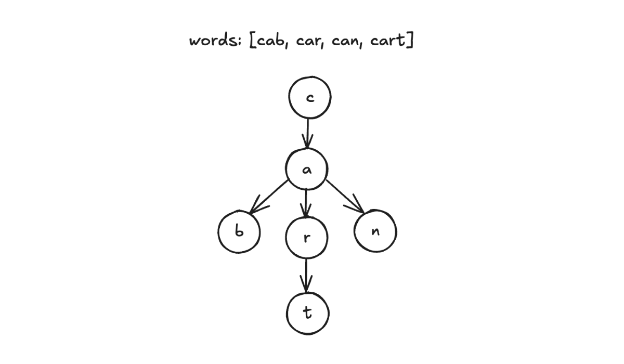>

In [ ]:
class Trie:
    def __init__(self):
        self.root = {}

    def insert(self, word: str) -> None:
        node = self.root
        for char in word:
            if char not in node:
                node[char] = {}
            node = node[char]
        node['#'] = True  # Mark end of word

    def search(self, word: str) -> bool:
        node = self.root
        for char in word:
            if char not in node:
                return False
            node = node[char]
        return '#' in node

    def startsWith(self, prefix: str) -> bool:
        node = self.root
        for char in prefix:
            if char not in node:
                return False
            node = node[char]
        return True


trie = Trie()
trie.insert("apple")
trie.insert("apricot")

print(trie.search("apple"))  # True
print(trie.search("app"))    # False

## Pattern 37 — Bit Manipulation
**Importance:** ★★★★

### Story
Imagine you need to find a single unique element in an array where every other number appears twice—but you only have microseconds to spare. Bit operations let you work at the hardware level, treating numbers as sets of individual switches. XOR is your best friend here: when you XOR two identical numbers, they cancel out to zero. Bitmasks let you generate all possible subsets in compact form, and bit shifts perform lightning-fast multiplication or division by powers of two. It's the secret weapon that separates code that runs in milliseconds from code that runs in seconds.

### When to Use
- Finding unique elements via XOR (single number appears once, rest appear twice)
- Generating or checking subsets with bitmasks
- Performance-critical code requiring low-level optimizations
- Checking/setting individual flags in a compact way

### Core Idea
Leverage XOR for cancelation (identical values vanish), bitmasks to represent subsets compactly, and shifts to multiply/divide by powers of 2 without arithmetic overhead.

### Pitfalls
- Forgetting operator precedence (XOR has lower precedence than comparison operators)
- Confusing left shift `<<` (multiply) vs. right shift `>>` (divide)
- Mixing up bitwise (`&`, `|`) vs. logical (`and`, `or`) operators in Python

### Mini Example
**Example:** Unique number `[4,1,2,1,2]` ---> 4.

![][image1]

[image1]: <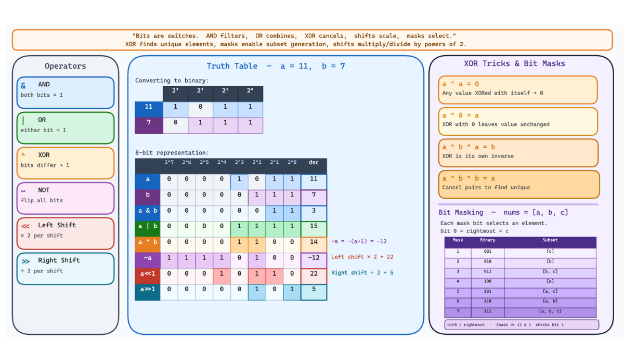>

In [ ]:
# ---------- Basic Operators ----------
a = 11   # binary: 1011
b = 7    # binary: 0111

print("a & b  =", a & b)   # AND: both bits 1        → 3   (0011)
print("a | b  =", a | b)   # OR: either bit 1         → 15  (1111)
print("a ^ b  =", a ^ b)   # XOR: bits differ         → 14  (1110)
print("~a     =", ~a)      # NOT: flips all bits      → -12
print("a << 1 =", a << 1)  # Left shift: ×2           → 22
print("a >> 1 =", a >> 1)  # Right shift: ÷2          → 5


# ---------- XOR Tricks ----------
print("\nXOR tricks:")
print("a ^ a =", a ^ a)          # always 0
print("a ^ 0 =", a ^ 0)          # always a
print("a ^ b ^ a =", a ^ b ^ a)  # cancels back to b

# Classic use: find the one unique number in a list where
# every other number appears twice
nums = [4, 1, 2, 1, 2, 6]
unique = 0
for n in nums:
    unique ^= n
print("Unique number:", unique)  # 4


# ---------- Bit Masking for Subsets ----------
def subsets_bitmask(nums):
    n = len(nums)
    result = []

    for mask in range(2 ** n):          # try every number from 0 to 2^n - 1
        subset = []
        for i in range(n):
            if (mask >> i) & 1:          # check if bit i is set
                subset.append(nums[i])
        result.append(subset)

    return result


print("\nSubsets of [a, b, c]:")
for s in subsets_bitmask(['a', 'b', 'c']):
    print(s)

## Pattern 38 — Intervals
**Importance:** ★★★★★

### Story
Imagine you're managing conference rooms and you have 100 meeting requests for the next month. Some overlap. Some nest inside others. Some touch at the edges. How do you find the minimum number of rooms needed? How do you find which requests conflict? Intervals are like events on a timeline, and the magic trick is simple: sort by start time first, then walk through merging any that overlap. This one pattern solves scheduling problems, collision detection, and range merging that otherwise look impossible.

### When to Use
- Meeting room scheduling (minimum rooms needed)
- Insert interval into a sorted list without creating overlaps
- Merge overlapping intervals into disjoint ranges
- Conflict detection and range union problems

### Core Idea
Sort intervals by start time, then iterate through merging whenever `next.start ≤ current.end`. This collapses all overlaps in one pass.

### Pitfalls
- Forgetting to sort before merging (order matters!)
- Incorrect boundary comparisons (≤ vs. <, which determines if touching intervals merge)
- Not updating the end time correctly when merging

### Mini Example
Example: `[[1,3],[2,6]]` → `[[1,6]]` (overlapping intervals merge into one)

![][image1]

[image1]: <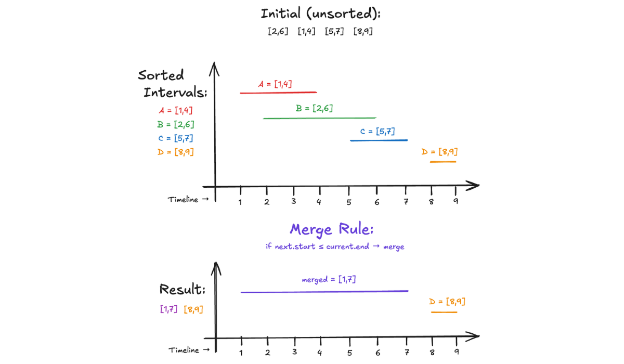>

In [ ]:
def merge_intervals(intervals):
    intervals.sort(key=lambda x: x[0])
    res = [intervals[0]]
    for i in range(1, len(intervals)):
        last = res[-1]
        if intervals[i][0] <= last[1]:
            last[1] = max(last[1], intervals[i][1])
        else:
            res.append(intervals[i])
    return res


print(merge_intervals([[1, 6], [4, 10], [15, 18]]))
# [[1, 6], [8, 10], [15, 18]]

## Pattern 39 — Divide & Conquer
**Importance:** ★★★

### Story
Imagine you need to sort a million bank transactions before midnight. Trying to sort them linearly would take forever. But what if you split them in half, sorted each half separately (which you could even do in parallel), and then merged two sorted lists back together? That's divide and conquer: it turns an impossibly large problem into dozens of tiny, manageable pieces. Merge sort runs in $O(n \log n)$ instead of $O(n^2)$ precisely because it splits the work cleverly.

### When to Use
- Merge sort (guaranteed $O(n \log n)$ sorting)
- Quick sort (average $O(n \log n)$ sorting with small space)
- Binary search and binary search tree problems
- Tree traversals and multi-branch recursion
- Finding closest pair, maximum subarray, etc.

### Core Idea
1. **Divide**: Split the input into smaller subproblems (usually halves)
2. **Conquer**: Solve each subproblem recursively
3. **Combine**: Merge or combine the results back together

### Pitfalls
- Not defining a correct base case (infinite recursion)
- Combining results incorrectly (most common bug)
- Not recognizing when the problem can't be cleanly divided in half
- Excess space/time complexity in the combine step

### Mini Example
Example: Sorting `[3, 1, 4, 1, 5]` via merge sort splits into `[3,1]` and `[4,1,5]`, sorts each, then merges to `[1,1,3,4,5]`.

![][image1]

[image1]: <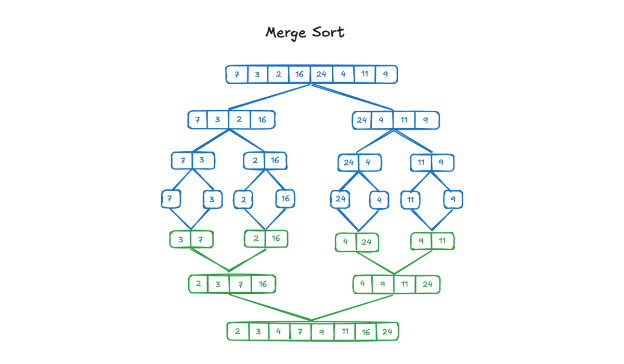>

In [ ]:

from collections import deque

def merge(head, tail):
    head, tail = deque(head), deque(tail)
    merged = []

    while head and tail:
        if head[0] <= tail[0]:
            merged.append(head.popleft())
        else:
            merged.append(tail.popleft())

    merged.extend(head)
    merged.extend(tail)
    return merged

def merge_sort(arr):
    if len(arr) <= 1:
        return arr

    mid = len(arr) // 2
    head_arr = merge_sort(arr[:mid])
    tail_arr = merge_sort(arr[mid:])

    return merge(head_arr, tail_arr)

print(merge_sort([3,1,4,1,5]))

## Pattern 40 — Math Patterns
**Importance:** ★★★

### Story
Imagine you need to find the greatest common divisor of two 100-digit numbers, or check if 1 billion is prime, or find all primes up to 1 million. A naive approach would time out. But 2,000 years ago, Euclid discovered that GCD(a, b) = GCD(b, a mod b) — a simple observation that solves the problem in microseconds instead of milliseconds. Similarly, the Sieve of Eratosthenes finds all primes up to N in $O(N \log \log N)$ instead of checking each number individually. Good math is a superpower.

### When to Use
- Prime number queries and prime factorization
- Finding GCD and LCM efficiently
- Modulo arithmetic for large numbers
- Counting divisors or computing totient function
- Fraction reduction and ratio problems

### Core Idea
- **GCD via Euclid**: $\gcd(a, b) = \gcd(b, a \bmod b)$ until b = 0
- **Sieve of Eratosthenes**: Mark multiples of each prime to find all primes up to N
- **Modular arithmetic**: Use mod to prevent overflow and exploit periodicity

### Pitfalls
- Incorrect base cases (when does recursion/iteration stop?)
- Inefficient prime checking (trial division on every number is slow)
- Off-by-one errors in sieve initialization
- Not handling edge cases (0, 1, negative numbers)

### Examples
**GCD Example**: $\gcd(48, 18) = \gcd(18, 12) = \gcd(12, 6) = \gcd(6, 0) = 6$

**Sieve Example**: Find all primes ≤ 10: [2, 3, 5, 7] (mark off 4, 6, 8, 9, 10 as composites)

![][image1]

[image1]: <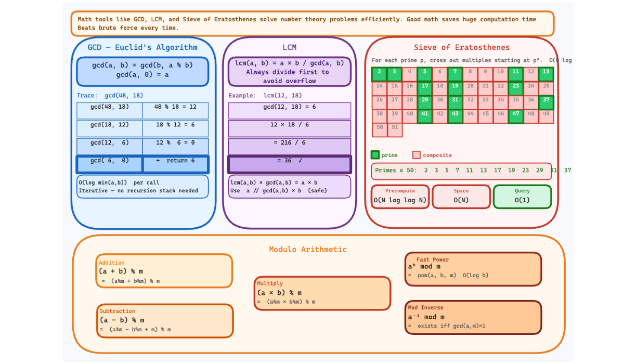>

In [ ]:
# GCD (Euclid) — the sentence: "The GCD of two numbers also divides their remainder, so you can keep shrinking the problem until one side hits 0."
def gcd(a, b):
    while b:
        a, b = b, a % b
    return a

print(gcd(48, 18))  # 6
# Trace: (48,18) → (18,12) → (12,6) → (6,0) → return 6. Matches your example exactly.


# LCM — the sentence: "LCM and GCD are linked by a * b = gcd(a,b) * lcm(a,b), so once you have GCD, LCM is just division."
def lcm(a, b):
    return a * b // gcd(a, b)

print(lcm(4, 6))  # 12
# Why // and not /: a * b is always divisible by gcd(a,b) exactly, so integer division is safe and avoids float errors on big numbers.

# Sieve of Eratosthenes — the sentence: "Every composite number has a smallest prime factor, so if you cross out all multiples of each prime as you find it, whatever survives is prime."
# Primes cannot be greater than root of the number
# n**0.5 is nothing but square root of n
def sieve(n):
    is_prime = [True] * (n + 1)
    is_prime[0] = is_prime[1] = False

    for i in range(2, int(n**0.5) + 1):
        if is_prime[i]:
            for multiple in range(i*i, n + 1, i):
                is_prime[multiple] = False

    return [i for i, prime in enumerate(is_prime) if prime]

print(sieve(10))  # [2, 3, 5, 7]





## Pattern 41 — Sweep Line Algorithm
**Importance:** ★★★★

### Story
Your company books 1,000 meeting rooms across 50 locations over a month. At 2:47 PM on Tuesday, 247 meetings are happening simultaneously—but you need to know: what's the **peak occupancy**? How many physical rooms do you actually need to buy? Checking every second is impossibly slow ($O(n \cdot m)$). But here's the insight: convert each meeting into two events—a "start" and an "end"—sort them, and sweep through time while counting active intervals. Suddenly, a problem that looked intractable becomes $O(n \log n)$.

### When to Use
- Finding maximum overlapping intervals (conference rooms, concurrent tasks, network connections)
- Skyline problem (building silhouettes, calendar busy blocks, video frames)
- Meeting room allocation and booking systems
- Task scheduling and resource utilization
- Event interval processing and collision detection
- Coordinate compression for geometric problems

### Core Idea
1. Convert each interval `[start, end]` into two events: `(start, +1)` and `(end, -1)`
2. Sort events by time; carefully handle ties (typically process **ends before starts** to avoid double-counting)
3. Sweep through sorted events, maintaining a running count of active intervals
4. Track the maximum count, or record the state at each critical point

### Pitfalls
- **Event tie-breaking**: When a meeting ends at 3:00 PM and another starts at 3:00 PM, do they overlap? The answer depends on your problem—be consistent with `<` vs `≤`
- Forgetting to sort the event list (sweep only works on sorted data)
- Mishandling the order of +1 vs -1 at identical timestamps
- Off-by-one errors in boundary conditions
- Not resetting or properly tracking state between critical events

### Example
**Meetings**: `[(1,3), (2,5), (3,6), (4,8)]`

**Events** (sorted): `[(1,+1), (2,+1), (3,-1), (3,+1), (5,-1), (6,-1), (8,-1)]`

**Sweep result**: 
- Time 1: count=1
- Time 2: count=2
- Time 3: count=2 (end then start)
- Time 5: count=1
- Time 8: count=0

**Answer**: Maximum overlapping = **2 rooms needed**

![][image1]

[image1]: <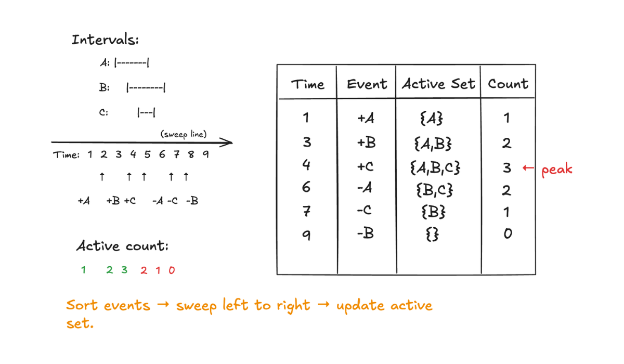>

In [ ]:
def max_overlap(intervals):
    events = []
    for s, e in intervals:
        events.append((s, 1))    # interval starts → +1
        events.append((e, -1))   # interval ends   → -1

    # sort by time; if tie, process 'end' (-1) before 'start' (+1)
    events.sort(key=lambda x: (x[0], x[1]))

    active = max_active = 0
    for _, v in events:
        active += v
        max_active = max(max_active, active)

    return max_active

max_overlap([[1,3],[2,5],[3,6],[4,8]])  # 3

## Pattern 42 — Geometry Patterns
**Importance:** ★★★

### Story
You're building a GPS system that needs to find the closest two delivery trucks among 1 million vehicles scattered across a city. Or a self-driving car that must compute which obstacle is about to collide with it. Geometry algorithms solve this in $O(n \log n)$ instead of $O(n^2)$ brute force. These patterns leverage **orientation**, **cross products**, and **coordinate systems** to solve spatial problems elegantly—the hidden math behind graphics, robotics, and navigation.

### When to Use
- Convex hull and boundary computation
- Closest pair of points (nearest neighbor search)
- Line segment intersection detection
- Point-in-polygon tests
- Angle and orientation computation
- Polygon area and centroid calculation
- Coordinate geometry and sweep line with geometry

### Core Idea
- **Cross product** (orientation): Determine if point C is left/right of line AB → $\text{sign}((B_x - A_x)(C_y - A_y) - (B_y - A_y)(C_x - A_x))$
- **Distance formula**: $d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$ or squared distance for efficiency
- **Convex hull**: Sort by angle, use monotone stack to eliminate non-convex points
- **Sweep line + geometry**: Combine event sorting with coordinate transformations for collision detection

### Pitfalls
- Floating-point precision errors accumulating through geometric calculations (use integer arithmetic when possible)
- Incorrectly handling **collinear points** (three points on a line)
- Off-by-one in angle sorting or stack management in convex hull
- Confusing cross product sign convention (clockwise vs counterclockwise)
- Edge cases: degenerate inputs (all points same, duplicate points, vertical/horizontal lines)

### Example
**Closest pair of points**: Points = [(0,0), (1,1), (10,10), (11,11)]

**Graham scan convex hull**: Start from lowest point, sort by polar angle, keep only left turns → Result: [(0,0), (11,11), (10,10)] (3 corners)

![][image1]

[image1]: <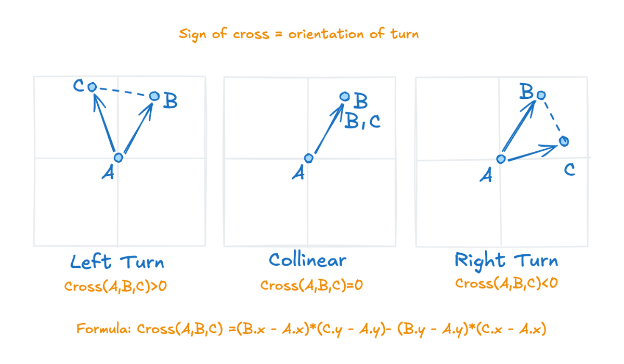>

In [ ]:
import math

# ============================================================================
# PATTERN 42 — GEOMETRY PATTERNS: Four Essential Building Blocks
# ============================================================================

# ─────────────────────────────────────────────────────────────────────────
# 1. ORIENTATION: Cross Product (Which way would you turn?)
# ─────────────────────────────────────────────────────────────────────────
# The cross product tells you which way you'd have to turn to walk from A→B→C
# Return 1 (left turn), -1 (right turn), or 0 (collinear/straight through)

def orientation(A, B, C):
    """
    Compute the orientation of the ordered triplet (A, B, C).
    
    Returns:
        1  → Counterclockwise (left turn)
        -1 → Clockwise (right turn)
        0  → Collinear (all three points on same line)
    """
    val = (B[0] - A[0]) * (C[1] - A[1]) - (B[1] - A[1]) * (C[0] - A[0])
    if val == 0:
        return 0  # Collinear
    return 1 if val > 0 else -1  # 1 = CCW, -1 = CW


# Test orientation
print("=" * 60)
print("1. ORIENTATION (Cross Product)")
print("=" * 60)
print(f"orientation((0,0), (1,0), (1,1)) = {orientation((0, 0), (1, 0), (1, 1))}")
print("  → 1 = left turn (counterclockwise)")
print(f"orientation((0,0), (1,0), (1,-1)) = {orientation((0, 0), (1, 0), (1, -1))}")
print("  → -1 = right turn (clockwise)")
print(f"orientation((0,0), (1,0), (2,0)) = {orientation((0, 0), (1, 0), (2, 0))}")
print("  → 0 = collinear (on same line)\n")


# ─────────────────────────────────────────────────────────────────────────
# 2. DISTANCE: Euclidean Distance Between Two Points
# ─────────────────────────────────────────────────────────────────────────
# Standard Pythagorean formula. Tip: when comparing distances, skip sqrt()
# and just compare squared distances—it's faster and avoids float precision.

def dist(p1, p2):
    """
    Compute Euclidean distance between two points p1 and p2.
    """
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)


def dist_squared(p1, p2):
    """
    Compute squared distance (faster for comparisons, avoids float imprecision).
    Use this when you only need to compare distances, not the actual value.
    """
    return (p1[0] - p2[0])**2 + (p1[1] - p2[1])**2


print("=" * 60)
print("2. DISTANCE")
print("=" * 60)
print(f"dist((0,0), (3,4)) = {dist((0, 0), (3, 4))}")
print("  → Classic 3-4-5 right triangle")
print(f"dist_squared((0,0), (3,4)) = {dist_squared((0, 0), (3, 4))}")
print("  → Avoid sqrt() for comparisons!\n")


# ─────────────────────────────────────────────────────────────────────────
# 3. CLOSEST PAIR: Brute Force O(n²) Algorithm
# ─────────────────────────────────────────────────────────────────────────
# Check every pair of points, keep the pair with the smallest gap.
# Like a lifeguard scanning every pair of swimmers for the two closest.
# Simple, correct, and fine up to ~1,000 points.

def closest_pair(points):
    """
    Find the pair of points with minimum distance (brute force).
    
    Time: O(n²) — fine for small inputs (~1,000 points)
    For millions of points, use divide-and-conquer: O(n log n)
    
    Returns:
        (pair_tuple, min_distance)
    """
    n = len(points)
    best_dist = float('inf')
    best_pair = None
    
    for i in range(n):
        for j in range(i + 1, n):
            d = dist(points[i], points[j])
            if d < best_dist:
                best_dist = d
                best_pair = (points[i], points[j])
    
    return best_pair, best_dist


print("=" * 60)
print("3. CLOSEST PAIR")
print("=" * 60)
points = [(0, 0), (1, 1), (10, 10), (11, 11)]
pair, min_dist = closest_pair(points)
print(f"Points: {points}")
print(f"Closest pair: {pair}")
print(f"Distance: {min_dist:.4f}\n")


# ─────────────────────────────────────────────────────────────────────────
# 4. CONVEX HULL: Monotone Chain Algorithm (Andrew's Algorithm)
# ─────────────────────────────────────────────────────────────────────────
# Sort points left to right, then build the bottom edge and top edge,
# throwing away any point that would create a right turn (non-convex bend).
# More robust than Graham scan (avoids polar angle precision headaches).

def convex_hull(points):
    """
    Compute the convex hull of a set of 2D points.
    Uses the Monotone Chain algorithm (Andrew's algorithm).
    
    Algorithm:
    1. Sort points by x-coordinate (left to right)
    2. Build lower hull: left to right, keeping only left turns
    3. Build upper hull: right to left, keeping only left turns
    4. Concatenate and return
    
    Time: O(n log n) due to sorting
    Space: O(n) for output hull
    
    Returns:
        List of points forming the convex hull (counterclockwise order)
    """
    # Remove duplicates and sort by x, then by y
    points = sorted(set(points))
    
    if len(points) <= 2:
        return points
    
    def build_half_hull(seq):
        """
        Build one half of the convex hull (lower or upper).
        Keep only strict left turns (orientation > 0).
        """
        hull = []
        for p in seq:
            # Pop the last point while it doesn't form a strict left turn
            while len(hull) >= 2 and orientation(hull[-2], hull[-1], p) <= 0:
                hull.pop()
            hull.append(p)
        return hull
    
    # Build lower and upper hulls
    lower = build_half_hull(points)
    upper = build_half_hull(reversed(points))
    
    # Concatenate (skip duplicate endpoints)
    return lower[:-1] + upper[:-1]


print("=" * 60)
print("4. CONVEX HULL")
print("=" * 60)

# Example 1: Square with extra collinear point
print("Example 1: Square with a point on the edge")
pts1 = [(0, 0), (2, 0), (2, 2), (0, 2), (1, 0)]
hull1 = convex_hull(pts1)
print(f"Points: {pts1}")
print(f"Convex hull: {hull1}")
print("  → (1,0) correctly excluded (collinear with (0,0) and (2,0))\n")

# Example 2: Collinear points (degenerate case)
print("Example 2: All collinear points (y = x line)")
pts2 = [(0, 0), (1, 1), (10, 10), (11, 11)]
hull2 = convex_hull(pts2)
print(f"Points: {pts2}")
print(f"Convex hull: {hull2}")
print("  → Degenerates to just the two extremes (only a line segment)\n")

# Example 3: Triangle (generic case)
print("Example 3: Triangle")
pts3 = [(0, 0), (4, 0), (2, 3)]
hull3 = convex_hull(pts3)
print(f"Points: {pts3}")
print(f"Convex hull: {hull3}")
print("  → All three points form the hull (every point is a corner)\n")

## Pattern 43 — Trie-Based Backtracking: Power of Early Pruning
**Importance: ★★★★★** (Critical for board/grid searches)

### Story: Finding Words Hidden in a Scrambled Tile Board

Imagine you're building an autocorrect engine for Boggle—a word puzzle game with a $4 \times 4$ grid of letter tiles. Players can form words by connecting adjacent tiles. You need to:

1. **Search for ALL valid English words** that can be formed by tracing adjacent tiles
2. **Avoid dead ends** — if you follow the path A→C→Z→?, but "ACZ" is not a prefix of ANY English word, you're wasting time exploring further
3. **Mark tiles as "used"** during DFS so you don't reuse the same tile in one word

The breakthrough insight: **Combine a Trie (prefix dictionary) with DFS backtracking**. As you trace a path, check the Trie at each step. If your current prefix doesn't exist in the Trie, prune that entire branch—no need to explore further down that path. This transforms an exponential search into something practical.

### When to Use

- **Word Search II (LeetCode)** — find all words in a list that exist on an $m \times n$ board
- **Boggle solver** — enumerate valid words from scrambled tiles
- **Autocomplete on grid layouts** — mobile keyboards, phone dialing
- **Prefix-constrained DFS** — anywhere you need to prune invalid branches early

### Core Idea

**Trie-Backed DFS Pruning**

1. **Build a Trie** from a dictionary of valid words
2. **DFS from each cell** on the board:
   - Move to neighbor cells, building a path string
   - **At each step, check if the prefix exists in the Trie**
   - If NO: prune (don't explore further)
   - If YES and word is complete: save it (mark visited to avoid duplicates)
3. **Restore board state** after recursion (mark cell as unvisited)

**Time Complexity**: Without Trie, $O(4^{m \cdot n})$ (exponential backtracking). With Trie pruning, typically $O(m \cdot n \cdot L)$ where $L$ is average word length (dramatic speedup for sparse word lists).

### Pitfalls

1. **Forgetting to restore visited state** — After exploring a cell, mark it unvisited (`board[i][j] = letter`). If you don't, later recursions see it as "taken."
2. **Not removing words from Trie after finding them** — If you find "cat" once, remove it to avoid duplicates in the result.
3. **Exploring same prefix multiple times** — Use a `visited` set to avoid duplicate results per starting position.
4. **Off-by-one in bounds checking** — Grid borders and neighbor iteration are common traps.
5. **Trie not built correctly** — Empty Trie or missing words means the pruning fails silently (returns partial results).

### Examples

**Example: Word Search II**  
Given board: `[['o','a','a'],['e','t','a'],['t','a','t']]` and words: `['oath','boat','eat','ta','oate']`  
Expected output: `['eat','oath']` (only these are findable on the board; others have letter sequences that don't exist as prefixes in the path)

**Why Trie Matters**: Without Trie, DFS explores every possible path (even nonsense like O→A→E→T→A→T). With Trie, once you build "OAE...", and "OAE" is not in the dictionary, the algorithm prunes that entire subtree. Huge speedup.

![][image1]

[image1]: <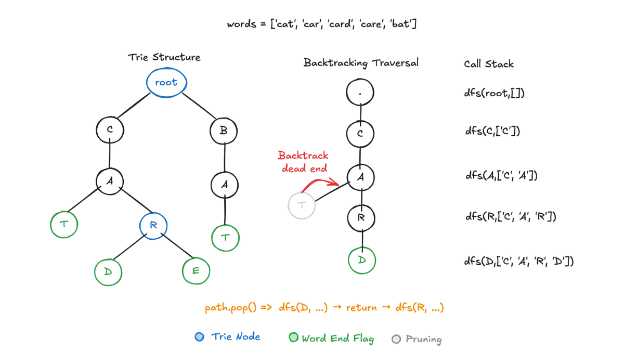>

In [ ]:
def find_words(board, words):
    # Build trie: nested dicts, '$' marks "a full word ends here"
    trie = {}
    for w in words:
        node = trie
        for ch in w:
            node = node.setdefault(ch, {})
        node['$'] = w   # store the word itself at the end node

    R, C = len(board), len(board[0])
    res = []

    def dfs(r, c, node):
        ch = board[r][c]
        if ch not in node:
            return
        node = node[ch]

        if '$' in node:
            res.append(node['$'])
            node['$'] = None   # avoid duplicate matches

        board[r][c] = '#'   # mark visited (same role as a `seen` set)
        for dr, dc in [(1,0), (-1,0), (0,1), (0,-1)]:
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and board[nr][nc] != '#':
                dfs(nr, nc, node)
        board[r][c] = ch   # backtrack: unmark so other paths can use this cell

    for r in range(R):
        for c in range(C):
            dfs(r, c, trie)

    return res

board = [
    ['o','a','a','n'],
    ['e','t','a','e'],
    ['i','h','k','r'],
    ['i','f','l','v']
]
words = ["oath", "pea", "eat", "rain"]

print(find_words(board, words))
# ['oath', 'eat']

## Pattern 44 — Greedy Algorithms: Always Take the Best Option Now
**Importance: ★★★★★** (Critical for optimization and selection problems)

### Story: Scheduling Conference Rooms to Fit Maximum Presentations

Imagine you manage a conference center with one auditorium. You receive 50 presentation requests, each with a start time and end time. Your goal: **accept the maximum number of non-overlapping presentations**.

The naive approach: try all $2^{50}$ subsets and find the largest non-overlapping one. That's exponential.

The greedy insight: **Always pick the presentation that ends the soonest.** Why? Because:
- Ending early frees up the room sooner
- You have more time to fit additional presentations afterward
- Early finishers never block later talks unnecessarily

**Sort presentations by end time.** Iterate through:
1. Accept the first presentation
2. For each subsequent presentation: if it starts after the current one ends, accept it
3. Update the "current room is free at" timestamp

Result: **Optimal scheduling in $O(n \log n)$ time.** No dynamic programming needed.

This is the **Activity Selection Problem**, a canonical greedy algorithm. It works because the problem has the **greedy-choice property**: making the locally optimal choice (earliest ending) leads to a globally optimal solution.

### When to Use

- **Activity Selection / Jump Game** — maximize count of non-overlapping intervals
- **Interval Scheduling** — assign resources to maximum compatible tasks
- **Huffman Coding** — build optimal prefix-free binary codes
- **Fractional Knapsack** — pick items by value-to-weight ratio
- **Job Sequencing with Deadlines** — maximize profit with deadline constraints
- **Minimum Coin Change** (some cases) — fewest coins to make amount
- **Greedy Coloring / Graph Algorithms** — approximate chromatic number

### Core Idea

**Greedy-Choice Property + Optimal Substructure**

A problem is solvable by greedy if:

1. **Greedy-Choice Property**: Making a locally optimal choice (e.g., "pick earliest end time") leads to a globally optimal solution
2. **Optimal Substructure**: After a greedy choice, the remaining problem is an instance of the same problem (smaller scope)

**Algorithm Pattern:**
```
1. Sort or order choices by some criterion (e.g., end time, ratio, deadline)
2. Iterate and greedily pick the best feasible option
3. Update constraints (e.g., "current time") and repeat
4. Return accumulated result
```

**Why It Breaks** (Critical!):
- If you pick by the **wrong criterion**, greedy fails. Example: activity selection by *start time* (earliest start) is suboptimal — early starters might be long, blocking many later ones.
- If **no greedy-choice property exists** (e.g., 0/1 Knapsack, Traveling Salesman), greedy gives wrong answers → use DP or exact algorithms instead.

**Time Complexity**: Usually $O(n \log n)$ (sorting) + $O(n)$ (iteration) = $O(n \log n)$ for greedy. Much faster than DP's $O(n^2)$ or exponential backtracking.

### Pitfalls

1. **Applying greedy when DP is needed** — 0/1 Knapsack and TSP *look* like greedy problems but aren't. Greedy gives wrong answers. Test on small cases to verify.
2. **Wrong ordering criterion** — Picking by start time instead of end time (or value instead of ratio) ruins the solution. Verify your sorting key is correct.
3. **Not checking optimality** — Greedy is a heuristic. **Verify mathematically** that your greedy choice is always safe (doesn't exclude better solutions).
4. **Forgetting constraints** — Activity selection works because intervals are independent. If there are capacity constraints ("only 2 rooms") or weighted profits, greedy may fail.
5. **Off-by-one in boundaries** — When merging intervals or updating time: is it `end_time` or `end_time + 1`? Off-by-one errors break overlap detection.
6. **Not handling ties** — If two activities have the same end time, the order matters. Decide consistently (e.g., by start time as tiebreaker).

### Examples

**Example 1: Activity Selection / Interval Scheduling**

Activities: `[(1, 3), (2, 5), (4, 6), (6, 7), (5, 8)]` (start, end)

Greedy by end time:
1. Pick (1, 3) — ends earliest at 3
2. Next available ≥ 3: (4, 6) and (6, 7) qualify; pick (4, 6) — ends earliest
3. Next available ≥ 6: (6, 7) qualifies; pick it — ends at 7
4. Next available ≥ 7: none (5, 8) starts at 5 < 7

**Result:** 3 activities selected. Optimal!

Contrast: greedy by start time picks (1, 3), then (2, 5) is too early, then (4, 6), then (6, 7) — same result. But a different ordering could fail.

**Example 2: Jump Game — Can you reach the last index?**

Array: `[2, 3, 1, 1, 4]` (index 0 = value 2 means you can jump up to 2 steps)

Greedy: track farthest reachable index.
- Start at index 0: can reach indices 1–2
- At index 1 (value 3): can reach up to index 4
- Farthest = 4 (last index)

**Result:** Yes, reachable! Greedy works here.

**Why it works:** If you're at position $i$ with value $v$, jumping to any index $i < j \leq i + v$ is equally safe. Picking greedily (jumping as far as possible) maximizes your reachable horizon.

![][image1]

[image1]: <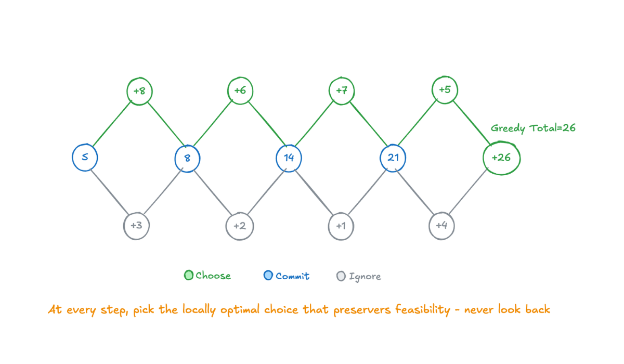>

In [ ]:
# ============================================================================
# PATTERN 44 — GREEDY ALGORITHMS: Three Essential Strategies
# ============================================================================

print("=" * 80)
print("PATTERN 44: GREEDY ALGORITHMS — Always Take the Best Option Now")
print("=" * 80)

# ─────────────────────────────────────────────────────────────────────────
# 1. JUMP GAME — Work Backward from the Goal
# ─────────────────────────────────────────────────────────────────────────
# Strategy: If some position can reach the current goal, that position becomes
# the new goal, shrinking the problem until you either reach the start or can't.

def can_jump(nums):
    """
    Determine if you can reach the last index of an array.
    Each element is the maximum jump length from that position.
    Greedy strategy: work backward, shrinking the reachable goal.
    """
    goal = len(nums) - 1  # Start from the last index
    for i in range(len(nums) - 2, -1, -1):
        if i + nums[i] >= goal:
            goal = i  # This position can reach (or pass) the goal
    return goal == 0  # Success if we can reach index 0

print("\n" + "─" * 80)
print("1. JUMP GAME: Can you reach the last index?")
print("─" * 80)

test1 = [2, 3, 1, 1, 4]
result1 = can_jump(test1)
print(f"Array: {test1}")
print(f"Can jump to end? {result1}")
print(f"  → Yes! Index 0 (val 2) can jump to 1 or 2.")
print(f"    Index 1 (val 3) can jump to index 4 (goal).")

test2 = [3, 2, 1, 0, 4]
result2 = can_jump(test2)
print(f"\nArray: {test2}")
print(f"Can jump to end? {result2}")
print(f"  → No. Index 3 has value 0 (can't jump).")
print(f"    No previous index can jump over it to reach index 4.")

print("\nTrace on [3,2,1,0,4]:")
print("  goal = 4 (last index)")
print("  i=3: 3 + nums[3] = 3+0 = 3, not ≥ 4 → goal stays 4")
print("  i=2: 2 + nums[2] = 2+1 = 3, not ≥ 4 → goal stays 4")
print("  i=1: 1 + nums[1] = 1+2 = 3, not ≥ 4 → goal stays 4")
print("  i=0: 0 + nums[0] = 0+3 = 3, not ≥ 4 → goal stays 4")
print("  Final goal = 4 ≠ 0 → False (blocked by the 0)\n")


# ─────────────────────────────────────────────────────────────────────────
# 2. ACTIVITY SELECTION — Always Pick the Earliest Finishing Activity
# ─────────────────────────────────────────────────────────────────────────
# Strategy: Always pick the activity that finishes earliest.
# Finishing early leaves the most room for everything after it.
# Optimal substructure: after picking one, the remaining problem is identical.

def activity_selection(activities):
    """
    Select the maximum number of non-overlapping activities.
    Greedy criterion: sort by end time, always pick earliest finisher.
    Time: O(n log n) for sorting + O(n) for iteration
    """
    if not activities:
        return []
    
    activities.sort(key=lambda x: x[1])  # Sort by end time
    selected = [activities[0]]
    last_end = activities[0][1]
    
    for start, end in activities[1:]:
        if start >= last_end:  # No overlap if new start ≥ last end
            selected.append((start, end))
            last_end = end
    
    return selected

print("=" * 80)
print("2. ACTIVITY SELECTION: Pick Max Non-Overlapping Activities")
print("=" * 80)

acts = [
    (1, 4), (3, 5), (0, 6), (5, 7), (5, 9),
    (3, 9), (6, 10), (8, 11), (8, 12), (2, 14), (12, 16)
]
print(f"Activities (start, end): {acts}")
selected = activity_selection(acts)
print(f"Selected (max non-overlapping): {selected}")
print(f"  Count: {len(selected)} activities")

print("\nTrace:")
acts_sorted = sorted(acts, key=lambda x: x[1])
print(f"  Sorted by end time: {acts_sorted}")
print(f"  Pick (1,4) → last_end=4")
print(f"  Skip (3,5): starts at 3 < 4 (overlaps)")
print(f"  Skip (0,6): starts at 0 < 4 (overlaps)")
print(f"  Pick (5,7) → last_end=7 (starts at 5 ≥ 4 ✓)")
print(f"  Skip (5,9), (3,9), (6,10): all start < 7")
print(f"  Pick (8,11) → last_end=11 (starts at 8 ≥ 7 ✓)")
print(f"  Skip (8,12), (2,14): overlap with 11")
print(f"  Pick (12,16) → last_end=16 (starts at 12 ≥ 11 ✓)")
print(f"  Result: 4 non-overlapping — optimal!\n")


# ─────────────────────────────────────────────────────────────────────────
# 3. MINIMUM MEETING ROOMS — Sweep Line for Peak Overlap
# ─────────────────────────────────────────────────────────────────────────
# Strategy: Track meetings starting/ending at each time.
# The peak number of concurrent meetings = minimum rooms needed.
# Greedy insight: process events in order, track current occupancy.

def min_meeting_rooms(intervals):
    """
    Find minimum number of meeting rooms needed for all meetings.
    Greedy strategy: sweep through timeline, track peak overlap.
    Events: +1 for start, -1 for end. Sort so ends process before starts on ties.
    """
    if not intervals:
        return 0
    
    events = []
    for start, end in intervals:
        events.append((start, 1))    # Meeting starts (+1 room needed)
        events.append((end, -1))     # Meeting ends (-1 room freed)
    
    # Sort by time; on tie, process ends (-1) before starts (+1)
    # This ensures meeting [0,1] and [1,2] use 1 room, not 2
    events.sort(key=lambda x: (x[0], x[1]))
    
    rooms = 0
    max_rooms = 0
    for _, delta in events:
        rooms += delta
        max_rooms = max(max_rooms, rooms)
    
    return max_rooms

print("=" * 80)
print("3. MINIMUM MEETING ROOMS: Peak Occupancy Problem")
print("=" * 80)

meetings = [(0, 30), (5, 10), (15, 20)]
print(f"Meetings (start, end): {meetings}")
min_rooms = min_meeting_rooms(meetings)
print(f"Minimum rooms needed: {min_rooms}")

print("\nTrace:")
events = [(0, 1), (5, 1), (10, -1), (15, 1), (20, -1), (30, -1)]
events_sorted = sorted(events, key=lambda x: (x[0], x[1]))
print(f"  Events (time, delta): {events_sorted}")
rooms_history = [0]
current_rooms = 0
for t, delta in events_sorted:
    current_rooms += delta
    rooms_history.append(current_rooms)
    print(f"    t={t:2d}: rooms {rooms_history[-2]} → {current_rooms} (delta {delta:+2d})")
print(f"  Peak = {min_rooms} rooms")
print(f"  Why: Meetings (0,30) and (5,10) overlap at times 5-10 → need 2 rooms.")
print(f"       Meeting (15,20) starts after (0,30) ends, but we still had (0,30) running.\n")

# Example with 3 overlapping meetings
print("Example 2 (deeper overlap):")
meetings2 = [(1, 3), (2, 6), (8, 9), (8, 10), (9, 10), (9, 10)]
min_rooms2 = min_meeting_rooms(meetings2)
print(f"Meetings: {meetings2}")
print(f"Minimum rooms needed: {min_rooms2}")
print(f"  Peak is at t≈8-9: (2,6) still running, then (8,9), (8,10), (9,10)x2 start.")

print("\n" + "=" * 80)
print("SUMMARY: Greedy Wins When")
print("=" * 80)
print("✓ Jump Game: Backward greedy proves reachability instantly")
print("✓ Activity Selection: Early-finishing = more room for others")
print("✓ Meeting Rooms: Sweep-line greedy finds peak occupancy in one pass")
print("✗ NOT: 0/1 Knapsack, Traveling Salesman, Coin Change (all cases)")
print("  → These need Dynamic Programming or Exact algorithms")
print("=" * 80)

## Pattern 45 — Matrix Traversal

**Importance:** ★★★★★

### Story
Imagine a vast rectangular grid of tiles stretching before you — rows and columns in every direction. You could walk straight across, left to right, then down to the next row. Or you could spiral inward from the edges, layer by layer, like peeling an onion. Or flip the whole grid upside down, or rotate it clockwise, or read it diagonally like a chessboard's knights' moves. Each traversal pattern reveals the grid in a different order. The challenge is to control your movement rules so you visit every tile exactly once and never get lost. Matrix problems test your ability to track indices, respect boundaries, update them as you go, and handle edge cases without confusion.

### When to Use
*   Spiral matrix order (clockwise or counter-clockwise)
*   Rotate image 90° (or by k steps)
*   Set zeroes: mark rows and columns in-place
*   Diagonal traversals
*   Zigzag patterns (up-down, left-right)
*   Transpose operations
*   BFS/DFS on a grid with direction vectors

### Core Idea
Use direction vectors `[(0,1), (1,0), (0,-1), (-1,0)]` for grid traversal. For spiral, update boundaries after each direction. For rotation, use layer-by-layer or transpose + reverse. For in-place marking, use first row/column as markers plus one flag cell.

### Pitfalls
*   Off-by-one errors on row/column indices
*   Forgetting to update boundary limits after visiting each layer
*   Not handling edge cases (1×1, 1×n, n×1 matrices)
*   Modifying the matrix in-place when you shouldn't, or vice versa
*   Confusion between row-major and column-major order

### Mini Example
**Example:** Spiral order of a 3×3 matrix:
```
1 2 3        1 → 2 → 3
4 5 6   ⟹     ↓ ↘ ↓
7 8 9        4 → 5 → 6
                   ↓
             7 ← 8 ← 9
Output: [1, 2, 3, 6, 9, 8, 7, 4, 5]
```

**Rotation Example:** Rotate 90° clockwise:
```
1 2 3        7 4 1
4 5 6   ⟹    8 5 2
7 8 9        9 6 3
```
After rotate: rows become reversed columns.

![][image1]

[image1]: <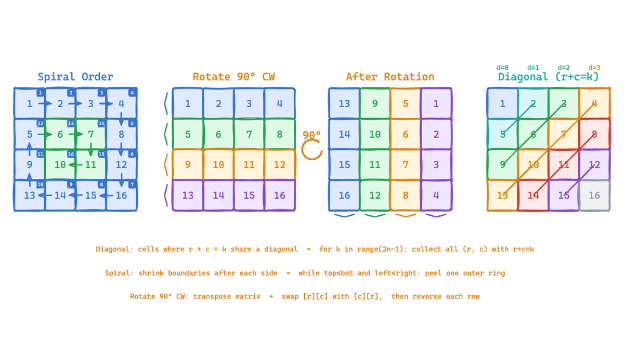>

In [ ]:
"""
Pattern 45 — Matrix Traversal (Part 1: Spiral Order)

STORY: "Walk right until you hit a wall, turn down, walk until you hit a wall, 
turn left, walk, turn up, walk — and after every full lap, shrink the walls inward."
"""

def spiral_order(matrix):
    """
    Return elements in spiral order (clockwise from outside → inside).
    
    Core Idea:
    - Start with full boundaries: top=0, bottom=len(rows)-1, left=0, right=len(cols)-1
    - Walk right along top, then right column, then bottom (if rows remain), then left column (if cols remain)
    - After each direction, shrink that boundary inward
    - Repeat until all cells visited
    """
    res = []
    top, bottom = 0, len(matrix) - 1
    left, right = 0, len(matrix[0]) - 1

    #[
    # [1,2],
    # [3,4]
    #]

    while top <= bottom and left <= right:
        # Walk right along top row
        for c in range(left, right + 1):
            res.append(matrix[top][c])
        top += 1

        # Walk down along right column
        for r in range(top, bottom + 1):
            res.append(matrix[r][right])
        right -= 1

        # Walk left along bottom row (only if a row still remains)
        if top <= bottom:
            for c in range(right, left - 1, -1):
                res.append(matrix[bottom][c])
            bottom -= 1

        # Walk up along left column (only if a column still remains)
        if left <= right:
            for r in range(bottom, top - 1, -1):
                res.append(matrix[r][left])
            left += 1

    return res


# Example 1: 3×3 Matrix
print("=" * 60)
print("1. SPIRAL ORDER: Classic 3×3 Matrix")
print("=" * 60)
matrix = [[1, 2, 3], [4, 5, 6], [7, 8, 9]]
print(f"Input matrix:\n{matrix}")
result = spiral_order(matrix)
print(f"\nSpiral order: {result}")
print(f"Expected:     [1, 2, 3, 6, 9, 8, 7, 4, 5]")
print(f"Match: {result == [1, 2, 3, 6, 9, 8, 7, 4, 5]} ✓")

print("\nTrace:")
print("  top=0, bottom=2, left=0, right=2")
print("  → Right along row 0: [1,2,3]        top→1")
print("  → Down along col 2:  [6,9]          right→1")
print("  → Left along row 2:  [8,7]          bottom→1")
print("  → Up along col 0:    [4]            left→1")
print("  → Loop check: top=1≤bottom=1 & left=1≤right=1 (one more lap)")
print("  → Right along row 1, col 1: [5]     top→2")
print("  → Stop: top=2 > bottom=1")

# Example 2: 2×3 Rectangular Matrix
print("\n" + "=" * 60)
print("2. SPIRAL ORDER: Rectangular 2×3 Matrix")
print("=" * 60)
matrix2 = [[1, 2, 3], [4, 5, 6]]
print(f"Input matrix:\n{matrix2}")
result2 = spiral_order(matrix2)
print(f"Spiral order: {result2}")
print(f"Expected:     [1, 2, 3, 6, 5, 4]")
print(f"Match: {result2 == [1, 2, 3, 6, 5, 4]} ✓")
print("\nNote: if statements (if top ≤ bottom and if left ≤ right) prevent")
print("re-walking already-visited rows/columns on the last lap.")

In [ ]:
"""
Pattern 45 — Matrix Traversal (Part 2: Rotate 90° Clockwise)

STORY: "Rotating clockwise is the same as flipping the matrix along its diagonal 
(transpose), then mirroring each row left-to-right."

Key Insight: Rotate = Transpose + Reverse Each Row
  Original:       Transposed:     After Reversing Rows:
  1 2 3           1 4 7           7 4 1
  4 5 6    →      2 5 8    →      8 5 2
  7 8 9           3 6 9           9 6 3
"""

def rotate(matrix):
    """
    Rotate matrix 90° clockwise IN-PLACE.
    
    Algorithm:
    1. Transpose: swap matrix[i][j] with matrix[j][i] for all i < j
    2. Reverse each row in-place
    
    Time: O(n²) | Space: O(1) (in-place, no extra data structure)
    """
    n = len(matrix)

    # Step 1: Transpose — swap matrix[i][j] with matrix[j][i]
    # Note: j starts from i+1 (not 0) to avoid swapping pairs twice
    for i in range(n):
        for j in range(i + 1, n):
            matrix[i][j], matrix[j][i] = matrix[j][i], matrix[i][j]

    # Step 2: Reverse each row
    for row in matrix:
        row.reverse()

    return matrix


# Example 1: 3×3 Matrix Rotation
print("\n" + "=" * 60)
print("3. ROTATE 90° CLOCKWISE: 3×3 Matrix")
print("=" * 60)
matrix_orig = [[1, 2, 3], [4, 5, 6], [7, 8, 9]]
matrix = [row[:] for row in matrix_orig]  # Deep copy
print(f"Input:\n{matrix_orig}")
result = rotate(matrix)
print(f"\nRotated 90° clockwise:\n{result}")
print(f"Expected:\n[[7, 4, 1], [8, 5, 2], [9, 6, 3]]")
print(f"Match: {result == [[7, 4, 1], [8, 5, 2], [9, 6, 3]]} ✓")

print("\nTrace:")
print("  Step 1 (Transpose):")
print("    Swap matrix[i][j] ↔ matrix[j][i] for i < j")
print("    Result: [[1, 4, 7], [2, 5, 8], [3, 6, 9]]")
print("  Step 2 (Reverse each row):")
print("    row[0].reverse(): [1,4,7] → [7,4,1]")
print("    row[1].reverse(): [2,5,8] → [8,5,2]")
print("    row[2].reverse(): [3,6,9] → [9,6,3]")

# Example 2: 4×4 Matrix Rotation
print("\n" + "=" * 60)
print("4. ROTATE 90° CLOCKWISE: 4×4 Matrix")
print("=" * 60)
matrix_4x4 = [
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12],
    [13, 14, 15, 16]
]
matrix_copy = [row[:] for row in matrix_4x4]
print(f"Input:\n{matrix_4x4}")
result_4x4 = rotate(matrix_copy)
print(f"\nRotated 90° clockwise:\n{result_4x4}")
print("\nCritical Detail: j in range(i+1, n) prevents swapping pairs twice.")
print("If j started from 0 (like range(n)), each pair would be swapped twice,")
print("reversing the transpose back to the original!")

In [ ]:
"""
Pattern 45 — Matrix Traversal (Part 3: Set Matrix Zeroes)

STORY: "Before you overwrite a row or column with zeroes, first record which 
rows and columns need it — otherwise your own zeroes will trick later cells into 
thinking they need zeroing too."

Challenge: Modify matrix in-place with O(1) extra space (not O(m+n) flag arrays).
Solution: Use first row and first column AS the flags, plus two boolean flags 
to remember if row 0 or column 0 themselves originally had a zero.
"""

def set_matrix_zeroes(matrix):
    """
    Given an m×n matrix, if an element is 0, set its entire row and column to 0.
    Do it IN-PLACE with O(1) extra space.
    
    Algorithm:
    1. Save whether row 0 or col 0 originally contain a zero (using two booleans).
    2. Scan the rest (rows 1..m, cols 1..n). If cell is 0, mark its row and column
       in the row 0 and col 0 positions.
    3. Scan again: if row marker or col marker is 0, zero the cell.
    4. Finally, handle row 0 and col 0 themselves using the saved booleans.
    
    Time: O(m*n) | Space: O(1) (no extra data structure)
    """
    R, C = len(matrix), len(matrix[0])
    
    # Save whether first row/col originally have a zero
    first_row_has_zero = any(matrix[0][c] == 0 for c in range(C))
    first_col_has_zero = any(matrix[r][0] == 0 for r in range(R))

    # Use row 0 and col 0 as markers for the rest of the matrix
    for r in range(1, R):
        for c in range(1, C):
            if matrix[r][c] == 0:
                matrix[r][0] = 0  # Mark the row
                matrix[0][c] = 0  # Mark the column

    # Zero out cells based on markers in row 0 and col 0
    for r in range(1, R):
        for c in range(1, C):
            if matrix[r][0] == 0 or matrix[0][c] == 0:
                matrix[r][c] = 0

    # Handle row 0 itself (if it originally had a zero)
    if first_row_has_zero:
        for c in range(C):
            matrix[0][c] = 0

    # Handle col 0 itself (if it originally had a zero)
    if first_col_has_zero:
        for r in range(R):
            matrix[r][0] = 0

    return matrix


# Example 1: Simple Case (zero in the middle)
print("\n" + "=" * 60)
print("5. SET MATRIX ZEROES: Zero in Middle")
print("=" * 60)
matrix1 = [[1, 1, 1], [1, 0, 1], [1, 1, 1]]
print(f"Input:\n{matrix1}")
result1 = set_matrix_zeroes(matrix1)
print(f"\nOutput (entire row 1 and column 1 zeroed):\n{result1}")
expected1 = [[1, 0, 1], [0, 0, 0], [1, 0, 1]]
print(f"Expected:\n{expected1}")
print(f"Match: {result1 == expected1} ✓")

# Example 2: Multiple Zeroes
print("\n" + "=" * 60)
print("6. SET MATRIX ZEROES: Multiple Zeroes")
print("=" * 60)
matrix2 = [[0, 1, 2, 0], [3, 4, 5, 2], [1, 3, 1, 5]]
print(f"Input:\n{matrix2}")
result2 = set_matrix_zeroes([row[:] for row in matrix2])  # Deep copy
print(f"\nOutput (rows 0 & columns 0, 3 zeroed):\n{result2}")
print("\nWhy we need the two booleans (first_row_has_zero, first_col_has_zero):")
print("  - Row 0 and col 0 are THEMSELVES being used as marker storage.")
print("  - If row 0 originally had a 0, we need to remember BEFORE we overwrite it.")
print("  - If col 0 originally had a 0, we need to remember BEFORE we overwrite it.")
print("  - Without these flags, we'd lose that information and miss some zeroes!")

# Example 3: Edge case – zero only in first row
print("\n" + "=" * 60)
print("7. SET MATRIX ZEROES: Zero in First Row")
print("=" * 60)
matrix3 = [[1, 0, 3], [4, 5, 6], [7, 8, 9]]
print(f"Input:\n{matrix3}")
result3 = set_matrix_zeroes([row[:] for row in matrix3])  # Deep copy
print(f"\nOutput (entire first row and column 1 zeroed):\n{result3}")
expected3 = [[0, 0, 0], [4, 0, 6], [7, 0, 9]]
print(f"Expected:\n{expected3}")
print(f"Match: {result3 == expected3} ✓")
print("\nWithout the first_row_has_zero flag, row 0 would not have been fully zeroed!")

print("\n" + "=" * 60)
print("SUMMARY: Matrix Traversal Patterns")
print("=" * 60)
print("✓ Spiral:        Shrink boundaries after each direction.")
print("✓ Rotate 90°:    Transpose + Reverse rows (O(1) space).")
print("✓ Set Zeroes:    Use first row/col as markers + 2 flags (O(1) space).")
print("✓ Key Pitfall:   Off-by-one errors & forgotten boundary updates.")
print("=" * 60)

## Pattern 46 — Recursion Template

**Importance:** ★★★★★

### Story
Imagine you're exploring a tree of cave passages. Each passage either leads to a dead end (base case) or branches into smaller passages. To find your way through every chamber, you don't try to solve the whole tree at once — you solve it one branch at a time. At each chamber, you ask: "Is this a dead end? If yes, turn around. If no, explore each passage recursively, then combine what you learned." This is recursion: the function calls itself on smaller sub-problems, trusts that those calls will work correctly, and assembles the final answer from the results.

Every recursive function follows the same skeleton:
1. **Base case(s)**: When do I stop recursing? (dead end check)
2. **Recursive calls**: Break the problem into smaller sub-problems
3. **Combine**: Merge results from sub-problems into the final answer

The magic is that you define the function in terms of itself — but on a strictly smaller input. This creates an elegant, compact solution for tree/graph traversal, divide-and-conquer, and backtracking.

### When to Use
*   **DFS (Depth-First Search)**: Traverse trees, graphs, or matrices recursively
*   **Divide & Conquer**: Split problem in half, solve each half, merge results (e.g., merge sort, quicksort)
*   **Backtracking**: Explore all possibilities, "undo" choices to try alternatives (e.g., N-Queens, permutations)
*   **Tree/Linked List problems**: Natural recursive structure matches the data
*   **Dynamic Programming**: Memoize recursive calls for efficiency

### Core Idea
```
function solve(problem):
    if problem is trivial (base case):
        return trivial_answer
    
    # Break problem into smaller pieces
    sub_problem_1 = ...
    sub_problem_2 = ...
    
    # Recursively solve each piece (trust the process!)
    result_1 = solve(sub_problem_1)
    result_2 = solve(sub_problem_2)
    
    # Combine results
    return combine(result_1, result_2)
```

### Pitfalls
*   **No base case or wrong base case**: Function never stops → stack overflow
*   **Infinite recursion**: Recursive calls don't approach the base case
*   **Not reducing the problem**: Same size sub-problems → infinite loop
*   **Forgetting to return or combine**: Results are lost
*   **Stack overflow on deep recursion**: Python has a recursion limit (~1000); consider iteration or increase limit
*   **Redundant computation**: Same sub-problems solved multiple times → use memoization (DP)

### Template Patterns

**Pattern A: Single Path Recursion**
```
solve(n):
    if n == 0:  # base case
        return answer
    return f(n) + solve(n-1)  # one recursive call
```

**Pattern B: Tree Recursion (Left & Right)**
```
solve(node):
    if not node:  # base case
        return answer
    left = solve(node.left)
    right = solve(node.right)
    return combine(left, right, node.val)  # merge
```

**Pattern C: Multiple Sub-problems (Backtracking)**
```
solve(index, path):
    if index == len(input):  # base case
        process(path)
        return
    
    for choice in available_choices:
        path.append(choice)
        solve(index+1, path)  # explore this branch
        path.pop()  # undo choice (backtrack)
```

### Mini Example
**Example:** Count down from n to 1
- Base case: n == 0 → stop
- Recursive case: print n, then count down from n-1
- Result: Natural way to express the problem


![][image1]

[image1]: <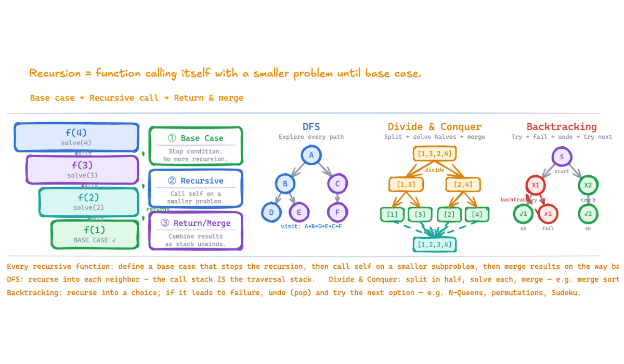>

In [ ]:
"""
Pattern 46 — Recursion Template

Demonstrates the three core recursion patterns with executable examples.
"""

print("=" * 70)
print("PATTERN A: LINEAR RECURSION (Single Path)")
print("=" * 70)

def countdown(n):
    """
    Base case: n == 0 → stop
    Recursive case: print n, then recurse on n-1
    """
    if n == 0:  # BASE CASE
        return
    print(n, end=" ")
    countdown(n - 1)  # RECURSIVE CALL on smaller input

print("\nCountdown from 5:")
countdown(5)
print("\n")

# Example 2: Sum of first n integers
def sum_to_n(n):
    """
    Base case: n == 0 → return 0
    Recursive case: return n + sum_to_n(n-1)
    
    Trace for sum_to_n(3):
      sum_to_n(3) = 3 + sum_to_n(2)
      sum_to_n(2) = 2 + sum_to_n(1)
      sum_to_n(1) = 1 + sum_to_n(0)
      sum_to_n(0) = 0  ← BASE CASE
      ✓ Unwind: 0, then 1+0=1, then 2+1=3, then 3+3=6
    """
    if n == 0:  # BASE CASE
        return 0
    return n + sum_to_n(n - 1)  # RECURSIVE CALL + COMBINE

result = sum_to_n(5)
print(f"Sum of integers 1 to 5: {result}")
print(f"Expected: 15 (1+2+3+4+5)")
print(f"Match: {result == 15} ✓\n")

print("=" * 70)
print("PATTERN B: TREE RECURSION (Left & Right Sub-problems)")
print("=" * 70)

# Simple tree node
class TreeNode:
    def __init__(self, val, left=None, right=None):
        self.val = val
        self.left = left
        self.right = right

def max_depth(node):
    """
    Base case: node is None → depth is 0
    Recursive case: depth = 1 + max(depth of left subtree, depth of right subtree)
    
    Example tree:
          1
         / \
        2   3
       /
      4
    
    max_depth(1):
      left = max_depth(2) = 1 + max(max_depth(4), max_depth(None))
                          = 1 + max(1 + max(max_depth(None), max_depth(None)), 0)
                          = 1 + max(1 + 0, 0) = 2
      right = max_depth(3) = 1 + max(0, 0) = 1
      return 1 + max(2, 1) = 3
    """
    if not node:  # BASE CASE
        return 0
    left_depth = max_depth(node.left)  # RECURSIVE CALL
    right_depth = max_depth(node.right)  # RECURSIVE CALL
    return 1 + max(left_depth, right_depth)  # COMBINE

# Build example tree
#      1
#     / \
#    2   3
#   /
#  4
root = TreeNode(1)
root.left = TreeNode(2)
root.right = TreeNode(3)
root.left.left = TreeNode(4)

depth = max_depth(root)
print(f"Max depth of tree: {depth}")
print(f"Expected: 3 (path 1→2→4)")
print(f"Match: {depth == 3} ✓\n")

# Example 2: Sum all node values
def sum_tree(node):
    """
    Base case: node is None → sum is 0
    Recursive case: node.val + sum(left subtree) + sum(right subtree)
    """
    if not node:  # BASE CASE
        return 0
    return node.val + sum_tree(node.left) + sum_tree(node.right)  # COMBINE

total = sum_tree(root)
print(f"Sum of all node values (1+2+3+4): {total}")
print(f"Expected: 10")
print(f"Match: {total == 10} ✓\n")

print("=" * 70)
print("PATTERN C: BACKTRACKING (Explore All Choices)")
print("=" * 70)

def generate_permutations(arr):
    """
    Base case: index == len(arr) → found a complete permutation
    Recursive case: for each available element, choose it, recurse, then undo (backtrack)
    
    This explores the entire decision tree:
                 []
            /    |    \
          [1]  [2]   [3]
         /  \  /  \  /  \
        ...arrangements...
    """
    result = []
    
    def backtrack(path):
        if len(path) == len(arr):  # BASE CASE: found a complete permutation
            result.append(path[:])  # Add a copy
            return
        
        for i in range(len(arr)):
            if arr[i] not in path:  # Only use available elements
                path.append(arr[i])  # CHOICE
                backtrack(path)  # EXPLORE (RECURSIVE CALL)
                path.pop()  # UNDO (BACKTRACK)
    
    backtrack([])
    return result

perms = generate_permutations([1, 2, 3])
print(f"Permutations of [1, 2, 3]:")
for p in perms:
    print(f"  {p}")
print(f"Total permutations: {len(perms)}")
print(f"Expected: 6 (3! = 6)")
print(f"Match: {len(perms) == 6} ✓\n")

# Example 2: All subsets (Power Set)
def generate_subsets(arr):
    """
    For each element, we have two choices: include it or exclude it.
    This creates a binary tree of 2^n possibilities.
    """
    result = []
    
    def backtrack(index, path):
        if index == len(arr):  # BASE CASE
            result.append(path[:])
            return
        
        # Choice 1: Include arr[index]
        path.append(arr[index])
        backtrack(index + 1, path)  # EXPLORE
        path.pop()  # BACKTRACK
        
        # Choice 2: Exclude arr[index]
        backtrack(index + 1, path)  # EXPLORE
    
    backtrack(0, [])
    return result

subsets = generate_subsets([1, 2, 3])
print(f"All subsets of [1, 2, 3]:")
for s in sorted(subsets):
    print(f"  {s}")
print(f"Total subsets: {len(subsets)}")
print(f"Expected: 8 (2^3 = 8)")
print(f"Match: {len(subsets) == 8} ✓\n")

print("=" * 70)
print("KEY TAKEAWAYS")
print("=" * 70)
print("✓ Pattern A (Linear): One recursive call → processes sequences")
print("✓ Pattern B (Tree):   Multiple recursive calls → processes trees/graphs")
print("✓ Pattern C (Backtrack): Explore all branches, undo choices → search")
print("✓ Always define base case FIRST to prevent infinite recursion")
print("✓ Trust that solve(n-1) works; you only define solve(n)")
print("✓ Consider memoization if you solve the same sub-problem twice (DP)")
print("=" * 70)

## Pattern 47 — Memoization (Top-Down DP)

**Importance:** ★★★★★

### Story
Imagine you're calculating family trees for a genealogy project. To find a person's nth ancestor, you recursively ask: "Who were your parents?" Then you ask their parents the same question. Without notes, you'd ask the same people the same question over and over — wasting time on redundant detective work.

The smart move: **Before asking, check your memo pad.** "Wait, did I already find John Smith's parents? Let me check my notes first." If the answer is there, write it down instantly. If not, investigate once, then **scribble the answer in your memo pad for next time**. This is memoization: a memo (dictionary) storing expensive computation results so redundant calls return instantly.

Memoization **transforms exponential recursion into polynomial time** by ensuring each unique sub-problem is solved exactly once. Classic example: without memoization, `fib(50)` requires ~10^15 recursive calls; with memoization, just 50 calls total.

### When to Use
*   **Fibonacci, Catalan numbers**: Exponential recursion due to overlapping sub-problems
*   **DFS/Backtracking with repeated states**: Graph paths, coin change, climbing stairs
*   **Top-down DP**: When problem naturally breaks into overlapping sub-problems
*   **When sub-problem space is sparse**: Only solve states you actually visit
*   **As an alternative to bottom-up DP**: More intuitive, less loop-bookkeeping

### Core Idea
```
memo = {}  # Dictionary to cache results

function solve(state):
    if state in memo:
        return memo[state]  # Hit! Return cached result instantly
    
    if base_case(state):
        result = base_answer
    else:
        result = compute using recursive calls on smaller states
    
    memo[state] = result  # Store for future calls
    return result
```

**Three-step pattern:**
1. Check memo first (return if found)
2. Compute recursively (solving sub-problems)
3. Store in memo before returning

### Pitfalls
*   **Forgetting to return memo[state]**: Check memo but don't return cached result → still recompute
*   **Not caching all results**: Compute the answer but forget `memo[state] = result` → redundant work returns
*   **Using mutable objects as keys**: Lists/dicts can't be dict keys in Python; convert to immutable (tuple, frozenset) or use a different key scheme
*   **Stack overflow on deep recursion**: Python has a default limit (~1000); for very deep trees, use bottom-up DP or increase `sys.setrecursionlimit()`
*   **Memory abuse**: Memoization trades time for space; very large state spaces can use lots of memory

### Memoization vs. Bottom-Up DP
| Aspect | Memoization (Top-Down) | Tabulation (Bottom-Up) |
|--------|------------------------|----------------------|
| Order | Solve needed states | Build all states systematically |
| Intuition | Recursive, natural problem structure | Iterative, fill table forward |
| Sub-problems | Only compute what's needed (sparse) | Compute all sub-problems |
| Space | Less if sparse; risk of deep recursion | Fixed, predictable |
| Implementation | Cache decorator or manual dict | Nested loops, build table |

### Mini Examples

**Example 1: Fibonacci without memoization**
```
fib(5) calls:
  fib(5) → fib(4) + fib(3)
    fib(4) → fib(3) + fib(2)
      fib(3) → fib(2) + fib(1)
        fib(2) → fib(1) + fib(0)
        (fib(2) computed MULTIPLE times!)
  
Calls to fib(2): 3 times  ⟹ WASTEFUL
Time: O(2^n)
```

**Example 2: Fibonacci WITH memoization**
```
memo = {}
fib(5):
  fib(5) → fib(4) + fib(3)
    fib(4) → fib(3) + fib(2)
      fib(3) is computed once, stored in memo
      fib(2) is computed once, stored in memo
    Later fib(3) call? Check memo → instant!
    Later fib(2) call? Check memo → instant!

Total calls: 5 (one per unique state)
Time: O(n) ⟹ FAST!
```

![][image1]

[image1]: <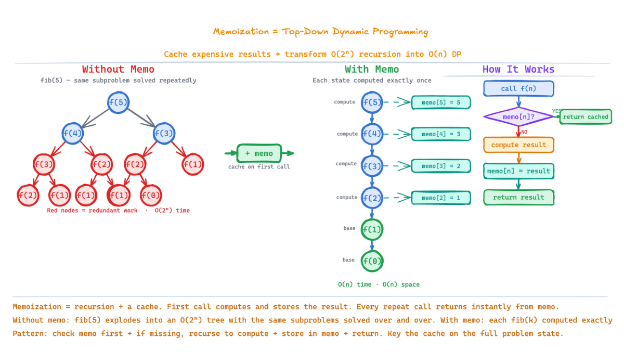>

In [ ]:
"""
Pattern 47 — Memoization (Top-Down DP)

Demonstrates three classic memoization examples with performance comparisons.
"""

import time
import sys

print("=" * 70)
print("EXAMPLE 1: FIBONACCI WITHOUT vs. WITH MEMOIZATION")
print("=" * 70)

# ===== WITHOUT MEMOIZATION (Exponential) =====
def fib_naive(n):
    """
    Pure recursion without memoization.
    Time: O(2^n) — each call branches into 2 more calls
    
    Call tree for fib(5):
        fib(5)
        ├── fib(4)
        │   ├── fib(3)
        │   │   ├── fib(2)  ← computed AGAIN!
        │   │   └── fib(1)
        │   └── fib(2)      ← computed AGAIN!
        └── fib(3)          ← computed AGAIN!
    """
    if n <= 1:
        return n
    return fib_naive(n - 1) + fib_naive(n - 2)

# ===== WITH MEMOIZATION (Linear) =====
def fib_memo(n, memo=None):
    """
    Memoized recursion: cache results in memo dict.
    Time: O(n) — each state computed once
    
    Algorithm:
    1. Check if n in memo → return cached result
    2. Compute fib_memo(n-1) + fib_memo(n-2)
    3. Store result in memo[n] before returning
    """
    if memo is None:
           memo = {}
       
    if n <= 1:
        return 1 
    
    if n in memo:
        return memo[n]
    
    result = fib_memo(n - 1, memo) + fib_memo(n - 2, memo)  # STEP 2: Compute
    
    memo[n] = result  # STEP 3: Cache before returning
    return result

# Benchmark
print("\nPerformance Comparison:")
print(f"  n=30:")

start = time.time()
result_naive = fib_naive(30)
time_naive = time.time() - start

start = time.time()
result_memo = fib_memo(30)
time_memo = time.time() - start

print(f"    Without memoization: {result_naive:,} (took {time_naive:.3f}s)")
print(f"    With memoization:    {result_memo:,} (took {time_memo:.6f}s)")
print(f"    Speedup: {time_naive / time_memo:.0f}x faster! ✓")

print(f"\n  fib(30) = {result_memo:,}")
print(f"    Expected: 832,040")
print(f"    Match: {result_memo == 832040} ✓")

print("\n" + "=" * 70)
print("EXAMPLE 2: COIN CHANGE (Minimum Coins)")
print("=" * 70)

def min_coins(amount, coins, memo=None):
    """
    Find minimum number of coins needed to make an amount.
    
    Recursive idea:
    - For each coin ≤ amount, try using that coin
    - Then solve for (amount - coin)
    - Pick the choice requiring fewest coins
    
    Without memoization: same sub-problems solved repeatedly
    E.g., min_coins(5, [1,2,5]) explores many overlapping branches
    
    With memoization: store min_coins[amount] so future calls are instant.
    """
    if memo is None:
        memo = {}
    
    if amount == 0:
        return 0  # Base case
    
    if amount in memo:  # STEP 1: Check cache
        return memo[amount]
    
    # Try all coins, pick the best
    min_count = float('inf')
    for coin in coins:
        if coin <= amount:
            remaining = amount - coin
            count = 1 + min_coins(remaining, coins, memo)  # Recursive call
            min_count = min(min_count, count)
    
    memo[amount] = min_count  # STEP 3: Cache before returning
    return min_count

# Test cases
print("\nProblem: Make amount with minimum coins from available denominations")
test_cases = [
    (11, [1, 2, 5]),
    (5, [5]),
    (3, [2]),  # Impossible case
    (10, [1, 5, 10])
]

for amount, coins in test_cases:
    result = min_coins(amount, coins)
    print(f"  Amount={amount}, Coins={coins}")
    print(f"    Min coins needed: {result if result != float('inf') else 'Impossible'}")

print("\n  Example trace for min_coins(5, [1,2,5]):")
print("    min_coins(5)")
print("    ├─ coin=1: 1 + min_coins(4)")
print("    │   └─ min_coins(4) cached after first call")
print("    ├─ coin=2: 1 + min_coins(3)")
print("    │   └─ min_coins(3) cached after first call")
print("    └─ coin=5: 1 + min_coins(0) = 1 + 0 = 1 ✓ (BEST)")
print("    Result: 1 coin (the 5-cent piece)")

print("\n" + "=" * 70)
print("EXAMPLE 3: CLIMBING STAIRS (Ways to Reach Top)")
print("=" * 70)

def climb_stairs(n, memo=None):
    """
    You can climb 1 or 2 stairs at a time.
    How many distinct ways to reach the nth stair?
    
    Recursive relation:
    - To reach stair n, you either:
      1. Came from stair (n-1) and climbed 1 step
      2. Came from stair (n-2) and climbed 2 steps
    - Total ways = ways(n-1) + ways(n-2)
    
    This is essentially Fibonacci! Without memoization: exponential.
    With memoization: linear.
    """
    if memo is None:
        memo = {}
    
    if n <= 1:
        return 1  # Base: 1 stair or 0 stairs → 1 way
    
    if n in memo:  # STEP 1: Check cache
        return memo[n]
    
    # STEP 2: Compute (recursive calls)
    result = climb_stairs(n - 1, memo) + climb_stairs(n - 2, memo)
    
    # STEP 3: Cache
    memo[n] = result
    return result

print("\nProblem: Climb n stairs (1 or 2 steps per move). How many ways?")
print("  Examples:")
for n in range(1, 8):
    ways = climb_stairs(n)
    print(f"    n={n}: {ways} ways")

print("\n  Visual for n=3:")
print("    Path 1: 1-step, 1-step, 1-step")
print("    Path 2: 1-step, 2-step")
print("    Path 3: 2-step, 1-step")
print("    Total: 3 ways ✓")

print("\n  Relation to Fibonacci:")
print("    climb_stairs(n) = Fibonacci(n+1)")
print("    climb_stairs(5) = fib(6) = 8 ✓")
print(f"    Verified: {climb_stairs(5) == 8}")

print("\n" + "=" * 70)
print("KEY PATTERNS & TAKEAWAYS")
print("=" * 70)
print("✓ Memoization transforms O(2^n) → O(n) for Fibonacci & similar problems")
print("✓ Use memo dict with state as key; check before computing")
print("✓ Don't forget: memo[state] = result before returning!")
print("✓ Works best when: many overlapping sub-problems exist")
print("✓ Works poorly when: all sub-problems are unique (no reuse)")
print("✓ Space-time tradeoff: remember results, use more memory")
print("=" * 70)

## Pattern 48 — String Parsing / Simulation

**Importance:** ★★★★★

### Story
Imagine you're a computer executing a program line by line. You don't skip ahead and guess what the result will be—you follow the exact instructions given. You read character by character, tracking state (a stack, a pointer, a counter, a dictionary). When you see a number, you build it up. When you see an operator, you apply it. When you see a bracket, you push context onto your stack or pop it off. You simulate the exact process described in the problem.

This is the parsing & simulation pattern: **Do exactly what the problem says, character by character, tracking your state as you go.** There's no mathematical formula or clever algorithm—just faithful execution. The problem often *reads like instructions* ("evaluate this expression", "decode this string", "process these operations").

Classic examples:
- **Evaluate expression**: `"2 + 3 * 4"` → you parse numbers and operators, respect order of operations, return result
- **Decode string**: `"3[a2[c]]"` → you parse, build structure, expand according to rules
- **Valid parentheses**: `"({[]})"` → you push open brackets, pop when you see close brackets, verify match

### When to Use
*   **Expression evaluation**: Postfix (RPN), infix with precedence, calculator apps
*   **String encoding/decoding**: Compressed strings, nested brackets, escape sequences
*   **Simulation problems**: "Process the instructions", "execute step-by-step"
*   **Validation/parsing**: Check if valid JSON, balanced parentheses, valid IP address
*   **State tracking**: Parser problems where state evolves as you read input
*   **Stack-friendly problems**: Nested structures, undo/redo, matching pairs

**Red flags for this pattern:**
- Problem says: "evaluate", "decode", "process", "execute", "simulate", "parse"
- Problem involves nested structures (brackets, parentheses, indentation)
- Problem describes a sequence of operations to apply in order
- Problem has matching pairs or depth tracking

### Core Idea
```
result = initialize_state()
i = 0
while i < len(input):
    char = input[i]
    
    if char is digit:
        number = parse_number(i)  # Build multi-digit number
        apply_operation(number, result)
        i = skip past number
    elif char is operator:
        result = apply_operator(char, result)
        i += 1
    elif char is open_bracket:
        stack.push(result)  # Save state
        result = initialize_state()
        i += 1
    elif char is close_bracket:
        result = finalize_nested(result)  # Combine with saved state
        result = stack.pop()
        i += 1
    else:
        i += 1  # Skip irrelevant chars (spaces, etc.)

return result
```

**Key tools:**
- **Stack**: Track nested contexts (parentheses, brackets, function calls)
- **Pointer/Index**: Track position in string; build multi-character tokens (numbers, words)
- **State variables**: Accumulator for current value, operator for next operation, multiplier for nesting
- **Character classification**: Is it digit? operator? bracket? space?

### Pitfalls
*   **Not building multi-character numbers**: Reading one digit instead of the whole number ("10" becomes 1 + 0)
*   **Forgetting to track order of operations**: Doing `2 + 3 * 4` left-to-right (20) instead of respecting precedence (14)
*   **Mishandling nested structures**: Not pushing/popping stack correctly for brackets
*   **Skipping edge cases**: Empty input, single character, consecutive operators, spaces/whitespace
*   **Not resetting state between nesting levels**: Variables from outer level leak into inner level
*   **Off-by-one on string indexing**: Starting at wrong position after parsing a token

### Mini Examples

**Example 1: Evaluate Simple Expression**
```
Input: "2+3*4"
Parse:
  i=0: char='2' → number=2, result=2, next_op='+'
  i=1: char='+' → next_op='+', i=2
  i=2: char='3' → apply_op('+', 2, 3) → result=5, next_op='*'
  i=3: char='*' → next_op='*', i=4
  i=4: char='4' → apply_op('*', 5, 4) → result=20 ✓

Wait! Respecting precedence: 2 + (3*4) = 14, not 20!
Need to defer addition until you see lower-precedence op.
```

**Example 2: Decode Nested String**
```
Input: "3[a2[c]]"
Parse:
  i=0: char='3' → num=3, i=1
  i=1: char='[' → stack.push((3, "")), reset for inner level, i=2
  i=2: char='a' → current="a", i=3
  i=3: char='2' → num=2, i=4
  i=4: char='[' → stack.push((2, "a")), reset, i=5
  i=5: char='c' → current="c", i=6
  i=6: char=']' → repeat 2 times: current="cc", pop (2,"a") → current="a"+"cc"*2="acc", i=7
  i=7: char=']' → repeat 3 times: current="accacc..."*3, pop (3,"") → current="accaccacc"

Result: "accaccacc" (the letter 'a' followed by "cc" repeated 2 times, all repeated 3 times)
```

**Example 3: Valid Parentheses**
```
Input: "({[]})"
Stack simulation:
  char='(': stack=[  '(' ]
  char='{': stack=['(', '{' ]
  char='[': stack=['(', '{', '[' ]
  char=']': matches '[' at top, stack=['(', '{' ]
  char='}': matches '{' at top, stack=['(' ]
  char=')': matches '(' at top, stack=[]
  Final: stack is empty → valid! ✓
```

![][image1]

[image1]: <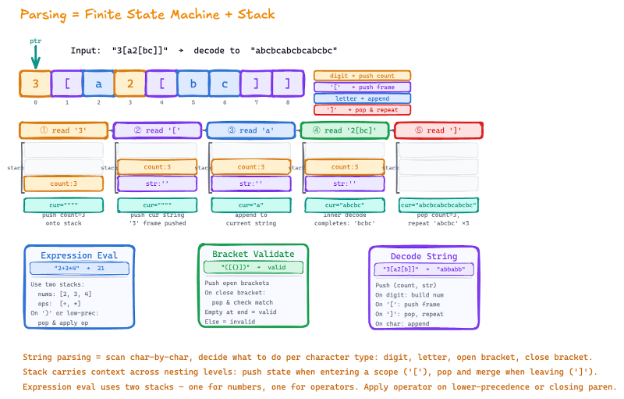>

In [ ]:
"""
Pattern 48 — String Parsing / Simulation

Demonstrates three classic parsing & simulation examples:
1. Evaluate postfix (RPN) expression
2. Decode nested string with multipliers
3. Validate balanced parentheses
"""

print("=" * 70)
print("EXAMPLE 1: EVALUATE POSTFIX EXPRESSION (RPN)")
print("=" * 70)

def eval_postfix(expression):
    """
    Evaluate Reverse Polish Notation (postfix) expression.
    In postfix: operands come before operators.
    
    Examples:
      "2 3 +" means 2 + 3 = 5
      "2 3 4 * +" means 2 + (3 * 4) = 14  (no precedence issues!)
    
    Algorithm: Use a stack
    - When you see a number: push it onto stack
    - When you see an operator: pop two operands, apply op, push result
    - Final answer: single element left on stack
    """
    stack = []
    tokens = expression.split()
    
    for token in tokens:
        if token in "+-*/%":
            # Pop two operands (note: order matters for - and /)
            b = stack.pop()  # Second operand
            a = stack.pop()  # First operand
            
            if token == '+':
                result = a + b
            elif token == '-':
                result = a - b
            elif token == '*':
                result = a * b
            elif token == '/':
                result = int(a / b)  # Integer division
            elif token == '%':
                result = a % b
            
            stack.append(result)
        else:
            # It's a number
            stack.append(int(token))
    
    return stack[0]  # Final answer is the last element

# Test cases
print("\nEvaluate postfix expressions:")
test_cases = [
    ("2 3 +", 5, "2 + 3"),
    ("2 3 4 * +", 14, "2 + (3 * 4)"),
    ("15 7 1 1 + - /", 3, "15 / (7 - (1 + 1))"),
    ("3 4 + 2 * 7 /", 2, "(3 + 4) * 2 / 7"),
]

for expr, expected, description in test_cases:
    result = eval_postfix(expr)
    print(f"  '{expr}'")
    print(f"    Means: {description}")
    print(f"    Result: {result}, Expected: {expected}, Match: {result == expected} ✓")

print("\n" + "=" * 70)
print("EXAMPLE 2: DECODE NESTED STRING WITH MULTIPLIERS")
print("=" * 70)

def decode_string(s):
    """
    Decode a string with nested bracket multipliers.
    Format: [number][string] means repeat string number times.
    
    Examples:
      "2[a]" → "aa"
      "3[ab]" → "ababab"
      "2[abc]3[cd]" → "abcabccdcdcd"
      "a2[c]" → "acc"
      "3[a2[c]]" → "accaccacc" (nested!)
    
    Algorithm: Use a stack to track nesting levels
    - When you see '[': push current state onto stack, reset for inner level
    - When you see ']': pop from stack, apply multiplier, combine with outer level
    - When you see a digit: accumulate it (could be multi-digit like 12)
    - When you see a letter: add to current string
    """
    stack = []
    current_str = ""
    current_num = 0
    
    for char in s:
        if char == '[':
            # Push current state to stack, start fresh for nested level
            stack.append((current_num, current_str))
            current_str = ""
            current_num = 0
        elif char == ']':
            # Pop state, apply multiplier
            num, prev_str = stack.pop()
            current_str = prev_str + current_str * num
        elif char.isdigit():
            # Build multi-digit number
            current_num = current_num * 10 + int(char)
        else:  # It's a letter
            current_str += char
    
    return current_str

print("\nDecode nested strings with multipliers:")
decode_tests = [
    ("2[a]", "aa"),
    ("3[ab]", "ababab"),
    ("2[abc]3[cd]", "abcabccdcdcd"),
    ("a2[c]", "acc"),
    ("3[a2[c]]", "accaccacc"),
]

for encoded, expected in decode_tests:
    result = decode_string(encoded)
    print(f"  Input:    '{encoded}'")
    print(f"  Output:   '{result}'")
    print(f"  Expected: '{expected}'")
    print(f"  Match: {result == expected} ✓")

print("\n" + "=" * 70)
print("EXAMPLE 3: VALIDATE BALANCED PARENTHESES")
print("=" * 70)

def is_valid_parentheses(s):
    """
    Check if string has valid/balanced parentheses.
    Valid: every open bracket has matching close bracket in correct order.
    
    Rules:
      - Every '(' must have matching ')'
      - Every '{' must have matching '}'
      - Every '[' must have matching ']'
      - Brackets must close in correct order (can't have "](" )
    
    Algorithm: Stack simulation
    - When you see open bracket: push to stack
    - When you see close bracket: check if top of stack matches, pop if yes, fail if no
    - At end: stack must be empty
    """
    stack = []
    matching = {'(': ')', '{': '}', '[': ']'}
    
    for char in s:
        if char in matching:  # It's an opening bracket
            stack.append(char)
        elif char in matching.values():  # It's a closing bracket
            if not stack:  # No opening bracket to match
                return False
            if matching[stack[-1]] == char:  # Matches top of stack
                stack.pop()
            else:  # Doesn't match
                return False
    
    return len(stack) == 0  # Valid if stack is empty (all matched)

print("\nValidate balanced parentheses:")
paren_tests = [
    ("()", True),
    ("()[]{}", True),
    ("([{}])", True),
    ("(]", False),
    ("([)]", False),  # Wrong order
    ("{[]}", True),
    ("", True),  # Empty is valid
]

for s, expected in paren_tests:
    result = is_valid_parentheses(s)
    status = "✓" if result == expected else "✗"
    print(f"  '{s:10}' → {str(result):5} (expected {expected:5}) {status}")

print("\n" + "=" * 70)
print("KEY TAKEAWAYS")
print("=" * 70)
print("✓ Parsing Pattern: Character-by-character simulation of problem logic")
print("✓ Stack is your friend: Track nesting, state, or matching pairs")
print("✓ Multi-character tokens: Build numbers/words from individual chars")
print("✓ State variables: Track what you're building (current_str, current_num)")
print("✓ Respect the exact problem description: Don't optimize prematurely")
print("=" * 70)

## Pattern 49 — Graph Cycle Detection (Directed vs Undirected)

**Importance:** ★★★★★

### Story
Imagine you're checking if courses have circular prerequisites. Course A requires B, B requires C, C requires A—deadlock! Or imagine a road network: you want to know if there's a loop where you can drive in circles. The problem: **cycles look and behave differently depending on the graph type**.

In a **directed graph** (one-way streets), a cycle is a path that starts at a node and comes back to itself by following arrows. Think of following breadcrumbs: if you revisit a breadcrumb that's currently in your hand (on your recursion stack), you found a cycle.

In an **undirected graph** (two-way streets), any edge can go both ways. So if you visit a neighbor and immediately backtrack to where you came from, that's not a cycle—that's just a two-node path. A real cycle is when you reach a neighbor through a *different* path. Hence the key: **track where you came from and ignore the backtrack**.

The genius: **use different tools for different graph types**. Directed: recursion stack. Undirected: parent tracking. Same problem, two solutions.

### When to Use
*   **Course prerequisite checking**: Detect circular dependencies in task scheduling
*   **Deadlock detection**: Check for circular dependencies in resource allocation
*   **Topological sort validation**: Verify graph is acyclic before sorting
*   **Social network analysis**: Find tightly-knit cliques or circular relationships
*   **Code dependency analysis**: Detect circular imports or function call loops
*   **Redundant edge detection**: Identify extra edges that create cycles in tree-like structures
*   **Problem statement clues**: "cycle", "circular", "loop", "prerequisite", "dependency"

**Red flags for this pattern:**
- Problem asks: "detect cycle", "has loop", "circular dependency", "valid topological sort"
- Problem mentions "directed" vs "undirected" explicitly
- Need to distinguish between valid edges (tree) and problematic edges (cycle-forming)

### Core Idea
```
For DIRECTED graphs (use DFS + recursion stack):
visited = {}
rec_stack = {}  # Tracks nodes currently in recursion path

def has_cycle(node):
    visited[node] = True
    rec_stack[node] = True  # Mark as in-progress
    
    for neighbor in graph[node]:
        if not visited[neighbor]:
            if has_cycle(neighbor):
                return True
        elif rec_stack[neighbor]:  # ← KEY: visited but still in progress
            return True  # Found a back edge → cycle!
    
    rec_stack[node] = False  # Mark as finished, remove from stack
    return False

For UNDIRECTED graphs (use DFS + parent tracking):
visited = {}

def has_cycle(node, parent):
    visited[node] = True
    
    for neighbor in graph[node]:
        if not visited[neighbor]:
            if has_cycle(neighbor, node):  # Pass current node as parent
                return True
        elif neighbor != parent:  # ← KEY: visited AND not the parent we came from
            return True  # Found a cross/forward edge → cycle!
    
    return False
```

**Key differences:**
- **Directed**: Recursion stack tracks "are we still exploring this node?" — back edges (to node in stack) indicate cycles
- **Undirected**: Parent tracking prevents false positives from immediate backtracking
- **Complexity**: Both O(V + E) with DFS, but different termination conditions

### Pitfalls
*   **Using undirected logic on directed graph**: Ignoring the direction of edges; missing cycles because you're treating arrows as two-way
*   **Forgetting to mark "finished" state in directed graphs**: Not removing from recursion stack means you incorrectly detect forward/cross edges as cycles
*   **Using "visited only" for directed graphs**: Missing cycles because visited[node] alone doesn't distinguish between "currently exploring" and "finished exploring"
*   **Comparing neighbor == parent in directed graphs**: Parent tracking is only valid for undirected graphs; in directed, a node can be visited from many sources
*   **Handling self-loops**: Not checking if node has edge to itself before recursion (especially in directed)
*   **Disconnected components**: Only checking from one starting node; need to iterate over all unvisited nodes in case graph has multiple components

### Mini Examples

**Example 1: Directed Graph Cycle**
```
Graph: 1→2, 2→3, 3→1 (cycle: 1→2→3→1)

DFS from 1:
  Visit 1: visited[1]=True, rec_stack[1]=True
    Visit 2: visited[2]=True, rec_stack[2]=True
      Visit 3: visited[3]=True, rec_stack[3]=True
        Check neighbor 1: visited[1]=True AND rec_stack[1]=True
        → CYCLE FOUND! ✓
        
The key: rec_stack[1] is still True (we haven't returned from 1's recursion yet)
```

**Example 2: Directed Graph No Cycle**
```
Graph: 1→2, 2→3, 3→4 (linear, no cycle)

DFS from 1:
  Visit 1: visited[1]=True, rec_stack[1]=True
    Visit 2: visited[2]=True, rec_stack[2]=True
      Visit 3: visited[3]=True, rec_stack[3]=True
        Visit 4: visited[4]=True, rec_stack[4]=True
          No neighbors
        rec_stack[4]=False, return False
      rec_stack[3]=False, return False
    rec_stack[2]=False, return False
  rec_stack[1]=False, return False
→ NO CYCLE ✓
```

**Example 3: Undirected Graph Cycle**
```
Graph: 1-2-3, 2-4 (cycle: 1-2-3-2... NO! Actually no cycle in undirected)
Real cycle example: 1-2, 2-3, 3-1

DFS from 1 (parent=None):
  Visit 1
    Neighbor 2: not visited, explore(2, parent=1)
      Visit 2
        Neighbor 1: visited but is parent → skip
        Neighbor 3: not visited, explore(3, parent=2)
          Visit 3
            Neighbor 1: visited and ≠ parent(2)
            → CYCLE FOUND! ✓
```

**Example 4: Undirected Graph No Cycle (Tree)**
```
Graph: 1-2, 2-3, 2-4 (tree structure)

DFS from 1 (parent=None):
  Visit 1
    Neighbor 2: not visited, explore(2, parent=1)
      Visit 2
        Neighbor 1: visited but is parent → skip
        Neighbor 3: not visited, explore(3, parent=2)
          Visit 3: no unvisited neighbors
          return False
        Neighbor 4: not visited, explore(4, parent=2)
          Visit 4: no unvisited neighbors
          return False
      return False
  return False
→ NO CYCLE ✓ (This is a valid tree)
```

![][image1]

[image1]: <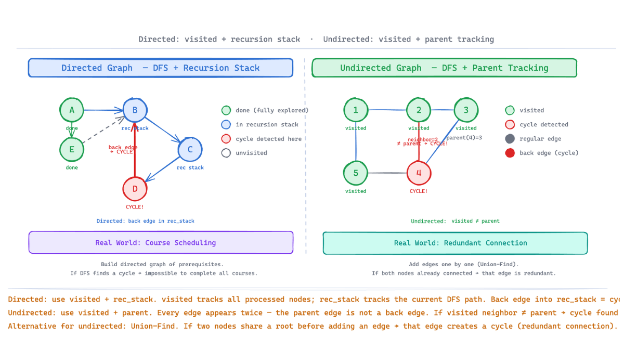>

In [ ]:
"""
Pattern 49 — Graph Cycle Detection (Directed vs Undirected)

Demonstrates detecting cycles in:
1. Directed graphs (prerequisites, dependencies)
2. Undirected graphs (social networks, road networks)
"""

print("=" * 70)
print("EXAMPLE 1: DIRECTED GRAPH CYCLE DETECTION")
print("=" * 70)

def has_cycle_directed(graph, num_nodes):
    """
    Detect cycle in a directed graph using DFS + recursion stack.
    
    Key insight: A cycle exists if we encounter a node that's currently
    in our recursion stack (not yet finished exploring).
    
    Args:
        graph: dict {node: [neighbors]}
        num_nodes: number of nodes (0 to num_nodes-1)
    
    Returns: True if cycle exists, False otherwise
    """
    visited = [False] * num_nodes
    rec_stack = [False] * num_nodes  # Tracks nodes in current recursion path
    
    def dfs(node):
        visited[node] = True
        rec_stack[node] = True  # Mark as "in progress"
        
        for neighbor in graph.get(node, []):
            if not visited[neighbor]:
                if dfs(neighbor):
                    return True
            elif rec_stack[neighbor]:  # ← CYCLE: visited node still in recursion
                return True
        
        rec_stack[node] = False  # Mark as "finished"
        return False
    
    # Check all nodes (graph might be disconnected)
    for node in range(num_nodes):
        if not visited[node]:
            if dfs(node):
                return True
    
    return False

print("\nTest Directed Graphs:")
directed_tests = [
    # (name, graph, num_nodes, expected_has_cycle)
    ("Linear: 0→1→2→3", {0: [1], 1: [2], 2: [3]}, 4, False),
    ("Cycle: 0→1→2→0", {0: [1], 1: [2], 2: [0]}, 3, True),
    ("Fork: 0→[1,2], 1→3, 2→3", {0: [1, 2], 1: [3], 2: [3]}, 4, False),
    ("Self-loop: 0→0", {0: [0]}, 1, True),
    ("Complex cycle: 0→1→2, 0→2→3→1", {0: [1, 2], 1: [2], 2: [3], 3: [1]}, 4, True),
]

for name, graph, nodes, expected in directed_tests:
    result = has_cycle_directed(graph, nodes)
    status = "✓" if result == expected else "✗"
    print(f"  {name:35} → Cycle: {result:5}, Expected: {expected:5} {status}")

print("\n" + "=" * 70)
print("EXAMPLE 2: UNDIRECTED GRAPH CYCLE DETECTION")
print("=" * 70)

def has_cycle_undirected(graph, num_nodes):
    """
    Detect cycle in an undirected graph using DFS + parent tracking.
    
    Key insight: A cycle exists if we encounter a visited neighbor
    that's NOT the parent we came from (indicates alternative path).
    
    Args:
        graph: dict {node: [neighbors]}
        num_nodes: number of nodes (0 to num_nodes-1)
    
    Returns: True if cycle exists, False otherwise
    """
    visited = [False] * num_nodes
    
    def dfs(node, parent):
        visited[node] = True
        
        for neighbor in graph.get(node, []):
            if not visited[neighbor]:
                if dfs(neighbor, node):  # Pass current node as parent
                    return True
            elif neighbor != parent:  # ← CYCLE: visited and not from where we came
                return True
        
        return False
    
    # Check all nodes (graph might be disconnected)
    for node in range(num_nodes):
        if not visited[node]:
            if dfs(node, -1):  # -1 as sentinel for "no parent"
                return True
    
    return False

print("\nTest Undirected Graphs:")
undirected_tests = [
    # (name, graph, num_nodes, expected_has_cycle)
    ("Linear: 0-1-2-3", {0: [1], 1: [0, 2], 2: [1, 3], 3: [2]}, 4, False),
    ("Cycle: 0-1-2-0", {0: [1, 2], 1: [0, 2], 2: [1, 0]}, 3, True),
    ("Tree: 0-[1,2], 1-3, 2-3", {0: [1, 2], 1: [0, 3], 2: [0, 3], 3: [1, 2]}, 4, True),  # Star with extra edge
    ("Simple tree: 0-1, 0-2", {0: [1, 2], 1: [0], 2: [0]}, 3, False),
    ("Diamond: 0-[1,2], 1-3, 2-3", {0: [1, 2], 1: [0, 3], 2: [0, 3], 3: [1, 2]}, 4, True),
]

for name, graph, nodes, expected in undirected_tests:
    result = has_cycle_undirected(graph, nodes)
    status = "✓" if result == expected else "✗"
    print(f"  {name:40} → Cycle: {result:5}, Expected: {expected:5} {status}")

print("\n" + "=" * 70)
print("EXAMPLE 3: COURSE PREREQUISITE VALIDATION (Directed Graph)")
print("=" * 70)

def can_finish_courses(num_courses, prerequisites):
    """
    Check if all courses can be finished given prerequisites.
    prerequisites: list of [course, prerequisite] pairs
    
    Returns: True if no circular dependency, False if cycle exists
    """
    # Build directed graph
    graph = {i: [] for i in range(num_courses)}
    for course, prereq in prerequisites:
        graph[course].append(prereq)
    
    # Check for cycles
    return not has_cycle_directed(graph, num_courses)

print("\nCourse prerequisites (can finish = no cycle):")
course_tests = [
    # (name, num_courses, prerequisites, expected_can_finish)
    ("No prereqs: courses 0,1,2", 3, [], True),
    ("Linear: 1←0, 2←1", 3, [[1, 0], [2, 1]], True),
    ("Cycle: 0←1←2←0", 3, [[0, 1], [1, 2], [2, 0]], False),
    ("Diamond: 2←[0,1], 3←2", 4, [[2, 0], [2, 1], [3, 2]], True),
]

for name, num_courses, prereqs, expected in course_tests:
    result = can_finish_courses(num_courses, prereqs)
    status = "✓" if result == expected else "✗"
    print(f"  {name:30} → Can finish: {result:5}, Expected: {expected:5} {status}")

print("\n" + "=" * 70)
print("EXAMPLE 4: FRIENDSHIP NETWORK (Undirected Graph)")
print("=" * 70)

def count_connected_components(graph, num_people):
    """
    Count connected components in friendship graph (undirected).
    Each component is a group of mutually connected friends.
    """
    visited = [False] * num_people
    components = 0
    
    def dfs(person):
        visited[person] = True
        for friend in graph.get(person, []):
            if not visited[friend]:
                dfs(friend)
    
    for person in range(num_people):
        if not visited[person]:
            dfs(person)
            components += 1
    
    return components

print("\nFriendship networks (count separate friend groups):")
friendship_tests = [
    # (name, graph, num_people, expected_components)
    ("Everyone isolated", {}, 4, 4),
    ("All connected: 0-1-2-3 chain", {0: [1], 1: [0, 2], 2: [1, 3], 3: [2]}, 4, 1),
    ("Two groups: [0-1] and [2-3]", {0: [1], 1: [0], 2: [3], 3: [2]}, 4, 2),
]

for name, graph, num_people, expected in friendship_tests:
    result = count_connected_components(graph, num_people)
    status = "✓" if result == expected else "✗"
    print(f"  {name:35} → Groups: {result}, Expected: {expected} {status}")

print("\n" + "=" * 70)
print("KEY TAKEAWAYS")
print("=" * 70)
print("✓ Directed graphs: Use recursion stack to detect back edges")
print("✓ Undirected graphs: Use parent tracking to ignore backtracking")
print("✓ Both use DFS, but termination conditions differ")
print("✓ Check all nodes: graphs may have disconnected components")
print("✓ Common use: course prerequisites, dependency analysis, network topology")
print("=" * 70)

## Pattern 50 — State Compression DP (Bitmask DP)

**Importance:** ★★★★

### Story
Imagine you're organizing a party with 10 guests. You want to know which configurations work: guest 1 + guest 3 + guest 5, or guest 2 + guest 4 + guest 6, etc. You could create arrays for each configuration—but that's $2^{10} = 1024$ arrays! 

Instead, use a **single integer as a bitmask**. Bit 0 = "is guest 1 invited?" (0 or 1), bit 1 = "is guest 2 invited?", etc. Now each subset is just one number: `0b0101010101` represents guests 1, 3, 5, 7, 9. You've compressed a "who's-invited" array into 10 bits of a single integer.

This is **state compression**: **When the problem space is small (n ≤ 15–20) but the number of state combinations explodes ($2^n$), encode the state as bits and use DP to avoid recomputation.**

Classic examples:
- **Traveling Salesman**: Visit all cities exactly once, return to start. Instead of storing "which cities visited?" as an array, use a bitmask where bit i = city i visited.
- **Assignment Problem**: Assign n people to n tasks. Bitmask represents "which people assigned so far?"
- **Subset DP**: Problems needing "all subsets of items"—compress each subset to one number.

### When to Use
*   **Small but explosive state space**: n ≤ 15–20 and all $2^n$ subsets matter
*   **Traveling Salesman Problem (TSP)**: Visit all cities once; need DP[mask][current_city]
*   **Assignment/matching problems**: Assign all items in all possible ways
*   **Subset selection with state**: "For each way to choose k items, compute X"
*   **Hamiltonian path/cycle detection**: Visit all nodes exactly once
*   **Bitmask enumeration problems**: Any problem asking "for every subset, compute..."
*   **Problem clues**: "n ≤ 15", "all subsets", "exactly once", "traveling", "assignment"

**Red flags for this pattern:**
- Problem says n is small (≤ 15) but asks about all combinations
- Problem mentions "bitmask", "subset", "TSP", "assignment", "all states"
- Brute force would be $O(2^n \cdot n!)$ or similar—need DP to reduce

### Core Idea
```
Bitmask basics:
- Represent a set of n items as a binary number
- Bit i (0-indexed) = 1 means item i is "included" or "visited"
- Bit i = 0 means item i is "not included"

Example: n=4 items (indices 0,1,2,3)
  0b0000 = {} (no items)
  0b0101 = {0, 2} (items 0 and 2)
  0b1111 = {0, 1, 2, 3} (all items)

Key bit operations:
  (1 << i) = Create a mask with only bit i set
  mask & (1 << i) = Check if bit i is set (non-zero ≠ 0 means yes)
  mask |= (1 << i) = Add item i to mask
  mask ^= (1 << i) = Toggle bit i
  popcount(mask) = Count how many bits are set (how many items)
  mask & (mask - 1) = Remove the lowest set bit

DP pattern:
dp[mask][last] = Best value to visit all items in 'mask' and end at 'last'

def solve(n):
    dp = [{} for _ in range(1 << n)]
    
    # Base case: single item
    for i in range(n):
        mask = 1 << i
        dp[mask][i] = cost[i]
    
    # Iterate through all masks in increasing order
    for mask in range(1, 1 << n):
        for last in range(n):
            if not (mask & (1 << last)):  # last not in mask
                continue
            if dp[mask][last] is None:
                continue
            
            # Try adding next item
            for next_item in range(n):
                if mask & (1 << next_item):  # already in mask
                    continue
                new_mask = mask | (1 << next_item)
                dp[new_mask][next_item] = min(
                    dp[new_mask][next_item],
                    dp[mask][last] + cost(last → next_item)
                )
    
    # Answer: all items visited, any ending position
    full_mask = (1 << n) - 1
    return min(dp[full_mask][i] for i in range(n))
```

**Why it works:**
- Small n (≤ 20) means $2^n$ is manageable (~ 1 million to 1 billion)
- Bitmask naturally encodes "which subset of items?"
- DP avoids recomputing the same state twice
- Time: $O(2^n \cdot n^2)$ — exponential but much better than $O(n! \cdot n)$ brute force

### Pitfalls
*   **Bit indexing confusion**: Forgetting that bit 0 = item 0, bit i = item i (some count from 1)
*   **Wrong bit operations**: Using + instead of | to add to mask; using >> incorrectly
*   **Not handling base cases**: Forgetting initialization for single-item masks before iterating
*   **Off-by-one in mask range**: Writing `range(1 << n)` is correct; `range((1 << n) - 1)` misses the full mask
*   **Memory explosion**: Forgetting that $2^{20} \cdot 20 \cdot 8$ bytes ≈ 200 MB; $2^{23}$ crashes
*   **Incorrect final answer retrieval**: Forgetting to iterate over all ending positions when combining results

### Mini Examples

**Example 1: Simple Bitmask Operations**
```
n = 3 (items: 0, 1, 2)

mask = 0b010 = 2 (only item 1)
Check if item 1 in mask: (mask & (1 << 1)) = (2 & 2) = 2 ✓ (non-zero = yes)
Check if item 0 in mask: (mask & (1 << 0)) = (2 & 1) = 0 ✗ (no)

Add item 2: mask |= (1 << 2) → mask = 0b110 = 6 (items 1, 2)

Count items: popcount(6) = 2 ✓
```

**Example 2: Traveling Salesman (small n)**
```
Cities: 0, 1, 2
Distances: 
  0→1: 10, 0→2: 15
  1→0: 10, 1→2: 20
  2→0: 15, 2→1: 20

Start at city 0, visit all, return to 0.

Path 0→1→2→0: 10 + 20 + 15 = 45
Path 0→2→1→0: 15 + 20 + 10 = 45

DP states:
  dp[0b001][0] = 0 (visited city 0, end at 0, no cost)
  dp[0b010][1] = 0 (visited city 1, end at 1, no cost)
  dp[0b100][2] = 0 (visited city 2, end at 2, no cost)
  
  dp[0b011][1] = dp[0b001][0] + dist[0][1] = 0 + 10 = 10 (0→1)
  dp[0b011][0] = dp[0b010][1] + dist[1][0] = 0 + 10 = 10 (1→0)
  
  dp[0b111][0] = min(
    dp[0b110][1] + dist[1][0],
    dp[0b110][2] + dist[2][0]
  ) = min(...) = 45
```

**Example 3: Job Assignment (n people, n jobs)**
```
Person 0 can do jobs: {A, B}
Person 1 can do jobs: {B, C}
Person 2 can do jobs: {C}

Assign all people to unique jobs?

mask = 0b111 = all jobs assigned
dp[0b111][2] = Can we assign all jobs ending with person 2?
Yes: Person 0→A, Person 1→B, Person 2→C ✓

Time: O(2^n * n^2) << brute force O(n!)
```

![][image1]

[image1]: <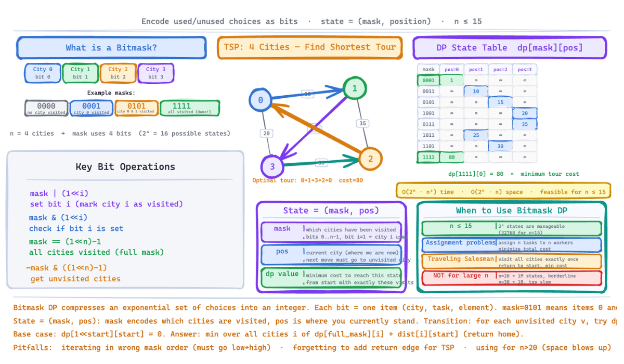>

In [ ]:
"""
Pattern 50 — State Compression DP (Bitmask DP)

Demonstrates:
1. Bitmask operations and utilities
2. Traveling Salesman Problem (TSP) using bitmask DP
3. Assignment problem with bitmask DP
4. Optimal subset selection
"""

print("=" * 70)
print("EXAMPLE 1: BITMASK OPERATIONS & UTILITIES")
print("=" * 70)

def print_bitmask(mask, n):
    """Print bitmask in binary with item interpretation."""
    binary = format(mask, f'0{n}b')
    items = [i for i in range(n) if mask & (1 << i)]
    return binary, items

def popcount(mask):
    """Count number of set bits (items in set)."""
    count = 0
    while mask:
        count += mask & 1
        mask >>= 1
    return count

print("\nBitmask operations for n=4 items:")
n = 4
operations = [
    ("Empty set", 0b0000),
    ("Just item 0", 1 << 0),
    ("Just item 2", 1 << 2),
    ("Items 0,2", (1 << 0) | (1 << 2)),
    ("All items", (1 << n) - 1),
]

for desc, mask in operations:
    binary, items = print_bitmask(mask, n)
    count = popcount(mask)
    print(f"  {desc:20} = 0b{binary} = {mask:2d}, items={items}, popcount={count}")

print("\nAdd/remove item from mask:")
mask = 0b0101  # Items 0, 2
print(f"  Start: mask=0b{mask:04b} (items: 0, 2)")
mask |= (1 << 1)
print(f"  Add item 1: mask=0b{mask:04b} (items: 0, 1, 2)")
mask ^= (1 << 0)
print(f"  Remove item 0: mask=0b{mask:04b} (items: 1, 2)")

print("\nIterating through all subsets of n=3:")
n = 3
for mask in range(1 << n):
    binary, items = print_bitmask(mask, n)
    print(f"  mask={mask}: 0b{binary} → items {items}")

print("\n" + "=" * 70)
print("EXAMPLE 2: TRAVELING SALESMAN PROBLEM (TSP)")
print("=" * 70)

def tsp_bitmask_dp(dist):
    """
    Solve TSP using bitmask DP.
    
    Returns minimum cost to visit all cities exactly once and return to start.
    
    DP[mask][last] = minimum cost to visit cities in 'mask', ending at 'last'
    
    dist: adjacency matrix, dist[i][j] = cost to go from city i to city j
    """
    n = len(dist)
    INF = float('inf')
    
    # dp[mask][i] = min cost to visit all cities in mask, ending at city i
    dp = [[INF] * n for _ in range(1 << n)]
    
    # Base case: start from city 0
    dp[1][0] = 0
    
    # Iterate through all masks in increasing order
    for mask in range(1 << n):
        for last in range(n):
            if dp[mask][last] == INF:
                continue
            
            # Try visiting next city
            for next_city in range(n):
                if mask & (1 << next_city):  # Already visited
                    continue
                
                new_mask = mask | (1 << next_city)
                new_cost = dp[mask][last] + dist[last][next_city]
                dp[new_mask][next_city] = min(dp[new_mask][next_city], new_cost)
    
    # Return to city 0 from any last city
    full_mask = (1 << n) - 1
    result = min(dp[full_mask][i] + dist[i][0] for i in range(n))
    
    return result

print("\nTSP Test Cases:")
tsp_tests = [
    (
        "Triangle (symmetric)",
        [[0, 10, 15],
         [10, 0, 20],
         [15, 20, 0]],
        45
    ),
    (
        "Square",
        [[0, 1, 4, 5],
         [1, 0, 2, 3],
         [4, 2, 0, 1],
         [5, 3, 1, 0]],
        10
    ),
]

for name, dist_matrix, expected in tsp_tests:
    result = tsp_bitmask_dp(dist_matrix)
    status = "✓" if result == expected else "✗"
    print(f"  {name:25} → Cost: {result:3}, Expected: {expected:3} {status}")

print("\n" + "=" * 70)
print("EXAMPLE 3: JOB ASSIGNMENT PROBLEM")
print("=" * 70)

def min_cost_assignment(cost_matrix):
    """
    Assign n workers to n jobs with minimum cost.
    
    DP[mask][worker] = min cost to assign first 'popcount(mask)' jobs 
                       to 'worker' and some of his predecessors
    
    cost_matrix[i][j] = cost for worker i to do job j
    """
    n = len(cost_matrix)
    INF = float('inf')
    
    # dp[mask][w] = min cost to assign jobs in mask to workers 0..w
    # (mask represents which jobs are assigned)
    dp = [[INF] * n for _ in range(1 << n)]
    
    # Base: assign no jobs
    for w in range(n):
        dp[0][w] = 0
    
    # Fill DP table
    for mask in range(1 << n):
        for w in range(n):
            if dp[mask][w] == INF:
                continue
            
            # Try assigning next job to worker w
            job = bin(mask).count('1')  # Next job to assign
            if job >= n:
                continue
            
            new_mask = mask | (1 << job)
            new_cost = dp[mask][w] + cost_matrix[w][job]
            dp[new_mask][w] = min(dp[new_mask][w], new_cost)
            
            # Or pass to next worker
            if w + 1 < n:
                dp[mask][w + 1] = min(dp[mask][w + 1], dp[mask][w])
    
    return dp[(1 << n) - 1][n - 1]

print("\nJob Assignment Test Cases:")
assign_tests = [
    (
        "3 workers, 3 jobs",
        [[5, 7, 9],
         [4, 6, 8],
         [1, 2, 3]],
        11  # Worker 0→job0(5), Worker 1→job1(6), Worker 2→job2(3)
    ),
]

for name, cost, expected in assign_tests:
    result = min_cost_assignment(cost)
    status = "✓" if result == expected else "✗"
    print(f"  {name:25} → Cost: {result:3}, Expected: {expected:3} {status}")

print("\n" + "=" * 70)
print("EXAMPLE 4: SUBSET DP - COUNT SUBSETS WITH SUM")
print("=" * 70)

def count_subsets_with_sum(items, target_sum):
    """
    Count how many subsets have exactly target_sum.
    
    Uses DP where:
    dp[mask] = sum of items in subset represented by mask
    """
    n = len(items)
    subset_sums = {}
    
    # Compute sum for each subset
    for mask in range(1 << n):
        subset_sum = sum(items[i] for i in range(n) if mask & (1 << i))
        if subset_sum not in subset_sums:
            subset_sums[subset_sum] = []
        subset_sums[subset_sum].append(mask)
    
    # Count subsets with target sum
    count = len(subset_sums.get(target_sum, []))
    subsets = subset_sums.get(target_sum, [])
    
    return count, subsets

print("\nSubset sum test (items = [1, 2, 3]):")
items = [1, 2, 3]
for target in range(1, 7):
    count, subsets = count_subsets_with_sum(items, target)
    subset_strings = []
    for mask in subsets:
        items_in_subset = [items[i] for i in range(len(items)) if mask & (1 << i)]
        subset_strings.append(str(items_in_subset))
    result_str = ", ".join(subset_strings) if subset_strings else "none"
    print(f"  Sum={target}: {count} subset(s) → {result_str}")

print("\n" + "=" * 70)
print("EXAMPLE 5: OPTIMAL SUBSET SELECTION")
print("=" * 70)

def max_value_subset_with_constraint(values, weights, capacity):
    """
    Select subset of items maximizing value without exceeding capacity.
    Uses bitmask to enumerate all $2^n$ subsets.
    
    Returns: (max_value, best_subset_mask)
    """
    n = len(values)
    max_val = -1
    best_mask = -1
    
    for mask in range(1 << n):
        total_value = sum(values[i] for i in range(n) if mask & (1 << i))
        total_weight = sum(weights[i] for i in range(n) if mask & (1 << i))
        
        if total_weight <= capacity and total_value > max_val:
            max_val = total_value
            best_mask = mask
    
    # Decode best subset
    best_items = [i for i in range(n) if best_mask & (1 << i)]
    best_weight = sum(weights[i] for i in best_items)
    
    return max_val, best_items, best_weight

print("\nKnapsack: max value with weight limit")
values = [10, 20, 30]  # item values
weights = [5, 10, 15]  # item weights
capacity = 25

max_val, items, used_weight = max_value_subset_with_constraint(values, weights, capacity)
print(f"  Items: {list(range(len(values)))}")
print(f"  Values: {values}, Weights: {weights}")
print(f"  Capacity: {capacity}")
print(f"  Best subset: items {items}")
print(f"  Total value: {max_val}, Total weight: {used_weight} ✓")

print("\n" + "=" * 70)
print("KEY TAKEAWAYS")
print("=" * 70)
print("✓ Bitmask = compact representation of a set using bits")
print("✓ Use when n ≤ 15–20 but all 2^n subsets matter")
print("✓ DP[mask][position] = best value for this state")
print("✓ Time complexity: O(2^n · n^2) — exponential but practical for small n")
print("✓ Common problems: TSP, assignment, subset selection, Hamiltonian paths")
print("=" * 70)

## Pattern 51 — Lowest Common Ancestor (LCA)

**Importance:** ★★★★★

### Story
Two cousins are at a family reunion and want to know their **closest shared ancestor**. Instead of drawing the whole family tree, every person asks their children one question: *"Is either cousin somewhere below you?"*

- A person who **is** one of the cousins answers "yes, me".
- A person who hears "yes" from **both** the left side and the right side of the family knows: *the cousins split right here — I'm the closest common ancestor.*
- A person who hears "yes" from only one side just passes that answer up.

The first person to hear "yes" from both sides is the LCA. One post-order walk, O(n).

### When to Use
*   **Lowest Common Ancestor of a Binary Tree** (LC 236) — the classic
*   **LCA of a Binary Search Tree** (LC 235) — use BST ordering, O(h)
*   **LCA with parent pointers** (LC 1650) — becomes "intersection of two linked lists"
*   **Distance between two nodes**: `depth(p) + depth(q) - 2 * depth(lca)`
*   **Problem clues**: "closest common", "shared ancestor", "where do the paths from root to p and q split?"

### Core Idea
```
              3
            /   \
           5     1
          / \   / \
         6   2 0   8
            / \
           7   4

LCA(5, 1) = 3     ← found on different sides of 3
LCA(5, 4) = 5     ← a node can be its own ancestor
```

**General binary tree** (post-order combine):
```
def lca(root, p, q):
    if not root or root is p or root is q:
        return root
    left = lca(root.left, p, q)
    right = lca(root.right, p, q)
    if left and right:      # p and q are on different sides
        return root
    return left or right    # pass up whichever side found something
```

**BST** — no recursion into both sides needed:
```
while root:
    if p.val < root.val and q.val < root.val: root = root.left
    elif p.val > root.val and q.val > root.val: root = root.right
    else: return root       # split point
```

**Parent pointers** — two pointers walk up; when one hits the top, jump to the other's start. They meet at the LCA after at most `depth(p) + depth(q)` steps (same trick as Intersection of Two Linked Lists).

### Pitfalls
*   **Assuming both nodes exist** — the standard solution returns `p` even if `q` isn't in the tree. If that's possible, count how many targets were found.
*   **Forgetting a node can be its own ancestor** — `LCA(5, 4) = 5`, not 3.
*   **Comparing values instead of nodes** when values can repeat — compare with `is`.
*   **Using the BST shortcut on a non-BST** — it silently returns wrong answers.

### Mini Example
**Example:** tree above → `LCA(5, 1) = 3`, `LCA(5, 4) = 5`, `LCA(6, 4) = 5`.

In [ ]:
class TreeNode:
    def __init__(self, val, left=None, right=None):
        self.val = val
        self.left = left
        self.right = right
        self.parent = None


def build_tree(values):
    """Level-order list -> tree. Also sets parent pointers. Returns (root, {val: node})."""
    nodes = {}
    if not values:
        return None, nodes
    root = TreeNode(values[0])
    nodes[root.val] = root
    queue, i = [root], 1
    for node in queue:
        for side in ("left", "right"):
            if i < len(values) and values[i] is not None:
                child = TreeNode(values[i])
                child.parent = node
                setattr(node, side, child)
                nodes[child.val] = child
                queue.append(child)
            i += 1
        if i >= len(values):
            break
    return root, nodes


# ---------- 1. General binary tree (LC 236) ----------
def lca(root, p, q):
    if not root or root is p or root is q:
        return root
    left = lca(root.left, p, q)
    right = lca(root.right, p, q)
    if left and right:
        return root
    return left or right


# ---------- 2. Binary Search Tree (LC 235) ----------
def lca_bst(root, p, q):
    while root:
        if p.val < root.val and q.val < root.val:
            root = root.left
        elif p.val > root.val and q.val > root.val:
            root = root.right
        else:
            return root


# ---------- 3. Parent pointers, no root given (LC 1650) ----------
def lca_parent(p, q):
    a, b = p, q
    while a is not b:
        a = a.parent if a.parent else q
        b = b.parent if b.parent else p
    return a


# ---------- Application: distance between two nodes ----------
def depth(root, target, d=0):
    if not root: return -1
    if root is target: return d
    left = depth(root.left, target, d + 1)
    return left if left != -1 else depth(root.right, target, d + 1)

def distance(root, p, q):
    anc = lca(root, p, q)
    return depth(root, p) + depth(root, q) - 2 * depth(root, anc)


root, n = build_tree([3, 5, 1, 6, 2, 0, 8, None, None, 7, 4])
for a, b in [(5, 1), (5, 4), (6, 4), (7, 8)]:
    print(f"LCA({a}, {b}) = {lca(root, n[a], n[b]).val}  |  via parents = {lca_parent(n[a], n[b]).val}")
assert lca(root, n[5], n[1]).val == 3
assert lca(root, n[5], n[4]).val == 5
assert lca(root, n[6], n[4]).val == 5
assert lca_parent(n[7], n[8]).val == 3
print("distance(6, 4) =", distance(root, n[6], n[4]))   # 6 -> 5 -> 2 -> 4 = 3
assert distance(root, n[6], n[4]) == 3

bst_root, b = build_tree([6, 2, 8, 0, 4, 7, 9, None, None, 3, 5])
print("BST LCA(2, 8) =", lca_bst(bst_root, b[2], b[8]).val)   # 6
print("BST LCA(2, 4) =", lca_bst(bst_root, b[2], b[4]).val)   # 2
assert lca_bst(bst_root, b[2], b[8]).val == 6
assert lca_bst(bst_root, b[3], b[5]).val == 4

## Pattern 52 — Monotonic Queue (Sliding Window Maximum)

**Importance:** ★★★★

### Story
A company keeps a shortlist of candidates for a role. Every day a new candidate applies, and every day the oldest application expires. The rule for the shortlist:

> When a new candidate arrives, anyone already on the list who is **older and not better** is removed — they will expire sooner *and* they're weaker, so they can never be the best choice again.

The shortlist ends up sorted from strongest (front) to weakest (back). The best candidate today is always at the **front**; expired ones leave from the front; new ones push weak ones out from the **back**.

That's a **monotonic queue**: a deque that keeps a window's candidates in decreasing order, giving the window max (or min) in O(1) — and the whole scan in O(n) instead of O(n·k).

It's the sliding-window version of the Monotonic Stack (Pattern 10): the stack only removes from one end; the queue also expires old items from the other end.

### When to Use
*   **Sliding Window Maximum / Minimum** (LC 239)
*   **Longest subarray where max − min ≤ limit** (LC 1438) — one max-deque + one min-deque
*   **Shortest Subarray with Sum at Least K** with negatives (LC 862) — increasing deque of prefix sums
*   **DP where `dp[i]` = best of the last k states** — Jump Game VI (LC 1696), Constrained Subsequence Sum (LC 1425)
*   **Problem clues**: "every window of size k", "max/min within the last k", "O(n)" required

### Core Idea
```
nums = [1, 3, -1, -3, 5, 3, 6, 7], k = 3     deque holds INDICES, values decreasing

i=0  1   deque: [1]
i=1  3   pop 1 (smaller)          deque: [3]
i=2 -1                            deque: [3, -1]          window max = 3
i=3 -3                            deque: [3, -1, -3]      window max = 3
i=4  5   expire 3, pop -3, -1     deque: [5]              window max = 5
i=5  3                            deque: [5, 3]           window max = 5
i=6  6   pop 3, 5                 deque: [6]              window max = 6
i=7  7   pop 6                    deque: [7]              window max = 7
```

```
from collections import deque
dq = deque()
for i, x in enumerate(nums):
    while dq and nums[dq[-1]] <= x:   # back: drop weaker, older items
        dq.pop()
    dq.append(i)
    if dq[0] <= i - k:                # front: drop expired index
        dq.popleft()
    if i >= k - 1:
        result.append(nums[dq[0]])    # front is the window max
```
Each index is pushed once and popped at most once → **O(n)** time, **O(k)** space.

### Pitfalls
*   **Storing values instead of indices** — you need the index to know when the front has left the window.
*   **Mixing up the ends** — expire from the **front**, remove dominated items from the **back**.
*   **Recording results before the first window is full** — only record when `i >= k - 1`.
*   **Using a heap** — works, but O(n log n) and needs lazy deletion; the deque is the expected answer.
*   **Wrong direction for min** — for window minimum keep the deque *increasing* (pop while `nums[back] >= x`).

### Mini Example
**Example:** `nums = [1, 3, -1, -3, 5, 3, 6, 7], k = 3` → **[3, 3, 5, 5, 6, 7]**

In [ ]:
from collections import deque


# ---------- 1. Sliding Window Maximum (LC 239) ----------
def max_sliding_window(nums, k):
    dq, result = deque(), []
    for i, x in enumerate(nums):
        while dq and nums[dq[-1]] <= x:
            dq.pop()
        dq.append(i)
        if dq[0] <= i - k:
            dq.popleft()
        if i >= k - 1:
            result.append(nums[dq[0]])
    return result


# ---------- 2. Longest subarray with |max - min| <= limit (LC 1438) ----------
def longest_subarray(nums, limit):
    max_dq, min_dq = deque(), deque()    # decreasing / increasing
    left = best = 0
    for right, x in enumerate(nums):
        while max_dq and nums[max_dq[-1]] <= x: max_dq.pop()
        while min_dq and nums[min_dq[-1]] >= x: min_dq.pop()
        max_dq.append(right)
        min_dq.append(right)
        while nums[max_dq[0]] - nums[min_dq[0]] > limit:   # shrink window
            left += 1
            if max_dq[0] < left: max_dq.popleft()
            if min_dq[0] < left: min_dq.popleft()
        best = max(best, right - left + 1)
    return best


# ---------- 3. Jump Game VI (LC 1696): dp[i] = nums[i] + max(dp[i-k .. i-1]) ----------
def max_result(nums, k):
    dp = [0] * len(nums)
    dp[0] = nums[0]
    dq = deque([0])
    for i in range(1, len(nums)):
        if dq[0] < i - k:
            dq.popleft()
        dp[i] = nums[i] + dp[dq[0]]
        while dq and dp[dq[-1]] <= dp[i]:
            dq.pop()
        dq.append(i)
    return dp[-1]


print(max_sliding_window([1, 3, -1, -3, 5, 3, 6, 7], 3))   # [3, 3, 5, 5, 6, 7]
print(longest_subarray([8, 2, 4, 7], 4))                   # 2  ([2, 4])
print(longest_subarray([10, 1, 2, 4, 7, 2], 5))            # 4  ([2, 4, 7, 2])
print(max_result([1, -1, -2, 4, -7, 3], 2))                # 7  (1 -> -1 -> 4 -> 3)

assert max_sliding_window([1, 3, -1, -3, 5, 3, 6, 7], 3) == [3, 3, 5, 5, 6, 7]
assert max_sliding_window([9, 9, 9], 2) == [9, 9]
assert longest_subarray([8, 2, 4, 7], 4) == 2
assert longest_subarray([10, 1, 2, 4, 7, 2], 5) == 4
assert max_result([1, -1, -2, 4, -7, 3], 2) == 7

## Pattern 53 — Sorting & Quickselect

**Importance:** ★★★★★

### Story
A librarian gets a cart of 1,000 returned books. Three different requests come in:

1. *"Shelve them by author, then by title."* → a **full sort with a custom key**.
2. *"Just find me the 10th thickest book."* → no need to rank all 1,000. Pick a random book as a **pivot**, split the cart into "thicker" and "thinner", and only keep digging in the pile that must contain the 10th. That's **Quickselect** — average O(n).
3. *"How many pairs of books are out of order?"* → while **merge sorting** the cart, every time a book from the right half jumps ahead of books in the left half, all those left-half books form out-of-order pairs. Count them during the merge.

In interviews you rarely write a sort from scratch for its own sake. Sorting is the **preprocessing step** that unlocks greedy / two pointers / intervals — and its building blocks (partition, merge) solve problems directly.

### When to Use
*   **Custom ordering**: Largest Number (LC 179), Sort Characters by Frequency, Reorder Log Files, sort by multiple keys
*   **Kth largest / smallest in O(n) average**: Kth Largest Element (LC 215), K Closest Points to Origin (LC 973)
*   **Counting during merge sort**: Count Inversions, Count of Smaller Numbers After Self (LC 315), Reverse Pairs (LC 493)
*   **3-way partition**: Sort Colors / Dutch National Flag (LC 75)
*   **Counting / bucket sort** when the value range is small: H-Index, Top K Frequent (bucket by frequency), Maximum Gap
*   **"Sort first" preprocessing**: intervals, two-sum on sorted input, greedy scheduling, meeting rooms

### Core Idea
**Custom keys** (Python's sort is stable, O(n log n)):
```
people.sort(key=lambda p: (-p.height, p.name))   # height desc, then name asc
```
**Custom comparator** when the order depends on *pairs*:
```
from functools import cmp_to_key
nums.sort(key=cmp_to_key(lambda a, b: -1 if a + b > b + a else 1))
```
**Quickselect** (Kth smallest = index k-1 after sorting):
```
pick random pivot
partition into  [ < pivot ][ == pivot ][ > pivot ]
if k falls in the left part  → recurse left only
if k falls in the equal part → answer is pivot
else                         → recurse right only (adjust k)
Average O(n): n + n/2 + n/4 + ... = 2n
```
**Merge sort with counting**:
```
merging left=[2, 4] and right=[1, 3]
take 1 from right → it jumps over 2 and 4 → +2 inversions
take 2, take 3 from right → jumps over 4 → +1 inversion
```
**Dutch flag**: three pointers `low`, `mid`, `high` — 0s swap to low, 2s swap to high, 1s stay.

### Pitfalls
*   **Comparator returning a bool** — `cmp_to_key` needs negative / 0 / positive.
*   **Quickselect with a fixed pivot** — O(n²) on sorted input; always randomize.
*   **Off-by-one for Kth largest** — it's the element at index `n - k` in ascending order.
*   **Largest Number edge case** — `[0, 0]` should return `"0"`, not `"00"`.
*   **Forgetting stability** — you can sort by secondary key first, then primary key, and ties keep their order.
*   **Dutch flag**: don't advance `mid` after swapping with `high` — the swapped-in value is unchecked.

### Mini Example
**Example 1:** `[3, 30, 34, 5, 9]` → Largest Number **"9534330"**
**Example 2:** `[3, 2, 1, 5, 6, 4], k = 2` → 2nd largest = **5**
**Example 3:** `[2, 4, 1, 3, 5]` → **3** inversions: (2,1), (4,1), (4,3)

In [ ]:
import random
from functools import cmp_to_key


# ---------- 1. Custom comparator: Largest Number (LC 179) ----------
def largest_number(nums):
    strs = list(map(str, nums))
    strs.sort(key=cmp_to_key(lambda a, b: -1 if a + b > b + a else (1 if a + b < b + a else 0)))
    result = "".join(strs)
    return "0" if result[0] == "0" else result


# ---------- 2. Quickselect: Kth largest (LC 215) ----------
def kth_largest(nums, k):
    target = len(nums) - k          # index of the answer in ascending order

    def select(arr, idx):
        pivot = random.choice(arr)
        less = [x for x in arr if x < pivot]
        equal = [x for x in arr if x == pivot]
        greater = [x for x in arr if x > pivot]
        if idx < len(less):
            return select(less, idx)
        if idx < len(less) + len(equal):
            return pivot
        return select(greater, idx - len(less) - len(equal))

    return select(nums, target)


# ---------- 3. Merge sort + counting inversions ----------
def count_inversions(arr):
    def sort(a):
        if len(a) <= 1:
            return a, 0
        mid = len(a) // 2
        left, inv_l = sort(a[:mid])
        right, inv_r = sort(a[mid:])
        merged, i, j, inv = [], 0, 0, inv_l + inv_r
        while i < len(left) and j < len(right):
            if left[i] <= right[j]:
                merged.append(left[i]); i += 1
            else:
                merged.append(right[j]); j += 1
                inv += len(left) - i       # right[j] jumps over every remaining left item
        merged += left[i:] + right[j:]
        return merged, inv

    return sort(arr)[1]


# ---------- 4. Dutch National Flag: Sort Colors (LC 75) ----------
def sort_colors(nums):
    low, mid, high = 0, 0, len(nums) - 1
    while mid <= high:
        if nums[mid] == 0:
            nums[low], nums[mid] = nums[mid], nums[low]
            low += 1; mid += 1
        elif nums[mid] == 2:
            nums[mid], nums[high] = nums[high], nums[mid]
            high -= 1                      # don't move mid: swapped-in value is unchecked
        else:
            mid += 1
    return nums


# ---------- 5. Multi-key sort ----------
people = [("bob", 180), ("alice", 165), ("carol", 180), ("dave", 165)]
by_height_desc_then_name = sorted(people, key=lambda p: (-p[1], p[0]))


print(largest_number([3, 30, 34, 5, 9]))         # 9534330
print(kth_largest([3, 2, 1, 5, 6, 4], 2))         # 5
print(count_inversions([2, 4, 1, 3, 5]))          # 3
print(sort_colors([2, 0, 2, 1, 1, 0]))            # [0, 0, 1, 1, 2, 2]
print(by_height_desc_then_name)

assert largest_number([3, 30, 34, 5, 9]) == "9534330"
assert largest_number([0, 0]) == "0"
assert kth_largest([3, 2, 3, 1, 2, 4, 5, 5, 6], 4) == 4
assert count_inversions([2, 4, 1, 3, 5]) == 3
assert count_inversions([5, 4, 3, 2, 1]) == 10
assert sort_colors([2, 0, 2, 1, 1, 0]) == [0, 0, 1, 1, 2, 2]
assert by_height_desc_then_name == [("bob", 180), ("carol", 180), ("alice", 165), ("dave", 165)]

## Pattern 54 — Prefix Sum + Hash Map (Subarray Sum Equals K)

**Importance:** ★★★★★

### Story
You're on a road trip and your car's odometer shows the **total** miles driven since the start. You want to know: *"Was there any stretch of road that was exactly 50 miles long?"*

A stretch from point A to point B is `odometer(B) − odometer(A)`. So at every stop, you just ask: **"Have I ever seen the reading `current − 50` before?"** Keep a notebook (hash map) of every reading you've passed and how many times — one lookup per stop answers the question.

That's this pattern: **prefix sums turn "subarray sum" into "difference of two prefixes", and a hash map finds the matching earlier prefix in O(1).**

Why not a sliding window (Pattern 2)? Because with **negative numbers**, growing the window can shrink the sum — the window has no idea which way to move. Prefix + hash map doesn't care about signs.

### When to Use
*   **Count subarrays with sum = k** (LC 560) — especially with negatives
*   **Contiguous Array** — longest subarray with equal 0s and 1s (LC 525): treat 0 as −1, look for sum 0
*   **Subarray Sums Divisible by K** (LC 974) — store `prefix % k`
*   **Continuous Subarray Sum** (LC 523) — same remainder seen at least 2 apart
*   **Longest subarray with sum = k** — store the **first** index of each prefix
*   **Count of nice subarrays / binary subarrays with sum** (LC 1248, 930)
*   **Problem clues**: "subarray", "sum equals", "divisible by", negatives allowed, O(n) required

### Core Idea
```
nums = [1, 2, 3], k = 3

prefix:      0 → 1 → 3 → 6
             ↑   seed {0: 1} = "empty prefix"

at prefix 3: need 3 - 3 = 0  → seen once → [1, 2]
at prefix 6: need 6 - 3 = 3  → seen once → [3]
answer = 2
```

**Count version:**
```
count = {0: 1}
prefix = ans = 0
for x in nums:
    prefix += x
    ans += count.get(prefix - k, 0)        # query FIRST
    count[prefix] = count.get(prefix, 0) + 1   # then record
```

**Longest version** — store the earliest index, never overwrite:
```
first = {0: -1}
for i, x in enumerate(nums):
    prefix += x
    if prefix - k in first: best = max(best, i - first[prefix - k])
    if prefix not in first: first[prefix] = i
```

### Pitfalls
*   **Forgetting the `{0: 1}` (or `{0: -1}`) seed** — misses subarrays that start at index 0.
*   **Recording before querying** — with `k = 0` you'd count the empty subarray.
*   **Overwriting the first index** in the "longest" version — you want the *earliest* occurrence.
*   **Modulo with negatives** — Python's `%` already returns a non-negative result; in Java/JS you'd need `((p % k) + k) % k`.
*   **Reaching for sliding window** when the array has negatives.

### Mini Example
**Example 1:** `[1, 1, 1], k = 2` → **2** subarrays
**Example 2:** `[0, 1, 0, 1, 1, 0]` → longest equal 0s/1s = **6**
**Example 3:** `[4, 5, 0, -2, -3, 1], k = 5` → **7** subarrays divisible by 5

In [ ]:
from collections import defaultdict


# ---------- 1. Subarray Sum Equals K (LC 560) ----------
def subarray_sum(nums, k):
    count = defaultdict(int)
    count[0] = 1
    prefix = ans = 0
    for x in nums:
        prefix += x
        ans += count[prefix - k]
        count[prefix] += 1
    return ans


# ---------- 2. Contiguous Array: equal 0s and 1s (LC 525) ----------
def find_max_length(nums):
    first = {0: -1}
    prefix = best = 0
    for i, x in enumerate(nums):
        prefix += 1 if x == 1 else -1
        if prefix in first:
            best = max(best, i - first[prefix])
        else:
            first[prefix] = i
    return best


# ---------- 3. Subarray Sums Divisible by K (LC 974) ----------
def subarrays_div_by_k(nums, k):
    count = defaultdict(int)
    count[0] = 1
    prefix = ans = 0
    for x in nums:
        prefix = (prefix + x) % k        # Python % is already non-negative
        ans += count[prefix]
        count[prefix] += 1
    return ans


# ---------- 4. Longest subarray with sum = k ----------
def longest_subarray_sum_k(nums, k):
    first = {0: -1}
    prefix = best = 0
    for i, x in enumerate(nums):
        prefix += x
        if prefix - k in first:
            best = max(best, i - first[prefix - k])
        if prefix not in first:
            first[prefix] = i
    return best


print(subarray_sum([1, 1, 1], 2))                    # 2
print(subarray_sum([1, -1, 1, -1], 0))               # 4  (negatives: sliding window fails here)
print(find_max_length([0, 1, 0, 1, 1, 0]))           # 6
print(subarrays_div_by_k([4, 5, 0, -2, -3, 1], 5))   # 7
print(longest_subarray_sum_k([1, -1, 5, -2, 3], 3))  # 4  ([1, -1, 5, -2])

assert subarray_sum([1, 1, 1], 2) == 2
assert subarray_sum([1, 2, 3], 3) == 2
assert subarray_sum([1, -1, 1, -1], 0) == 4
assert find_max_length([0, 1, 0, 1, 1, 0]) == 6
assert subarrays_div_by_k([4, 5, 0, -2, -3, 1], 5) == 7
assert longest_subarray_sum_k([1, -1, 5, -2, 3], 3) == 4

## Pattern 55 — Cyclic Sort (Index as Hash)

**Importance:** ★★★★

### Story
A small hotel has rooms numbered **1 to n**. Exactly n guests arrive, each holding a keycard with a room number — but they're all standing in the wrong rooms. You walk down the hallway:

- Look at the guest in the current room. If they belong somewhere else, **swap** them with whoever is in their correct room.
- Keep swapping until the current room holds its rightful guest (or a guest whose room is already correctly taken — a duplicate — or a keycard for a room that doesn't exist).
- Move to the next room.

Each swap puts at least one guest in their final room, so the whole thing is **O(n)**. Afterwards, any room `i` that doesn't contain guest `i` tells you exactly what's **missing** and what's **duplicated** — with no extra memory.

The trick: **when values are in the range 1..n, the array itself can be used as the hash map — value `v` "lives" at index `v - 1`.**

### When to Use
*   **Missing Number** (LC 268), **Find All Numbers Disappeared** (LC 448)
*   **Find the Duplicate Number** (LC 287), **Find All Duplicates** (LC 442)
*   **First Missing Positive** (LC 41) — the famous Hard
*   **Set Mismatch** (LC 645) — one duplicate + one missing
*   **Problem clues**: "numbers in range [1, n]" or "[0, n]", "O(n) time and O(1) extra space", "missing", "duplicate"

### Core Idea
```
nums = [3, 4, -1, 1]       value v belongs at index v - 1

i=0: 3 → swap with index 2 → [-1, 4, 3, 1]
i=0: -1 out of range → move on
i=1: 4 → swap with index 3 → [-1, 1, 3, 4]
i=1: 1 → swap with index 0 → [1, -1, 3, 4]
i=1: -1 out of range → move on
i=2, i=3: already in place

scan: index 1 holds -1 (not 2) → first missing positive = 2
```

```
i = 0
while i < n:
    j = nums[i] - 1                        # correct index for nums[i]
    if 0 <= j < n and nums[i] != nums[j]:  # in range and target not already correct
        nums[i], nums[j] = nums[j], nums[i]
    else:
        i += 1

for i in range(n):
    if nums[i] != i + 1:
        # i + 1 is missing, nums[i] is a duplicate (or junk)
```

**Alternative — sign marking** (no swaps, keeps order): for each `v`, negate `nums[abs(v) - 1]`. Indices that stay positive are missing; seeing an already-negative slot means `abs(v)` is a duplicate.

### Pitfalls
*   **Infinite loop on duplicates** — check `nums[i] != nums[j]`, not `i != j`.
*   **Python swap trap** — `nums[i], nums[nums[i] - 1] = nums[nums[i] - 1], nums[i]` is **buggy**: `nums[i]` is reassigned before the second target index is computed. Always compute `j` first.
*   **Not filtering out-of-range values** (0, negatives, > n) before using them as an index.
*   **0-based vs 1-based** — for range `[0, n]` the home of `v` is index `v`, not `v - 1`.
*   **It mutates the input** — mention it, or copy the array if that's not allowed.

### Mini Example
**Example 1:** `[3, 4, -1, 1]` → first missing positive = **2**
**Example 2:** `[4, 3, 2, 7, 8, 2, 3, 1]` → missing **[5, 6]**, duplicates **[2, 3]**

In [ ]:
def cyclic_sort(nums):
    """Place every value v in [1, n] at index v - 1. Out-of-range values and extra duplicates stay wherever they land."""
    i, n = 0, len(nums)
    while i < n:
        j = nums[i] - 1
        if 0 <= j < n and nums[i] != nums[j]:
            nums[i], nums[j] = nums[j], nums[i]
        else:
            i += 1
    return nums


# ---------- 1. First Missing Positive (LC 41) ----------
def first_missing_positive(nums):
    nums = cyclic_sort(nums[:])
    for i, v in enumerate(nums):
        if v != i + 1:
            return i + 1
    return len(nums) + 1


# ---------- 2. All missing + all duplicates (LC 448 / LC 442) ----------
def missing_and_duplicates(nums):
    nums = cyclic_sort(nums[:])
    missing = [i + 1 for i, v in enumerate(nums) if v != i + 1]
    duplicates = sorted(v for i, v in enumerate(nums) if v != i + 1)
    return missing, duplicates


# ---------- 3. Missing Number, range [0, n] (LC 268) ----------
def missing_number(nums):
    i, n = 0, len(nums)
    while i < n:
        j = nums[i]                         # value v lives at index v
        if j < n and nums[i] != nums[j]:
            nums[i], nums[j] = nums[j], nums[i]
        else:
            i += 1
    for i, v in enumerate(nums):
        if v != i:
            return i
    return n


# ---------- 4. Sign marking alternative: Find All Duplicates (LC 442) ----------
def find_duplicates_sign(nums):
    nums = nums[:]
    dups = []
    for v in nums:
        idx = abs(v) - 1
        if nums[idx] < 0:
            dups.append(abs(v))
        else:
            nums[idx] = -nums[idx]
    return dups


print(first_missing_positive([3, 4, -1, 1]))               # 2
print(first_missing_positive([7, 8, 9, 11, 12]))           # 1
print(missing_and_duplicates([4, 3, 2, 7, 8, 2, 3, 1]))    # ([5, 6], [2, 3])
print(missing_number([3, 0, 1]))                           # 2
print(find_duplicates_sign([4, 3, 2, 7, 8, 2, 3, 1]))      # [2, 3]

assert first_missing_positive([3, 4, -1, 1]) == 2
assert first_missing_positive([1, 2, 0]) == 3
assert first_missing_positive([7, 8, 9, 11, 12]) == 1
assert missing_and_duplicates([4, 3, 2, 7, 8, 2, 3, 1]) == ([5, 6], [2, 3])
assert missing_and_duplicates([1, 2, 2, 4]) == ([3], [2])     # Set Mismatch
assert missing_number([9, 6, 4, 2, 3, 5, 7, 0, 1]) == 8
assert sorted(find_duplicates_sign([4, 3, 2, 7, 8, 2, 3, 1])) == [2, 3]

## Pattern 56 — Palindromes (Expand Around Center + Palindrome DP)

**Importance:** ★★★★

### Story
Drop a pebble into a still pond. Ripples spread out **evenly in both directions** from the point of impact. A palindrome is the same idea: pick a center and grow outward one character at a time on each side — the ripple keeps going as long as the left and right characters match.

There are only `2n − 1` places a pebble can land: on each of the `n` characters (odd-length palindromes like `"aba"`) and in each of the `n − 1` gaps between characters (even-length like `"abba"`). Drop a pebble at every spot, measure how far each ripple travels, and you've found every palindromic substring — **O(n²) time, O(1) space**.

When the question is about **subsequences** (characters may be skipped) or about **cutting** a string into palindromes, ripples aren't enough — you switch to a DP table over `(i, j)` ranges.

### When to Use
*   **Longest Palindromic Substring** (LC 5) — expand around center
*   **Palindromic Substrings** — count them (LC 647) — expand around center
*   **Valid Palindrome / Valid Palindrome II** (LC 125, 680) — two pointers, allow one skip
*   **Longest Palindromic Subsequence** (LC 516) — interval DP
*   **Palindrome Partitioning I / II** (LC 131, 132) — precompute `is_pal[i][j]`, then backtrack / DP
*   **Problem clues**: "palindrome", "reads the same backward", "mirror"

### Core Idea
**Expand around center:**
```
s = "babad"
center 'a' (index 1): b[a]b → "bab" ✓, expand again → out of bounds
center 'b' (index 2): a[b]a → "aba" ✓, expand: b vs d ✗
gaps: no two equal neighbours → no even palindromes
longest = "bab"
```
```
def expand(l, r):
    while l >= 0 and r < n and s[l] == s[r]:
        l -= 1; r += 1
    return l + 1, r            # palindrome is s[l+1 : r]

for c in range(n):
    expand(c, c)               # odd length
    expand(c, c + 1)           # even length
```

**Palindrome DP (substrings):**
```
is_pal[i][j] = s[i] == s[j] and (j - i < 2 or is_pal[i+1][j-1])
fill i from n-1 DOWN to 0, j from i UP to n-1   (inner range must be ready first)
```

**Longest Palindromic Subsequence:**
```
dp[i][j] = dp[i+1][j-1] + 2            if s[i] == s[j]
         = max(dp[i+1][j], dp[i][j-1]) otherwise
```

### Pitfalls
*   **Forgetting even-length centers** — `"abba"` has no single middle character.
*   **Off-by-one after expanding** — the loop overshoots by one on each side; the answer is `s[l+1 : r]`.
*   **Wrong DP fill order** — `is_pal[i][j]` depends on `is_pal[i+1][j-1]`, so `i` must go **downwards**.
*   **Substring vs subsequence** — substring = contiguous (expand works); subsequence = can skip (needs DP).
*   **Valid Palindrome II** — on the first mismatch, try skipping **either** side, not just one.

### Mini Example
**Example 1:** `"babad"` → longest palindromic substring **"bab"** (or "aba")
**Example 2:** `"aaa"` → **6** palindromic substrings: a, a, a, aa, aa, aaa
**Example 3:** `"bbbab"` → longest palindromic subsequence **4** ("bbbb")

In [ ]:
# ---------- 1. Longest Palindromic Substring (LC 5) ----------
def longest_palindrome(s):
    n = len(s)

    def expand(l, r):
        while l >= 0 and r < n and s[l] == s[r]:
            l -= 1
            r += 1
        return l + 1, r

    best_l, best_r = 0, 0
    for c in range(n):
        for l, r in (expand(c, c), expand(c, c + 1)):
            if r - l > best_r - best_l:
                best_l, best_r = l, r
    return s[best_l:best_r]


# ---------- 2. Count Palindromic Substrings (LC 647) ----------
def count_substrings(s):
    n, count = len(s), 0
    for center in range(2 * n - 1):        # n characters + n-1 gaps
        l, r = center // 2, center // 2 + center % 2
        while l >= 0 and r < n and s[l] == s[r]:
            count += 1
            l -= 1
            r += 1
    return count


# ---------- 3. Valid Palindrome II — at most one deletion (LC 680) ----------
def valid_palindrome_one_skip(s):
    def is_pal(l, r):
        while l < r:
            if s[l] != s[r]:
                return False
            l += 1; r -= 1
        return True

    l, r = 0, len(s) - 1
    while l < r:
        if s[l] != s[r]:
            return is_pal(l + 1, r) or is_pal(l, r - 1)   # skip either side
        l += 1; r -= 1
    return True


# ---------- 4. Longest Palindromic Subsequence (LC 516) ----------
def longest_palindrome_subseq(s):
    n = len(s)
    dp = [[0] * n for _ in range(n)]
    for i in range(n - 1, -1, -1):
        dp[i][i] = 1
        for j in range(i + 1, n):
            if s[i] == s[j]:
                dp[i][j] = dp[i + 1][j - 1] + 2
            else:
                dp[i][j] = max(dp[i + 1][j], dp[i][j - 1])
    return dp[0][n - 1] if n else 0


# ---------- 5. Palindrome Partitioning (LC 131): is_pal table + backtracking ----------
def partition(s):
    n = len(s)
    is_pal = [[False] * n for _ in range(n)]
    for i in range(n - 1, -1, -1):
        for j in range(i, n):
            is_pal[i][j] = s[i] == s[j] and (j - i < 2 or is_pal[i + 1][j - 1])

    result, path = [], []

    def backtrack(start):
        if start == n:
            result.append(path[:])
            return
        for end in range(start, n):
            if is_pal[start][end]:
                path.append(s[start:end + 1])
                backtrack(end + 1)
                path.pop()

    backtrack(0)
    return result


print(longest_palindrome("babad"))             # bab
print(longest_palindrome("cbbd"))              # bb
print(count_substrings("aaa"))                 # 6
print(valid_palindrome_one_skip("abca"))       # True
print(longest_palindrome_subseq("bbbab"))      # 4
print(partition("aab"))                        # [['a', 'a', 'b'], ['aa', 'b']]

assert longest_palindrome("babad") in ("bab", "aba")
assert longest_palindrome("cbbd") == "bb"
assert count_substrings("abc") == 3 and count_substrings("aaa") == 6
assert valid_palindrome_one_skip("abca") and not valid_palindrome_one_skip("abc")
assert longest_palindrome_subseq("bbbab") == 4
assert partition("aab") == [["a", "a", "b"], ["aa", "b"]]

## Pattern 57 — Difference Array (Range Updates)

**Importance:** ★★★★

### Story
A bus runs along a route with stops 0 to n. Hundreds of groups book rides: *"5 people from stop 2 to stop 7"*, *"3 people from stop 4 to stop 9"* … and you need the passenger count at every stop.

The slow way: for each booking, walk through every stop in its range and add the group size — O(n) per booking.

The smart driver only writes **two notes** per booking: `+5` at stop 2 (they get on) and `−5` at stop 7 (they get off). At the end of the day, drive the route once, keeping a **running total** of the notes — that total is exactly the number of passengers at each stop.

That's a **difference array**: each range update is **O(1)**, and one prefix-sum pass (Pattern 6) rebuilds the final array in **O(n)**. It's the reverse of prefix sum — prefix sum answers many range **queries**; difference array applies many range **updates**.

### When to Use
*   **Many range-add updates, then read the final array once**: Range Addition (LC 370), Corporate Flight Bookings (LC 1109)
*   **Capacity / overlap checks**: Car Pooling (LC 1094), maximum overlapping intervals, meeting rooms count
*   **Shifting Letters II** (LC 2381) — range shifts on a string
*   **2D difference array**: Stamping the Grid (LC 2132), adding values to sub-rectangles
*   **Problem clues**: "add v to every element from l to r", "bookings", "trips", "how many at each point"
*   **Not for**: updates interleaved with queries — use a Fenwick / Segment Tree instead

### Core Idea
```
n = 5, updates: +10 on [1,2], +20 on [2,3], +25 on [2,4]   (0-indexed)

diff (size n+1):
  +10 at 1, -10 at 3
  +20 at 2, -20 at 4
  +25 at 2, -25 at 5
diff   = [0, 10, 45, -10, -20, -25]
prefix = [0, 10, 55,  45,  25]        ← final array
```

```
diff = [0] * (n + 1)
for l, r, v in updates:          # inclusive range [l, r]
    diff[l] += v
    diff[r + 1] -= v

running = 0
for i in range(n):
    running += diff[i]
    result[i] = running
```

**2D version** — for rectangle `(r1, c1)` to `(r2, c2)`:
```
diff[r1][c1]         += v
diff[r1][c2 + 1]     -= v
diff[r2 + 1][c1]     -= v
diff[r2 + 1][c2 + 1] += v
then 2D prefix sum
```

### Pitfalls
*   **Array too small** — `diff` needs size `n + 1` so `r + 1` never goes out of bounds.
*   **Inclusive vs exclusive end** — in Car Pooling, passengers leave *at* `to`, so subtract at `to`, not `to + 1`.
*   **1-indexed inputs** — Corporate Flight Bookings uses flights 1..n; shift by 1.
*   **Forgetting the final prefix pass** — the diff array itself is not the answer.
*   **Using it for live queries** — each read would cost O(n); switch to a Fenwick tree.

### Mini Example
**Example:** `n = 5`, bookings `[[1,2,10], [2,3,20], [2,5,25]]` (1-indexed) → **[10, 55, 45, 25, 25]**

In [ ]:
# ---------- 1. Generic range add (LC 370) ----------
def range_addition(n, updates):
    diff = [0] * (n + 1)
    for l, r, v in updates:
        diff[l] += v
        diff[r + 1] -= v
    result, running = [], 0
    for i in range(n):
        running += diff[i]
        result.append(running)
    return result


# ---------- 2. Corporate Flight Bookings, 1-indexed (LC 1109) ----------
def corp_flight_bookings(bookings, n):
    return range_addition(n, [(first - 1, last - 1, seats) for first, last, seats in bookings])


# ---------- 3. Car Pooling — drop-off is exclusive (LC 1094) ----------
def car_pooling(trips, capacity):
    max_stop = max(to for _, _, to in trips)
    diff = [0] * (max_stop + 1)
    for passengers, frm, to in trips:
        diff[frm] += passengers
        diff[to] -= passengers          # they leave AT `to`
    running = 0
    for change in diff:
        running += change
        if running > capacity:
            return False
    return True


# ---------- 4. 2D difference array: add v to sub-rectangles ----------
def rectangle_add(rows, cols, updates):
    diff = [[0] * (cols + 1) for _ in range(rows + 1)]
    for r1, c1, r2, c2, v in updates:
        diff[r1][c1] += v
        diff[r1][c2 + 1] -= v
        diff[r2 + 1][c1] -= v
        diff[r2 + 1][c2 + 1] += v
    grid = [[0] * cols for _ in range(rows)]
    for r in range(rows):
        for c in range(cols):
            grid[r][c] = (diff[r][c]
                          + (grid[r - 1][c] if r else 0)
                          + (grid[r][c - 1] if c else 0)
                          - (grid[r - 1][c - 1] if r and c else 0))
    return grid


print(range_addition(5, [(1, 3, 2), (2, 4, 3), (0, 2, -2)]))           # [-2, 0, 3, 5, 3]
print(corp_flight_bookings([[1, 2, 10], [2, 3, 20], [2, 5, 25]], 5))   # [10, 55, 45, 25, 25]
print(car_pooling([[2, 1, 5], [3, 3, 7]], 4))                          # False
print(car_pooling([[2, 1, 5], [3, 5, 7]], 3))                          # True (first group leaves at 5)
for row in rectangle_add(3, 3, [(0, 0, 1, 1, 1), (1, 1, 2, 2, 5)]):
    print(row)                                                         # [1,1,0] [1,6,5] [0,5,5]

assert range_addition(5, [(1, 3, 2), (2, 4, 3), (0, 2, -2)]) == [-2, 0, 3, 5, 3]
assert corp_flight_bookings([[1, 2, 10], [2, 3, 20], [2, 5, 25]], 5) == [10, 55, 45, 25, 25]
assert car_pooling([[2, 1, 5], [3, 3, 7]], 4) is False
assert car_pooling([[2, 1, 5], [3, 3, 7]], 5) is True
assert car_pooling([[2, 1, 5], [3, 5, 7]], 3) is True
assert rectangle_add(3, 3, [(0, 0, 1, 1, 1), (1, 1, 2, 2, 5)]) == [[1, 1, 0], [1, 6, 5], [0, 5, 5]]

## Pattern 58 — Minimum Spanning Tree (Kruskal & Prim)

**Importance:** ★★★

### Story
A county wants to connect all of its villages with roads so that **every village can reach every other**, while spending as little as possible. Engineers have quoted a price for every possible road.

**Kruskal's plan:** sort all quotes from cheapest to most expensive. Walk down the list and build a road **unless both villages are already connected** (that road would only create a loop — wasted money). Use Union-Find (Pattern 22) to answer "already connected?" in near-O(1). Stop once you've built `n − 1` roads.

**Prim's plan:** start at one village. Repeatedly build the cheapest road that leads from the connected area to a **new** village (a min-heap of frontier roads). Stop when every village is in.

Both give a **Minimum Spanning Tree**: `n − 1` edges, no cycles, minimum total weight.

### When to Use
*   **Min Cost to Connect All Points** (LC 1584) — complete graph, Prim shines
*   **Connecting Cities With Minimum Cost** (LC 1135) — Kruskal
*   **Optimize Water Distribution** (LC 1168) — add a virtual "well" node, then MST
*   **Find Critical and Pseudo-Critical Edges in MST** (LC 1489)
*   **Problem clues**: "connect all", "minimum total cost", "network / cables / roads", undirected weighted graph
*   **Not for**: shortest path between two nodes — that's Dijkstra (Pattern 30)

### Core Idea
```
Villages 0..4, roads (cost):
   0-1 (1)   1-2 (2)   0-2 (3)   2-3 (4)   1-3 (5)   3-4 (6)

Kruskal, sorted by cost:
  0-1 (1) ✓ build      {0,1}
  1-2 (2) ✓ build      {0,1,2}
  0-2 (3) ✗ cycle      already connected
  2-3 (4) ✓ build      {0,1,2,3}
  1-3 (5) ✗ cycle
  3-4 (6) ✓ build      {0,1,2,3,4}   ← n-1 = 4 edges, stop
Total = 1 + 2 + 4 + 6 = 13
```

**Kruskal** — `O(E log E)`, best for sparse graphs / edge lists:
```
edges.sort(key=cost)
for u, v, w in edges:
    if union(u, v):          # False means already connected → skip
        total += w; used += 1
        if used == n - 1: break
```

**Prim** — `O(E log V)`, best for dense / complete graphs:
```
heap = [(0, start)]; visited = set()
while heap and len(visited) < n:
    w, u = heappop(heap)
    if u in visited: continue
    visited.add(u); total += w
    for v, cost in adj[u]:
        if v not in visited: heappush(heap, (cost, v))
```

### Pitfalls
*   **Directed graphs** — MST is defined for **undirected** graphs only.
*   **Disconnected graph** — you'll end with fewer than `n − 1` edges; return −1 (LC 1135).
*   **Prim without the `visited` check on pop** — the heap holds stale entries; skip them.
*   **Confusing MST with shortest paths** — the MST minimizes *total* weight, not the distance between two specific nodes.
*   **Union-Find without path compression / union by rank** — fine for small inputs, slow for large ones.

### Mini Example
**Example 1:** 5 villages, roads above → MST cost **13**
**Example 2:** points `[[0,0], [2,2], [3,10], [5,2], [7,0]]` (Manhattan distance) → **20**

In [ ]:
import heapq


# ---------- Union-Find (from Pattern 22) ----------
class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]   # path compression
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False                                   # already connected → cycle
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1
        return True


# ---------- 1. Kruskal (LC 1135 style: return -1 if disconnected) ----------
def kruskal(n, edges):
    uf = UnionFind(n)
    total = used = 0
    for u, v, w in sorted(edges, key=lambda e: e[2]):
        if uf.union(u, v):
            total += w
            used += 1
            if used == n - 1:
                break
    return total if used == n - 1 else -1


# ---------- 2. Prim on an adjacency list ----------
def prim(n, edges):
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
        adj[v].append((u, w))
    visited, total, heap = set(), 0, [(0, 0)]
    while heap and len(visited) < n:
        w, u = heapq.heappop(heap)
        if u in visited:
            continue                                       # stale entry
        visited.add(u)
        total += w
        for v, cost in adj[u]:
            if v not in visited:
                heapq.heappush(heap, (cost, v))
    return total if len(visited) == n else -1


# ---------- 3. Min Cost to Connect All Points (LC 1584) — Prim on a complete graph ----------
def min_cost_connect_points(points):
    n = len(points)
    dist = [float('inf')] * n          # O(n^2) array version: no heap needed for dense graphs
    dist[0] = 0
    in_tree = [False] * n
    total = 0
    for _ in range(n):
        u = min((i for i in range(n) if not in_tree[i]), key=lambda i: dist[i])
        in_tree[u] = True
        total += dist[u]
        for v in range(n):
            if not in_tree[v]:
                d = abs(points[u][0] - points[v][0]) + abs(points[u][1] - points[v][1])
                dist[v] = min(dist[v], d)
    return total


roads = [(0, 1, 1), (1, 2, 2), (0, 2, 3), (2, 3, 4), (1, 3, 5), (3, 4, 6)]
print("Kruskal:", kruskal(5, roads))                                     # 13
print("Prim   :", prim(5, roads))                                        # 13
print("Disconnected:", kruskal(4, [(0, 1, 1), (2, 3, 1)]))               # -1
print("Points :", min_cost_connect_points([[0, 0], [2, 2], [3, 10], [5, 2], [7, 0]]))  # 20

assert kruskal(5, roads) == prim(5, roads) == 13
assert kruskal(4, [(0, 1, 1), (2, 3, 1)]) == -1
assert prim(4, [(0, 1, 1), (2, 3, 1)]) == -1
assert kruskal(3, [(0, 1, 5), (1, 2, 6), (0, 2, 1)]) == 6          # LC 1135 example
assert min_cost_connect_points([[0, 0], [2, 2], [3, 10], [5, 2], [7, 0]]) == 20
assert min_cost_connect_points([[3, 12], [-2, 5], [-4, 1]]) == 18

## Pattern 59 — Request Handling (Timeouts, Retries, Rate Limits, Pagination)

**Importance:** ★★★★

### Story
You send a courier to pick up a package from a warehouse across town. Lots of things can go wrong:

- The warehouse **never answers the door** → the courier shouldn't wait forever. Give them a **timeout**.
- The door is answered but they say *"too busy, come back later"* (HTTP 429 / 503) → come back, but **wait a little longer each time** (1s, 2s, 4s …) and add some **random jitter** so a hundred couriers don't all knock at the same second. That's **exponential backoff**.
- They say *"that package doesn't exist"* (HTTP 404) or *"you're not allowed"* (401 / 403) → **don't retry**. Trying again won't change the answer.
- The warehouse only lets you knock **10 times per second** → you pace yourself with a **rate limiter** (token bucket).
- The package is split into 50 boxes handed out **one page at a time** → keep following the "next page" token until there is none (**pagination**).
- You need 200 packages from 200 warehouses → send couriers **in parallel**, but cap how many are on the road at once (**bounded concurrency**).

Practical / "real-world" coding rounds (Stripe, Shopify, Airbnb, many startups) love this: *"Fetch all users from this paginated API, handle failures, don't get rate-limited."*

### When to Use
*   **Calling any external API**: payments, weather, GitHub, internal microservices
*   **Flaky dependencies**: network blips, 5xx errors, timeouts
*   **Rate-limited APIs**: 429 responses, `Retry-After` headers, per-second quotas
*   **Paginated endpoints**: `next_cursor`, `page=N`, `Link` headers
*   **Bulk fetching**: many independent requests → thread pool / asyncio with a concurrency cap
*   **Problem clues**: "API", "HTTP", "retry", "transient", "rate limit", "paginated", "fetch all"

### Core Idea
**Classify the failure first — that decides everything:**
```
Status / error            Retry?   Why
-----------------------   ------   ---------------------------------------
Timeout, ConnectionError   YES     transient network problem
429 Too Many Requests      YES     wait (honor Retry-After if present)
500, 502, 503, 504         YES     server-side, often temporary
400 Bad Request            NO      your request is wrong — fix it
401 / 403                  NO      auth problem — retrying won't help
404 Not Found              NO      resource doesn't exist
```

**Retry with exponential backoff + jitter:**
```
for attempt in range(max_retries + 1):
    try:
        return call()
    except RetryableError:
        if attempt == max_retries: raise
        delay = min(cap, base * 2 ** attempt)        # 0.5, 1, 2, 4 ... capped
        sleep(random.uniform(0, delay))               # "full jitter"
```

**Real-world call with `requests`:**
```
import requests
resp = requests.get(url, params={"page": 2}, headers={"Authorization": f"Bearer {token}"},
                    timeout=(3, 10))     # (connect, read) seconds — ALWAYS set a timeout
resp.raise_for_status()                  # turns 4xx/5xx into requests.HTTPError
data = resp.json()
```

**Token bucket rate limiter:** a bucket holds up to `capacity` tokens and refills at `rate` tokens/second. Each request takes one token; if the bucket is empty, wait.

**Cursor pagination:**
```
cursor = None
while True:
    page = get("/users", cursor=cursor)
    yield from page["items"]
    cursor = page.get("next_cursor")
    if not cursor: break
```

### Pitfalls
*   **No timeout** — `requests.get(url)` with no `timeout` can hang **forever**.
*   **Retrying non-retryable errors** — retrying a 400 / 401 / 404 just wastes time and quota.
*   **Retrying non-idempotent requests** (e.g. `POST /charge`) — you may charge a customer twice. Use an **idempotency key** or only retry safe methods (GET, PUT, DELETE).
*   **Backoff without jitter** — all clients retry in lockstep and hammer the server again (*thundering herd*).
*   **Ignoring `Retry-After`** on 429 / 503 — the server is literally telling you how long to wait.
*   **Unbounded concurrency** — firing 10,000 requests at once gets you rate-limited or banned; cap workers.
*   **Infinite pagination loops** — stop when the cursor is missing *or* repeats.
*   **Swallowing the final error** — after the last retry, re-raise so the caller knows it failed.

### Mini Example
**Example:** a service fails twice with `503`, then succeeds → `retry(max_retries=3)` returns the data after **3 attempts** with delays of roughly 0.5s and 1s.
A `404` → fails **immediately**, 1 attempt, no retries.

In [ ]:
import json
import random
import threading
import time
import urllib.error
import urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed
from functools import wraps


# ---------- Error types: classify once, decide retry policy from the type ----------
class HTTPError(Exception):
    def __init__(self, status, message="", retry_after=None):
        super().__init__(f"{status} {message}".strip())
        self.status = status
        self.retry_after = retry_after

RETRYABLE_STATUS = {429, 500, 502, 503, 504}

def is_retryable(exc):
    if isinstance(exc, (TimeoutError, ConnectionError)):
        return True
    return isinstance(exc, HTTPError) and exc.status in RETRYABLE_STATUS


# ---------- 1. Retry decorator: exponential backoff + full jitter ----------
def retry(max_retries=3, base=0.5, cap=8.0, sleep=time.sleep):
    def decorator(func):
        @wraps(func)
        def wrapper(*args, **kwargs):
            for attempt in range(max_retries + 1):
                try:
                    return func(*args, **kwargs)
                except Exception as exc:
                    if not is_retryable(exc) or attempt == max_retries:
                        raise                                    # non-retryable or out of attempts
                    delay = getattr(exc, "retry_after", None)    # honor Retry-After if given
                    if delay is None:
                        delay = random.uniform(0, min(cap, base * 2 ** attempt))
                    sleep(delay)
        return wrapper
    return decorator


# ---------- Real HTTP helper (stdlib only). Not called below so the cell runs offline ----------
def fetch_json(url, timeout=10, headers=None):
    req = urllib.request.Request(url, headers=headers or {})
    try:
        with urllib.request.urlopen(req, timeout=timeout) as resp:
            return json.loads(resp.read().decode("utf-8"))
    except urllib.error.HTTPError as e:
        retry_after = e.headers.get("Retry-After")
        raise HTTPError(e.code, e.reason, float(retry_after) if retry_after else None) from e
    except urllib.error.URLError as e:
        raise ConnectionError(str(e.reason)) from e
    # usage: retry(max_retries=3)(fetch_json)("https://api.github.com/users/octocat")


# ---------- Fake flaky service so the examples run without network ----------
class FlakyService:
    def __init__(self, failures):
        self.failures = list(failures)    # exceptions to raise before succeeding
        self.calls = 0

    def get(self, path):
        self.calls += 1
        if self.failures:
            raise self.failures.pop(0)
        return {"path": path, "ok": True}


delays = []
fake_sleep = delays.append                # record delays instead of really sleeping

svc = FlakyService([HTTPError(503, "Unavailable"), TimeoutError("read timed out")])
get_with_retry = retry(max_retries=3, sleep=fake_sleep)(svc.get)
result = get_with_retry("/users")
print("transient failures →", result, "| attempts:", svc.calls,
      "| delays:", [round(d, 2) for d in delays])
assert result["ok"] and svc.calls == 3 and len(delays) == 2

svc = FlakyService([HTTPError(404, "Not Found")])
try:
    retry(max_retries=3, sleep=fake_sleep)(svc.get)("/missing")
except HTTPError as e:
    print("non-retryable      →", e, "| attempts:", svc.calls)
assert svc.calls == 1

svc = FlakyService([HTTPError(429, "Too Many Requests", retry_after=2.0)])
delays.clear()
retry(sleep=fake_sleep)(svc.get)("/limited")
print("429 + Retry-After  → waited", delays)
assert delays == [2.0]

svc = FlakyService([HTTPError(500)] * 5)
try:
    retry(max_retries=2, sleep=fake_sleep)(svc.get)("/down")
except HTTPError as e:
    print("gave up            →", e, "| attempts:", svc.calls)
assert svc.calls == 3


# ---------- 2. Token bucket rate limiter (thread-safe) ----------
class TokenBucket:
    def __init__(self, rate, capacity, clock=time.monotonic, sleep=time.sleep):
        self.rate, self.capacity = rate, capacity
        self.tokens = capacity
        self.clock, self.sleep = clock, sleep
        self.last = clock()
        self.lock = threading.Lock()

    def acquire(self):
        with self.lock:
            while True:
                now = self.clock()
                self.tokens = min(self.capacity, self.tokens + (now - self.last) * self.rate)
                self.last = now
                if self.tokens >= 1:
                    self.tokens -= 1
                    return
                self.sleep((1 - self.tokens) / self.rate)   # wait for the next token


class FakeClock:
    def __init__(self): self.t = 0.0
    def __call__(self): return self.t
    def sleep(self, s): self.t += s

clock = FakeClock()
bucket = TokenBucket(rate=2, capacity=2, clock=clock, sleep=clock.sleep)   # 2 req/sec, burst of 2
timestamps = []
for _ in range(5):
    bucket.acquire()
    timestamps.append(round(clock(), 2))
print("rate limiter times →", timestamps)          # [0.0, 0.0, 0.5, 1.0, 1.5]
assert timestamps == [0.0, 0.0, 0.5, 1.0, 1.5]


# ---------- 3. Cursor pagination as a generator ----------
USERS = [f"user{i}" for i in range(7)]

def fake_list_users(cursor=None, limit=3):
    start = int(cursor or 0)
    end = start + limit
    return {"items": USERS[start:end], "next_cursor": str(end) if end < len(USERS) else None}

def fetch_all(list_page):
    cursor, seen = None, set()
    while True:
        page = list_page(cursor=cursor)
        yield from page["items"]
        cursor = page.get("next_cursor")
        if not cursor or cursor in seen:     # guard against a server that repeats cursors
            break
        seen.add(cursor)

all_users = list(fetch_all(fake_list_users))
print("paginated          →", all_users)
assert all_users == USERS


# ---------- 4. Bounded concurrency: fetch many, collect successes AND failures ----------
def fake_fetch_user(user_id):
    time.sleep(0.01)
    if user_id % 4 == 0:
        raise HTTPError(404, f"user {user_id} not found")
    return {"id": user_id}

def fetch_many(ids, fetch, max_workers=5):
    results, errors = {}, {}
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        futures = {pool.submit(fetch, i): i for i in ids}
        for fut in as_completed(futures):
            i = futures[fut]
            try:
                results[i] = fut.result()
            except Exception as exc:          # one failure must not kill the whole batch
                errors[i] = str(exc)
    return results, errors

results, errors = fetch_many(range(1, 11), fake_fetch_user)
print("bulk fetch         →", len(results), "ok,", "errors:", dict(sorted(errors.items())))
assert sorted(results) == [1, 2, 3, 5, 6, 7, 9, 10] and sorted(errors) == [4, 8]

## Pattern 60 — Error Handling (Exceptions, Cleanup, Validation)

**Importance:** ★★★★

### Story
A restaurant kitchen handles problems at the right level:

- A line cook burns a steak → they **handle it locally**: toss it, cook another. The customer never knows.
- The kitchen runs out of salmon → the cook **can't fix that**, so they **raise it** to the head chef, who tells the waiter, who offers the customer something else. The error travels up to whoever can actually make a decision.
- Whatever happens, at closing time the stoves get turned off and the doors locked → **cleanup always runs** (`finally` / `with`).
- When reporting a problem, the cook says *"out of salmon **because** the delivery truck broke down"* — the original cause is kept (**exception chaining**), not replaced with a vague "something went wrong".

Good error handling is: **catch only what you can handle, at the level that can handle it; clean up no matter what; and never lose the original cause.**

In interviews this shows up in practical rounds, in "make this production-ready" follow-ups, and in code review questions about why `except: pass` is a bug.

### When to Use
*   **Parsing untrusted input**: user input, JSON, CSV rows, config files
*   **I/O**: files, network calls (Pattern 59), databases — anything that can fail outside your control
*   **Resource management**: files, locks, connections, temp directories → `with` statements
*   **Domain errors**: `InsufficientFundsError`, `ValidationError` — let callers react to *specific* failures
*   **Batch processing**: one bad record shouldn't crash the whole job — collect errors and continue
*   **Problem clues**: "handle invalid input", "make it robust", "what if the file doesn't exist?", "production-ready"

### Core Idea
**The full `try` statement — each block has one job:**
```
try:
    value = risky()            # ONLY the code that can raise the error you expect
except (KeyError, ValueError) as e:
    handle(e)                  # specific exceptions, most specific first
else:
    use(value)                 # runs only if NO exception — keeps the try block small
finally:
    cleanup()                  # ALWAYS runs: success, exception, or return
```

**Custom exception hierarchy** — callers can catch broadly or narrowly:
```
class AppError(Exception): ...                    # base for your module
class ValidationError(AppError): ...
class PaymentError(AppError): ...
class InsufficientFundsError(PaymentError): ...

except InsufficientFundsError:  ...  # very specific
except AppError:                ...  # anything from our app
```

**Chaining — keep the root cause:**
```
try:
    cfg = json.loads(text)
except json.JSONDecodeError as e:
    raise ConfigError("config.json is invalid") from e    # traceback shows both
```

**EAFP vs LBYL** — Python prefers *"Easier to Ask Forgiveness than Permission"*:
```
# LBYL (Look Before You Leap)        # EAFP (Pythonic)
if key in d:                          try:
    v = d[key]                            v = d[key]
else:                                 except KeyError:
    v = default                           v = default
```

**Context managers** guarantee cleanup:
```
with open(path) as f, lock:          # file closed + lock released even on error
    process(f)
```

### Pitfalls
*   **Bare `except:` / `except Exception: pass`** — hides real bugs (typos become silent failures) and even catches `KeyboardInterrupt` with a bare `except:`.
*   **Giant `try` blocks** — you end up catching an error from a line you didn't expect to fail. Wrap only the risky line; use `else` for the rest.
*   **`raise e` vs `raise`** — inside `except`, use bare `raise` to re-raise with the original traceback.
*   **Losing the cause** — `raise NewError(...)` inside `except` without `from e` makes debugging harder.
*   **`return` inside `finally`** — silently swallows any exception in flight. Never do it.
*   **Using exceptions for normal control flow in hot loops** — exceptions are fine for *exceptional* cases, but slower than an `if` when they happen constantly.
*   **Mutable state left half-updated** — validate everything *before* changing state (e.g. check both accounts before moving money).
*   **Logging AND re-raising at every level** — the same error gets logged five times. Log where you *handle* it.

### Mini Example
**Example:** `parse_rows(["3", "x", "5", ""])` → `values = [3, 5]`, `errors = {1: "invalid int 'x'", 3: "empty value"}` — bad rows are reported, good rows still processed.
`transfer(alice, bob, 500)` when Alice has 100 → raises `InsufficientFundsError`, and **neither** balance changes.

In [ ]:
import json
import logging
import os
import tempfile
from contextlib import contextmanager

logging.basicConfig(level=logging.WARNING, format="%(levelname)s: %(message)s")
log = logging.getLogger("pattern60")


# ---------- 1. Custom exception hierarchy ----------
class AppError(Exception):
    """Base class for all errors raised by this module."""

class ValidationError(AppError):
    def __init__(self, field, message):
        super().__init__(f"{field}: {message}")
        self.field = field

class PaymentError(AppError):
    pass

class InsufficientFundsError(PaymentError):
    def __init__(self, needed, available):
        super().__init__(f"need {needed}, only {available} available")
        self.needed, self.available = needed, available

class ConfigError(AppError):
    pass


# ---------- 2. Validate first, then mutate (no half-applied state) ----------
class Account:
    def __init__(self, owner, balance):
        self.owner, self.balance = owner, balance

def transfer(src, dst, amount):
    if not isinstance(amount, (int, float)) or isinstance(amount, bool):
        raise ValidationError("amount", f"must be a number, got {type(amount).__name__}")
    if amount <= 0:
        raise ValidationError("amount", "must be positive")
    if src.balance < amount:
        raise InsufficientFundsError(amount, src.balance)
    src.balance -= amount          # only reached when every check passed
    dst.balance += amount

alice, bob = Account("alice", 100), Account("bob", 50)
for amount in (30, 500, -5, "10"):
    try:
        transfer(alice, bob, amount)
    except InsufficientFundsError as e:          # most specific first
        print(f"transfer {amount!r:>5} → declined: {e}")
    except AppError as e:                        # any other app error
        print(f"transfer {amount!r:>5} → invalid: {e}")
    else:
        print(f"transfer {amount!r:>5} → ok, balances {alice.balance}/{bob.balance}")
assert (alice.balance, bob.balance) == (70, 80)


# ---------- 3. Exception chaining: keep the root cause ----------
def load_config(text):
    try:
        cfg = json.loads(text)
    except json.JSONDecodeError as e:
        raise ConfigError("config is not valid JSON") from e
    try:
        return int(cfg["port"])
    except KeyError:
        raise ConfigError("missing required key 'port'") from None   # hide noisy internal cause
    except (TypeError, ValueError) as e:
        raise ConfigError(f"port must be an integer, got {cfg['port']!r}") from e

for text in ('{"port": "8080"}', '{"port": 80', '{}', '{"port": "abc"}'):
    try:
        print(f"config {text:<18} → port {load_config(text)}")
    except ConfigError as e:
        cause = type(e.__cause__).__name__ if e.__cause__ else None
        print(f"config {text:<18} → ConfigError: {e} (cause: {cause})")
assert load_config('{"port": "8080"}') == 8080


# ---------- 4. Batch processing: collect errors, keep going ----------
def parse_rows(rows):
    values, errors = [], {}
    for i, raw in enumerate(rows):
        try:
            if not raw.strip():
                raise ValidationError("row", "empty value")
            value = int(raw)
        except ValueError:
            errors[i] = f"invalid int {raw!r}"
        except ValidationError:
            errors[i] = "empty value"
        else:
            values.append(value)
    return values, errors

values, errors = parse_rows(["3", "x", "5", ""])
print("parse_rows →", values, errors)
assert values == [3, 5] and errors == {1: "invalid int 'x'", 3: "empty value"}


# ---------- 5. try / except / else / finally ordering ----------
def demo(fail):
    steps = []
    try:
        steps.append("try")
        if fail:
            raise ValueError("boom")
    except ValueError:
        steps.append("except")
    else:
        steps.append("else")
    finally:
        steps.append("finally")
    return steps

print("success path →", demo(False))   # ['try', 'else', 'finally']
print("failure path →", demo(True))    # ['try', 'except', 'finally']
assert demo(False) == ["try", "else", "finally"]
assert demo(True) == ["try", "except", "finally"]


# ---------- 6. Context managers: cleanup guaranteed ----------
@contextmanager
def transaction(state):
    snapshot = dict(state)
    try:
        yield state
    except Exception:
        state.clear()
        state.update(snapshot)           # roll back on any error...
        raise                            # ...then re-raise with the original traceback

db = {"stock": 10}
try:
    with transaction(db) as t:
        t["stock"] -= 3
        raise RuntimeError("payment service down")
except RuntimeError as e:
    print("transaction rolled back →", db, "|", e)
assert db == {"stock": 10}

with transaction(db) as t:
    t["stock"] -= 3
assert db == {"stock": 7}

path = os.path.join(tempfile.mkdtemp(), "data.txt")
try:
    with open(path, "w") as f:
        f.write("hello")
        raise IOError("disk full (simulated)")
except IOError:
    pass                                  # handled: demo only
print("file closed despite error →", f.closed)
assert f.closed


# ---------- 7. EAFP + bare raise + logging where the error is handled ----------
def get_port(settings):
    try:
        return settings["port"]           # EAFP
    except KeyError:
        log.warning("port not set, using default 8000")
        return 8000

def risky_division(a, b):
    try:
        return a / b
    except ZeroDivisionError:
        log.error("division by zero with a=%s", a)
        raise                             # bare raise keeps the original traceback

assert get_port({"port": 9000}) == 9000
assert get_port({}) == 8000
try:
    risky_division(1, 0)
except ZeroDivisionError as e:
    print("re-raised →", type(e).__name__, e)

## Pattern 61 — Threading & Multithreading (Locks, Pools, Producer–Consumer)

**Importance:** ★★★★

### Story
A coffee shop has one espresso machine and several baristas.

- With **one barista**, every order waits for the previous one — even while the milk is just *steaming* and nobody is doing anything. That's single-threaded code waiting on I/O.
- Hire **more baristas (threads)** and while one waits for milk, another grinds beans. Total throughput goes up because most of the time is spent **waiting**, not working.
- But two baristas grabbing the **same cup** at once ruin the order. The shared cup needs a rule: *"only the person holding the token may touch it"* — a **lock**.
- The cashier takes orders and drops tickets on a **rail (queue)**; baristas pull tickets off it. The cashier never waits for a barista, and baristas never fight over tickets — **producer–consumer**.
- If barista A holds the milk and waits for the cups, while barista B holds the cups and waits for the milk, both wait forever — a **deadlock**. Fix: everyone always grabs milk first, then cups (**consistent lock ordering**).

**The Python twist — the GIL:** CPython only lets one thread run Python bytecode at a time. So threads speed up **I/O-bound** work (network, disk, sleeping) but **not CPU-bound** work (number crunching). For CPU-bound work, use **processes** (`multiprocessing` / `ProcessPoolExecutor`).

### When to Use
*   **Many I/O-bound tasks**: downloading URLs, calling APIs (Pattern 59), reading files, DB queries
*   **Background work**: keep a UI/server responsive, periodic heartbeats, log flushing
*   **Producer–consumer pipelines**: crawler (fetch → parse → store), job queues
*   **LeetCode Concurrency problems**: Print in Order (1114), Print FooBar Alternately (1115), Print Zero Even Odd (1116), Building H2O (1117), Web Crawler Multithreaded (1242)
*   **Interview questions**: "What's the GIL?", "What's a race condition?", "Thread vs process vs async?", "How do you avoid deadlock?"

### Core Idea
**Thread vs Process vs Async — pick by workload:**
```
Workload                       Use                         Why
----------------------------   -------------------------   --------------------------------
I/O-bound, tens–hundreds       threading / ThreadPool      simple, GIL released while waiting
I/O-bound, thousands           asyncio (Pattern 62)        one thread, very cheap tasks
CPU-bound                      multiprocessing / Process   separate interpreters, no GIL limit
Mixed                          asyncio + run_in_executor   async I/O, offload CPU work
```

**Race condition** — `counter += 1` is really *read → add → write*:
```
Thread A reads 5            Thread B reads 5
Thread A writes 6           Thread B writes 6      ← one increment LOST
```
Fix with a lock:
```
lock = threading.Lock()
with lock:                  # acquire ... release, even if an exception happens
    counter += 1
```

**Thread pool** — the default tool for I/O fan-out:
```
from concurrent.futures import ThreadPoolExecutor
with ThreadPoolExecutor(max_workers=8) as pool:
    results = list(pool.map(fetch, urls))     # preserves input order
```

**Producer–consumer with `queue.Queue`** (already thread-safe, no lock needed):
```
q = queue.Queue(maxsize=10)        # bounded → producers slow down if consumers lag
producer: q.put(item) ... q.put(SENTINEL)
consumer: while (item := q.get()) is not SENTINEL: process(item)
```

**Synchronization toolbox:**
```
Lock        mutual exclusion — one thread in the critical section
RLock       same thread may re-acquire (recursive code)
Semaphore   at most N threads at once (connection pool, rate limit)
Event       one-shot signal: "ready" / "stop"
Condition   wait until a condition on shared state becomes true
Barrier     N threads wait until all arrive
```

### Pitfalls
*   **Expecting threads to speed up CPU-bound Python** — the GIL prevents it; use processes.
*   **Shared mutable state without a lock** — even `+=` on an int or `dict[k] += 1` is not atomic.
*   **Deadlock** — acquiring two locks in different orders in different threads. Always use one global order, or use timeouts.
*   **Forgetting `join()`** — the main thread may finish (or read results) before workers are done.
*   **Exceptions vanish in threads** — a raw `Thread` swallows them; `future.result()` re-raises them in the caller.
*   **Daemon threads** are killed abruptly at exit — never use them for work that must finish (e.g. writing files).
*   **Too many threads** — each has its own stack; use a bounded pool.
*   **`ProcessPoolExecutor` in Jupyter on Windows/macOS** — worker processes can't import functions defined in the notebook; put them in a `.py` file and import them.

### Mini Example
**Example:** 10 fake downloads of 0.1s each → sequential ≈ **1.0s**, `ThreadPoolExecutor(10)` ≈ **0.1s**.
**Example:** 4 threads × 1,000 unsafe increments → **lost updates**; with a `Lock` → exactly **4,000**.

In [1]:
import queue
import threading
import time
from concurrent.futures import ThreadPoolExecutor, as_completed


# ---------- 1. Race condition vs Lock ----------
class Counter:
    def __init__(self):
        self.value = 0
        self.lock = threading.Lock()

    def unsafe_increment(self):
        current = self.value          # read
        time.sleep(0)                 # yield to other threads → makes the race show up reliably
        self.value = current + 1      # write (may overwrite another thread's update)

    def safe_increment(self):
        with self.lock:
            current = self.value
            time.sleep(0)
            self.value = current + 1

def hammer(method_name, threads=4, times=1000):
    c = Counter()
    def work():
        for _ in range(times):
            getattr(c, method_name)()
    ts = [threading.Thread(target=work) for _ in range(threads)]
    for t in ts: t.start()
    for t in ts: t.join()               # wait for every worker before reading the result
    return c.value

unsafe, safe = hammer("unsafe_increment"), hammer("safe_increment")
print(f"without lock: {unsafe} (expected 4000)  |  with lock: {safe}")
assert safe == 4000 and unsafe < 4000


# ---------- 2. Thread pool for I/O-bound work ----------
def fake_download(url):
    time.sleep(0.1)                     # simulates network wait (GIL is released while sleeping)
    if url.endswith("/bad"):
        raise ConnectionError(f"failed: {url}")
    return f"<html of {url}>"

urls = [f"https://site{i}.com" for i in range(10)]

start = time.perf_counter()
sequential = [fake_download(u) for u in urls]
t_seq = time.perf_counter() - start

start = time.perf_counter()
with ThreadPoolExecutor(max_workers=10) as pool:
    threaded = list(pool.map(fake_download, urls))      # results in input order
t_thr = time.perf_counter() - start

print(f"sequential: {t_seq:.2f}s  |  10 threads: {t_thr:.2f}s  |  same results: {sequential == threaded}")
assert sequential == threaded and t_thr < t_seq / 3

# submit + as_completed: handle results as they finish, and catch per-task errors
with ThreadPoolExecutor(max_workers=5) as pool:
    futures = {pool.submit(fake_download, u): u for u in ["https://a.com", "https://b.com/bad"]}
    for fut in as_completed(futures):
        try:
            print("  ok   ", fut.result())
        except ConnectionError as e:                    # exception re-raised in the caller
            print("  error", e)


# ---------- 3. Producer–consumer with queue.Queue ----------
SENTINEL = object()

def producer(q, items, n_consumers):
    for item in items:
        q.put(item)                     # blocks if the queue is full (backpressure)
    for _ in range(n_consumers):
        q.put(SENTINEL)                 # one "stop" signal per consumer

def consumer(q, results, lock):
    while True:
        item = q.get()
        if item is SENTINEL:
            break
        with lock:
            results.append(item * item)

q, results, lock = queue.Queue(maxsize=5), [], threading.Lock()
consumers = [threading.Thread(target=consumer, args=(q, results, lock)) for _ in range(3)]
for t in consumers: t.start()
producer(q, range(1, 11), n_consumers=3)
for t in consumers: t.join()
print("producer–consumer squares:", sorted(results))
assert sorted(results) == [i * i for i in range(1, 11)]


# ---------- 4. Event: tell a background worker to stop ----------
def heartbeat(stop, beats):
    while not stop.wait(0.02):          # wait() returns True as soon as the event is set
        beats.append(time.perf_counter())

stop, beats = threading.Event(), []
worker = threading.Thread(target=heartbeat, args=(stop, beats))
worker.start()
time.sleep(0.15)
stop.set()
worker.join()
print(f"heartbeat stopped cleanly after {len(beats)} beats")
assert not worker.is_alive() and len(beats) >= 2


# ---------- 5. Semaphore: at most N threads inside at once ----------
active, peak, peak_lock = 0, 0, threading.Lock()
db_slots = threading.Semaphore(2)       # e.g. connection pool of size 2

def query(_):
    global active, peak
    with db_slots:
        with peak_lock:
            active += 1
            peak = max(peak, active)
        time.sleep(0.02)
        with peak_lock:
            active -= 1

with ThreadPoolExecutor(max_workers=8) as pool:
    list(pool.map(query, range(8)))
print("max concurrent queries:", peak)
assert peak <= 2


# ---------- 6. LeetCode 1115 — Print FooBar Alternately (two semaphores) ----------
class FooBar:
    def __init__(self, n):
        self.n = n
        self.foo_turn = threading.Semaphore(1)
        self.bar_turn = threading.Semaphore(0)

    def foo(self, print_foo):
        for _ in range(self.n):
            self.foo_turn.acquire()
            print_foo()
            self.bar_turn.release()     # hand the turn to bar

    def bar(self, print_bar):
        for _ in range(self.n):
            self.bar_turn.acquire()
            print_bar()
            self.foo_turn.release()     # hand the turn back to foo

out = []
fb = FooBar(3)
ta = threading.Thread(target=fb.bar, args=(lambda: out.append("bar"),))   # start bar first on purpose
tb = threading.Thread(target=fb.foo, args=(lambda: out.append("foo"),))
ta.start(); tb.start(); ta.join(); tb.join()
print("FooBar:", "".join(out))
assert "".join(out) == "foobar" * 3


# ---------- 7. LeetCode 1114 — Print in Order (Events) ----------
class Foo:
    def __init__(self):
        self.first_done = threading.Event()
        self.second_done = threading.Event()

    def first(self, f):
        f(); self.first_done.set()

    def second(self, f):
        self.first_done.wait(); f(); self.second_done.set()

    def third(self, f):
        self.second_done.wait(); f()

out, foo = [], Foo()
calls = [(foo.third, "third"), (foo.first, "first"), (foo.second, "second")]  # scrambled start order
ts = [threading.Thread(target=m, args=(lambda s=s: out.append(s),)) for m, s in calls]
for t in ts: t.start()
for t in ts: t.join()
print("Print in Order:", out)
assert out == ["first", "second", "third"]


# ---------- 8. Deadlock avoidance: always acquire locks in one global order ----------
class BankAccount:
    _ids = iter(range(10**9))
    def __init__(self, balance):
        self.id = next(BankAccount._ids)
        self.balance = balance
        self.lock = threading.Lock()

def transfer(a, b, amount):
    first, second = sorted((a, b), key=lambda acc: acc.id)   # same order no matter the direction
    with first.lock, second.lock:
        a.balance -= amount
        b.balance += amount

x, y = BankAccount(1000), BankAccount(1000)
with ThreadPoolExecutor(max_workers=8) as pool:
    for i in range(200):
        pool.submit(transfer, x, y, 1) if i % 2 else pool.submit(transfer, y, x, 1)
print("balances after 200 opposite transfers:", x.balance, y.balance, "→ total", x.balance + y.balance)
assert x.balance + y.balance == 2000

without lock: 1388 (expected 4000)  |  with lock: 4000
sequential: 1.00s  |  10 threads: 0.10s  |  same results: True
  error failed: https://b.com/bad
  ok    <html of https://a.com>
producer–consumer squares: [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]
heartbeat stopped cleanly after 4 beats
max concurrent queries: 2
FooBar: foobarfoobarfoobar
Print in Order: ['first', 'second', 'third']
balances after 200 opposite transfers: 1000 1000 → total 2000


## Pattern 62 — Async / Await (asyncio)

**Importance:** ★★★★

### Story
A single chef runs a busy kitchen **alone** — no assistants. The trick: they never stand and watch a pot boil.

They put pasta on (**start** an I/O task), and instead of waiting, they **`await`** — which means *"I'll step away; ping me when it's ready."* Meanwhile they chop vegetables for another order, start a sauce, plate a dessert. Whenever a timer dings (I/O completes), they go back and continue that dish exactly where they left off.

That chef is the **event loop**. Each dish is a **coroutine**. `await` is the moment a coroutine politely gives the chef back so others can make progress.

- One chef, one thread → **no locks needed** for most shared state (switches only happen at `await`).
- Thousands of dishes can be "in progress" at once, because a waiting dish costs almost nothing.
- But if the chef starts **kneading dough by hand for 10 minutes** (CPU work or a blocking call like `time.sleep`/`requests.get`), *every* dish freezes. Blocking work must be handed off to a helper thread/process.

### When to Use
*   **Lots of concurrent I/O**: thousands of HTTP calls, websockets, chat servers, crawlers
*   **Async frameworks**: FastAPI, aiohttp, Starlette, Discord bots, async DB drivers
*   **Timeouts & cancellation** on groups of operations
*   **Bounded fan-out**: "fetch 10,000 URLs, at most 50 at a time"
*   **Interview questions**: "async vs threads?", "what does `await` actually do?", "why is `time.sleep` in a coroutine a bug?"
*   **Not for**: CPU-bound work (no speed-up — still one thread) → use processes

### Core Idea
**Coroutines don't run until awaited or scheduled:**
```
async def fetch(url):           # calling fetch(url) returns a coroutine object — nothing runs yet
    await asyncio.sleep(1)      # yield to the event loop while "waiting on I/O"
    return url

await fetch(a); await fetch(b)                  # SEQUENTIAL: ~2s
await asyncio.gather(fetch(a), fetch(b))        # CONCURRENT: ~1s
```

**Toolbox:**
```
asyncio.run(main())                    entry point from normal (sync) code
asyncio.create_task(coro)              schedule now, keep a handle (can cancel / await later)
asyncio.gather(*coros, return_exceptions=True)   run many, results in input order
asyncio.as_completed(coros)            handle results as soon as each finishes
asyncio.wait_for(coro, timeout)        cancel if it takes too long → asyncio.TimeoutError
asyncio.Semaphore(n)                   at most n coroutines in a section at once
asyncio.Queue()                        async producer–consumer
asyncio.to_thread(blocking_fn, ...)    run blocking code in a thread without freezing the loop (3.9+)
asyncio.TaskGroup() / asyncio.timeout()   structured concurrency & timeouts (3.11+)
```

**Bounded concurrency** — the most common real-world shape:
```
sem = asyncio.Semaphore(50)
async def fetch_limited(url):
    async with sem:                 # at most 50 inside at once
        return await fetch(url)
results = await asyncio.gather(*(fetch_limited(u) for u in urls))
```

### Pitfalls
*   **Forgetting `await`** — `fetch(url)` alone just creates a coroutine and warns "coroutine was never awaited".
*   **Blocking the loop** — `time.sleep`, `requests.get`, heavy CPU loops inside `async def` freeze *every* task. Use `await asyncio.sleep`, an async HTTP client (aiohttp/httpx), or `asyncio.to_thread`.
*   **Awaiting in a loop when you meant concurrency** — `for u in urls: await fetch(u)` is sequential. Use `gather` / tasks.
*   **One failure cancels the batch** — `gather` raises the first exception; use `return_exceptions=True` to collect them.
*   **Unbounded `gather` of 100k coroutines** — overwhelms the server / your sockets. Use a `Semaphore` or a worker pool.
*   **Fire-and-forget tasks getting garbage collected** — keep a reference to tasks from `create_task`.
*   **`asyncio.run()` inside Jupyter** fails with *"cannot be called from a running event loop"* — Jupyter already runs a loop. Use top-level `await main()` in the notebook, or the `run()` helper in the code below.

### Mini Example
**Example:** 10 fake requests of 0.1s each → `await` one by one ≈ **1.0s**; `asyncio.gather` ≈ **0.1s**; with `Semaphore(2)` ≈ **0.5s**.

In [ ]:
import asyncio
import random
import time
from concurrent.futures import ThreadPoolExecutor


def run(coro):
    """asyncio.run() that also works inside Jupyter (which already has a running event loop)."""
    try:
        asyncio.get_running_loop()
    except RuntimeError:
        return asyncio.run(coro)                      # plain Python script
    with ThreadPoolExecutor(1) as pool:               # Jupyter: run on a fresh loop in another thread
        return pool.submit(asyncio.run, coro).result()
    # In a notebook you can also simply write:  await main()


async def fake_fetch(url, delay=0.1):
    await asyncio.sleep(delay)                        # non-blocking wait → other tasks run meanwhile
    if "bad" in url:
        raise ConnectionError(f"failed: {url}")
    return f"<{url}>"

urls = [f"https://site{i}.com" for i in range(10)]


# ---------- 1. Sequential vs concurrent ----------
async def sequential():
    return [await fake_fetch(u) for u in urls]

async def concurrent():
    return await asyncio.gather(*(fake_fetch(u) for u in urls))   # results keep input order

start = time.perf_counter(); seq = run(sequential()); t_seq = time.perf_counter() - start
start = time.perf_counter(); con = run(concurrent()); t_con = time.perf_counter() - start
print(f"sequential: {t_seq:.2f}s  |  gather: {t_con:.2f}s  |  same results: {seq == con}")
assert seq == con and t_con < t_seq / 3


# ---------- 2. Bounded concurrency with a Semaphore ----------
async def fetch_all_limited(urls, limit):
    sem = asyncio.Semaphore(limit)
    active = peak = 0

    async def limited(u):
        nonlocal active, peak
        async with sem:
            active += 1                               # no lock needed: switches only at await
            peak = max(peak, active)
            try:
                return await fake_fetch(u)
            finally:
                active -= 1

    results = await asyncio.gather(*(limited(u) for u in urls))
    return results, peak

start = time.perf_counter()
results, peak = run(fetch_all_limited(urls, limit=2))
print(f"Semaphore(2): {time.perf_counter() - start:.2f}s, peak concurrency = {peak}")
assert peak == 2 and len(results) == 10


# ---------- 3. Errors: return_exceptions=True keeps the batch alive ----------
async def mixed_batch():
    return await asyncio.gather(
        fake_fetch("https://ok.com"), fake_fetch("https://bad.com"), fake_fetch("https://ok2.com"),
        return_exceptions=True,
    )

for r in run(mixed_batch()):
    print("  error" if isinstance(r, Exception) else "  ok   ", r)
assert isinstance(run(mixed_batch())[1], ConnectionError)


# ---------- 4. Timeouts and cancellation ----------
async def with_timeout():
    try:
        return await asyncio.wait_for(fake_fetch("https://slow.com", delay=1.0), timeout=0.1)
    except asyncio.TimeoutError:
        return "timed out"

async def cancel_task():
    task = asyncio.create_task(fake_fetch("https://never.com", delay=5))
    await asyncio.sleep(0.05)
    task.cancel()
    try:
        await task
    except asyncio.CancelledError:
        return "cancelled"

print("wait_for:", run(with_timeout()), "| cancel:", run(cancel_task()))
assert run(with_timeout()) == "timed out" and run(cancel_task()) == "cancelled"


# ---------- 5. as_completed: process results the moment they finish ----------
async def first_come_first_served():
    order = []
    coros = [fake_fetch(f"https://d{d}.com", delay=d / 100) for d in (30, 10, 20)]
    for next_done in asyncio.as_completed(coros):
        order.append(await next_done)
    return order

print("as_completed order:", run(first_come_first_served()))
assert run(first_come_first_served()) == ["<https://d10.com>", "<https://d20.com>", "<https://d30.com>"]


# ---------- 6. Async producer–consumer with asyncio.Queue ----------
async def pipeline(items, n_workers=3):
    q, results = asyncio.Queue(maxsize=5), []

    async def worker():
        while True:
            item = await q.get()
            try:
                await asyncio.sleep(0.01)             # "process" the item
                results.append(item * 10)
            finally:
                q.task_done()

    workers = [asyncio.create_task(worker()) for _ in range(n_workers)]
    for item in items:
        await q.put(item)                             # waits if the queue is full (backpressure)
    await q.join()                                    # until every item is task_done()
    for w in workers:
        w.cancel()                                    # workers loop forever → cancel them
    await asyncio.gather(*workers, return_exceptions=True)
    return sorted(results)

print("async pipeline:", run(pipeline(range(1, 8))))
assert run(pipeline(range(1, 8))) == [10, 20, 30, 40, 50, 60, 70]


# ---------- 7. Async retry with exponential backoff (Pattern 59, async version) ----------
async def retry_async(make_coro, max_retries=3, base=0.01):
    for attempt in range(max_retries + 1):
        try:
            return await make_coro()
        except ConnectionError:
            if attempt == max_retries:
                raise
            await asyncio.sleep(random.uniform(0, base * 2 ** attempt))   # never time.sleep here

attempts = {"n": 0}
async def flaky():
    attempts["n"] += 1
    if attempts["n"] < 3:
        raise ConnectionError("blip")
    return "success"

print("retry_async:", run(retry_async(flaky)), "after", attempts["n"], "attempts")
assert attempts["n"] == 3


# ---------- 8. Don't block the loop: offload blocking calls with to_thread ----------
def blocking_io():
    time.sleep(0.2)                                   # e.g. requests.get, a sync DB driver
    return "blocking done"

async def mix_blocking_and_async():
    start = time.perf_counter()
    # BAD would be calling blocking_io() directly: the other 5 tasks would wait 0.2s for nothing
    results = await asyncio.gather(asyncio.to_thread(blocking_io), *(fake_fetch(f"https://x{i}.com") for i in range(5)))
    return results[0], time.perf_counter() - start

msg, elapsed = run(mix_blocking_and_async())
print(f"to_thread: {msg!r} alongside 5 async fetches in {elapsed:.2f}s (≈ 0.2s, not 0.7s)")
assert elapsed < 0.5